# Ứng dụng kiến trúc Delta Lake và Apache Spark trong xử lý dữ liệu lớn và xây dựng hệ thống gợi ý sản phẩm

*Building a Product Recommendation System Using Delta Lake and Apache Spark*

<a id="phan-0"></a>

## 0. Thông tin bài tiểu luận và tóm tắt

| Thông tin | Nội dung |
|---|---|
| Môn học | Khai phá dữ liệu lớn (Big Data Mining) |
| Bậc học | Thạc sĩ |
| Học viên | Nguyễn Hoàng Vũ Thân |
| Mã học viên | 8282548015 |
| Lớp | KHDL28B |
| Giảng viên | TS. Trần Thiên Thành |
| Phạm vi | T-ECD Small — chỉ miền Retail |
| Thuật toán | Implicit ALS trên GPU (CuPy/CUDA); đối chứng và fallback Popularity; baseline mua lặp cá nhân hóa RepeatPop (bổ sung) |

### Tóm tắt

Tiểu luận xây dựng và đánh giá một quy trình xử lý batch cho dữ liệu tương tác bán lẻ T-ECD Small, miền Retail: 267.043.972 sự kiện của 140.062 người dùng trên 257.327 sản phẩm trong 227 ngày tương đối. Apache Spark nạp và làm sạch dữ liệu thành các bảng Delta Lake trên MinIO theo kiến trúc Medallion (Bronze, Silver, Gold). Lớp Gold gồm kho dữ liệu Star Schema phục vụ phân tích bằng Spark SQL và ML Data Mart cung cấp lịch sử huấn luyện, nhãn đánh giá theo mốc thời gian. Mô hình Implicit ALS chạy trên GPU được so sánh với Popularity Baseline và baseline mua lặp cá nhân hóa (RepeatPop) theo giao thức chia thời gian (validation 14 ngày, test 14 ngày, gap 12 giờ) với hai quy tắc ứng viên: cho phép mua lại và chỉ gợi ý item mới.

**Kết quả chính.**

- **Dữ liệu:** năm kiểm tra Delta (nạp lại, time travel, history, schema, khóa bản ghi) đều đạt. Silver giữ đủ 267.043.972 sự kiện, quarantine bằng 0; bảng fact của Star Schema có đúng số dòng của Silver.
- **E2 (validation, 16 cấu hình):** chọn `uniform_r32_reg0.1_a10.0` với NDCG@10 = 0,1488, thấp hơn Popularity trên cùng validation (0,1741). Alpha nhỏ, rank nhỏ và trọng số đồng đều cho điểm cao hơn ở mọi cặp so sánh; regParam gần như không ảnh hưởng.
- **E1 (test):** ở giao thức chính, Popularity đạt NDCG@10 = 0,1732, Recall@10 = 0,0655; ALS đạt 0,1472 và 0,0550 trên cùng 11.646 user. Ở giao thức chỉ gợi ý item mới, Popularity vẫn cao hơn (NDCG@10 0,0319 so với 0,0291). Khoảng tin cậy bootstrap 95% của ΔNDCG@10 (giao thức chính) là [−0,0287; −0,0232], nằm hoàn toàn dưới 0. Đổi lại, ALS dùng 8.905 item khác nhau trong Top-10, còn Popularity dùng chung 10 item cho mọi user.
- **RepeatPop (bổ sung sau E1, không có tham số):** gợi ý lại item user đã mua, lấp chỗ trống bằng Popularity. Ở giao thức chính trên test, RepeatPop đạt NDCG@10 = 0,3413 và Recall@10 = 0,1439, gần gấp đôi Popularity và 2,3 lần ALS về NDCG@10; khoảng tin cậy 95% của ΔNDCG@10 so với Popularity là [0,1640; 0,1721]. Validation cho cùng thứ tự (0,3297).
- **Hiệu năng:** toàn bộ pipeline chạy 69,3 phút (một lần đo) trên một máy giới hạn RAM 7 GiB, swap 4 GiB; Bronze chiếm 32,9% thời gian, một lần fit ALS trên GPU chỉ 5–15 giây; stage RepeatPop bổ sung chạy 35 giây.

**Kết luận.** Với dữ liệu tạp hóa có tỷ lệ mua lặp cao (38,3% cặp mua ở test là item đã tương tác trước đó) và nhu cầu tập trung (1% item chiếm 27,4% sự kiện), tín hiệu mạnh nhất là lịch sử mua của chính user: RepeatPop, chỉ xếp lại những gì user đã mua, đạt NDCG@10 gần gấp đôi Popularity. Popularity cũng là baseline khó vượt; ALS trong lưới đã khảo sát thấp hơn cả hai về độ chính xác, dù cá nhân hóa hơn Popularity. Phần kiến trúc dữ liệu đáp ứng đầy đủ yêu cầu về kiểm chứng, phiên bản, tái lập và giới hạn tài nguyên.

**Thực thi:** ALS và Top-10 dùng CUDA; ETL và Spark SQL dùng Spark CPU. Notebook chạy theo stage có checkpoint: chạy lại từ đầu sẽ bỏ qua stage đã hoàn tất và tiếp tục phần dở dang (kể cả sau khi tắt máy đột ngột).

**Từ khóa:** Medallion, Delta Lake, MinIO, Spark, Star Schema, implicit feedback, ALS, Top-N.

### Mục lục

- [0. Thông tin bài tiểu luận và tóm tắt](#phan-0)
- [1. Bài toán, mục tiêu và phạm vi](#phan-1)
- [2. Cơ sở phương pháp và kiến trúc](#phan-2)
- [3. Môi trường và cấu hình thực nghiệm](#phan-3)
- [4. Dữ liệu nguồn và khảo sát ban đầu](#phan-4)
- [5. Bronze — Thu nhận dữ liệu](#phan-5)
- [6. Silver — Làm sạch và chuẩn hóa](#phan-6)
- [7. Gold Data Warehouse — Phân tích dữ liệu](#phan-7)
- [8. Gold ML Data Mart — Thiết kế đánh giá và chuẩn bị dữ liệu](#phan-8)
- [9. Xây dựng Popularity Baseline](#phan-9)
- [10. Huấn luyện và lựa chọn ALS — E2](#phan-10)
- [11. Đánh giá cuối và minh họa gợi ý — E1](#phan-11)
- [12. Hiệu năng của lượt chạy toàn bộ Retail](#phan-12)
- [13. Thảo luận và kết luận](#phan-13)
- [14. Tài liệu tham khảo và hướng dẫn tái lập](#phan-14)

<a id="phan-1"></a>

## 1. Bài toán, mục tiêu và phạm vi

### 1.1. Bối cảnh và phát biểu bài toán

Lịch sử tương tác bán lẻ chứa tín hiệu về nhu cầu nhưng thường phân tán theo ngày và không phải đánh giá sao trực tiếp. Đề tài biến các sự kiện thành dữ liệu có thể phân tích, học mô hình và kiểm chứng bằng một quy trình nhất quán. Tại thời điểm dự đoán, hệ thống nhận lịch sử hợp lệ và trả về tối đa 10 sản phẩm xếp theo điểm ưu tiên.

Bài toán là **xếp hạng Top-N từ implicit feedback**. Một lượt xem và một đơn hàng thể hiện mức quan tâm khác nhau; chưa tương tác không đồng nghĩa với phản hồi tiêu cực đã quan sát. Chất lượng được đánh giá bằng khả năng đưa sản phẩm mua trong tương lai vào đầu danh sách.

### 1.2. Mục tiêu

1. Thu nhận, làm sạch và biến đổi dữ liệu bằng PySpark/Spark SQL.
2. Lưu Bronze, Silver, Gold bằng Delta Lake trên MinIO; kiểm chứng nạp lại, lịch sử, phiên bản và schema.
3. Tổ chức Gold Data Warehouse cho phân tích, Gold ML Data Mart cho học máy.
4. Triển khai Implicit ALS trên GPU (CuPy/CUDA) và Popularity Baseline/fallback.
5. Đánh giá chất lượng/thời gian có thể tái lập trong notebook tích hợp mã và nội dung tiểu luận.

### 1.3. Phạm vi và câu hỏi nghiên cứu

Chỉ dùng `dataset/small/retail/`, xử lý batch. Không đề xuất ALS mới hoặc xây dịch vụ trực tuyến. Không dùng hệ quản trị Data Warehouse riêng. `users.pq`/`brands.pq` không bắt buộc. Danh mục sản phẩm phục vụ mô tả; item chưa xuất hiện trong lịch sử không được thêm vào ứng viên.

| Câu hỏi | Thực nghiệm | Bằng chứng |
|---|---|---|
| RQ1: ALS có tốt hơn Popularity? | E1 | Recall/NDCG cùng test, hai giao thức, cold-start |
| RQ2: Tham số ALS ảnh hưởng ra sao? | E2 | Điểm validation và thời gian theo cấu hình |
| RQ3: Pipeline xử lý toàn bộ Retail tốn bao nhiêu thời gian và tài nguyên? | Lượt chạy đầy đủ (phần 12) | Thời gian, đỉnh RAM/swap/VRAM, shuffle/spill theo stage; một lần đo |

Khoảng 2,13 GB là dung lượng Parquet nguồn theo hồ sơ 25/10/2026, không phải RAM hoặc dung lượng Delta. Kết luận chỉ áp dụng cho dữ liệu/tài nguyên đã đo; không suy rộng sang cụm nhiều máy hay quy mô chưa thử nghiệm.

<a id="phan-2"></a>

## 2. Cơ sở phương pháp và kiến trúc

### 2.1. Apache Spark, Delta Lake và MinIO

Spark thực thi các phép biến đổi phân tán [9]. DataFrame/Spark SQL mô tả kế hoạch; công việc chạy khi có action như ghi bảng hoặc `count()`. Vì vậy thời gian ETL phải đo tới lúc action hoàn tất.

Delta Lake bổ sung nhật ký giao dịch cho Parquet, hỗ trợ ACID, kiểm soát schema và đọc theo phiên bản [10]. Các chức năng này giúp truy vết tập dữ liệu đã dùng và nạp lại batch có kiểm soát. MinIO là object storage tương thích S3, kết nối qua Hadoop S3A. **MinIO lưu trữ, Delta quản lý bảng, Spark xử lý dữ liệu.**

### 2.2. Medallion và hai nhóm bảng Gold

| Lớp / nhóm | Grain và vai trò |
|---|---|
| Bronze | Sự kiện gốc + nguồn + thời điểm nạp; truy vết, nạp lại theo ngày |
| Silver | Sự kiện và sản phẩm sạch, kiểu chuẩn, cờ thiếu dữ liệu, quarantine; giữ tương tác lặp hợp lệ |
| Gold Data Warehouse | Star Schema: `fact_interactions` + `dim_user`, `dim_product`, `dim_day`, `dim_action`, `dim_context`; aggregates dashboard bằng Spark SQL |
| Gold ML Data Mart | Lấy từ Star Schema của Gold DWH: lịch sử theo cutoff (lọc fact đã ghim version trước khi tổng hợp), EDA train, bảng cặp user–item rút gọn, ánh xạ ID, user–item strength, nhãn, popularity |

Hai nhóm Gold thuộc **cùng lớp Gold**, đều là Delta trên MinIO. Gold ML Data Mart đọc fact/dimension của Gold Data Warehouse ở grain sự kiện (không đọc aggregates dashboard), nên khóa, member Unknown và kiểm tra chất lượng của Star Schema được dùng chung cho phân tích và học máy. ALS chỉ học user–item từ lịch sử được phép dùng. Phải chia thời gian trước khi tổng hợp.

**Giữ đủ dữ liệu ở Medallion, giảm kích thước ở Gold ML.** Bronze, Silver và Gold DWH giữ mọi sự kiện cho truy vết và dashboard. Sau EDA train, Gold ML bỏ cặp user–item chỉ có `view` dưới ngưỡng lần (mặc định 2: bỏ cặp chỉ xem đúng một lần). Thời gian fit ALS tỉ lệ với số cặp khác 0 của ma trận, không với số dòng sự kiện, nên rút gọn theo cặp mới giảm thời gian train; giới hạn số view trong một cặp chỉ đổi strength. Cặp có click/added_to_cart/order luôn giữ, nên nhãn mua và Popularity không đổi. User/item mất hết cặp sau rút gọn được coi như chưa có lịch sử và nhận Popularity fallback; giao thức phụ vẫn xác định item đã thấy từ lịch sử đầy đủ.

### 2.3. Sơ đồ kiến trúc

![Kiến trúc T-ECD Small Retail, Delta Lake trên MinIO và ALS](architecture.svg)

*Hình 1. Sơ đồ gốc; “T-ECD Retail Dataset” chỉ miền Retail của T-ECD Small.*

Nguồn → PySpark ingestion → Bronze → Silver → Gold Data Warehouse (Star Schema → Spark SQL/dashboard) → Gold ML Data Mart (split thời gian trên fact → GPU ALS/Popularity → Top-10 và đánh giá). Model, mapping, gợi ý và chỉ số có version quay lại làm bảng kết quả cho dashboard. Khung MinIO/Delta bao gồm cả hai nhóm Gold. Nhánh ALS dùng CUDA ngoài JVM Spark; factor và ánh xạ ID lưu trong thư mục artifact theo `model_version`.

### 2.4. Implicit ALS

Với cường độ không âm $r_{ui}$, sở thích nhị phân $p_{ui}=\mathbb{1}[r_{ui}>0]$, confidence $c_{ui}=1+\alpha r_{ui}$ [2]. Gọi $X\in\mathbb{R}^{m\times k}$ và $Y\in\mathbb{R}^{n\times k}$ là ma trận nhân tố của $m$ user và $n$ item, $k$ là rank. Mục tiêu:

$$\min_{X,Y}\sum_{u,i}c_{ui}(p_{ui}-x_u^Ty_i)^2+\lambda\left(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\right).$$

Điểm $x_u^Ty_i$ dùng để xếp hạng, **không phải xác suất mua**. `rank` là $k$, `regParam` là $\lambda$, `alpha` là $\alpha$; `maxIter` và seed giữ cố định. Cường độ là tổng số sự kiện có trọng số, không nhân giá hay số lượng hàng. Trọng số và tham số được chọn bằng validation.

**Công thức cập nhật.** Khi cố định $Y$, mục tiêu tách thành $m$ bài toán bình phương tối thiểu có trọng số, độc lập theo từng user. Đặt $C^u=\operatorname{diag}(c_{u1},\dots,c_{un})$ và $p(u)$ là vector sở thích của user $u$; cho đạo hàm theo $x_u$ bằng 0 được hệ tuyến tính $k\times k$ [2]:

$$\left(Y^TC^uY+\lambda I\right)x_u=Y^TC^u\,p(u).$$

Với mọi item chưa tương tác, $c_{ui}=1$ và $p_{ui}=0$, nên hai vế chỉ phụ thuộc tập $I_u$ các item user đã tương tác:

$$A_u=G+\sum_{i\in I_u}\alpha r_{ui}\,y_iy_i^T+\lambda I,\qquad b_u=\sum_{i\in I_u}(1+\alpha r_{ui})\,y_i,\qquad G=Y^TY.$$

Ma trận Gram $G$ ($k\times k$) tính một lần cho mọi user, nên không cần dựng ma trận đặc user × item. Cập nhật item đối xứng: đổi vai trò của $X$ và $Y$, dùng $I_i$ là tập user đã tương tác với item $i$. Một vòng ALS cập nhật toàn bộ user rồi toàn bộ item; đề tài chạy 10 vòng, khởi tạo nhân tố ngẫu nhiên đều trong $[-0{,}5/k;\ 0{,}5/k]$ với seed 42. $\lambda$ là hằng số (constant L2), không nhân với số tương tác của mỗi user/item như Spark MLlib ALS.

**Giải bằng conjugate gradient.** Hu và cộng sự giải trực tiếp hệ trên (ví dụ bằng Cholesky), tốn $O(|I_u|k^2+k^3)$ cho mỗi user. Takács và cộng sự [13] dùng conjugate gradient (CG): $A_u$ đối xứng xác định dương nên CG hội tụ, và mỗi bước chỉ cần tích

$$A_uq=Gq+\sum_{i\in I_u}\alpha r_{ui}\,(y_i^Tq)\,y_i+\lambda q,$$

không cần dựng $A_u$. Backend CUDA của đề tài (`tools/cuda_als.py`) triển khai như sau:

- CG khởi động từ nghiệm của vòng trước (warm start) và chạy tối đa $s=5$ bước cho mỗi lần cập nhật, dừng sớm khi $\|b_u-A_ux_u\|^2<10^{-20}$. Vì điểm xuất phát đã gần nghiệm, vài bước đủ cải thiện mục tiêu; nghiệm của mỗi bước là xấp xỉ, không giải chính xác.
- Mỗi user (hoặc item) là một CUDA block gồm $k$ luồng, mỗi luồng giữ một thành phần của $x_u$; tích vô hướng $y_i^Tq$ được cộng dồn bằng warp shuffle. $G$ tính bằng một phép nhân ma trận trên GPU trước mỗi lượt cập nhật.

**Độ phức tạp.** Gọi $N$ là số cặp khác 0 của ma trận strength. Với user $u$, mỗi bước CG tốn $O(k^2)$ cho $Gq$ và $O(|I_u|\,k)$ cho tổng trên các item đã tương tác; tính phần dư ban đầu tốn thêm một lần như vậy. Một lượt cập nhật toàn bộ user tốn

$$O\!\left(nk^2\right)+O\!\left((s+1)\,(mk^2+Nk)\right),$$

trong đó số hạng đầu là chi phí tính $G$; lượt cập nhật item có dạng tương tự với $m$ và $n$ đổi chỗ. Giải trực tiếp tốn $O(Nk^2+mk^3)$, nên CG bỏ được một thừa số $k$ ở số hạng chứa $N$, số hạng lớn nhất vì $N\gg m,n$ (train rút gọn: $N\approx20{,}8$ triệu, $m=121.092$, $n=221.967$). Bộ nhớ GPU gồm CSR float32/int32 $O(N)$, hai ma trận nhân tố $O((m+n)k)$ và $G$.

Hệ quả cho thiết kế và kết quả:

1. Thời gian fit tỉ lệ tuyến tính với $N$, không với số dòng sự kiện, nên rút gọn cặp ở Gold ML (mục 2.2) giảm trực tiếp thời gian huấn luyện.
2. Khi rank tăng gấp đôi, số hạng $Nk$ tăng 2 lần còn các số hạng $k^2$ tăng 4 lần, nên thời gian tăng trong khoảng ×2 đến ×4. E2 đo được khoảng ×3 (0,45 → 1,33 giây/vòng, mục 10).
3. Không có ma trận đặc nào lớn hơn $O((m+n)k)$; VRAM đỉnh của stage E2 (kể cả sinh Top-10) chỉ 0,54 GiB.

### 2.5. Popularity

Điểm là số sự kiện mua hoàn tất trong lịch sử, giữ mua lặp hợp lệ. Item lịch sử chưa có mua nhận 0. Đồng điểm theo item index tăng dần, được tạo từ thứ tự ID gốc. Hai mô hình dùng cùng user, nhãn, ứng viên và quy tắc mua lại.

### 2.6. Công trình liên quan

**Lưu trữ và kho dữ liệu.** Spark [9] và Delta Lake [10] là nền tảng của mô hình lakehouse: nhật ký giao dịch đặt trên object storage cho phép ACID, time travel và kiểm soát schema mà không cần hệ quản trị kho dữ liệu riêng. Medallion [6] tổ chức dữ liệu theo mức độ tinh luyện. Star Schema theo Kimball [11] tách fact ở grain nhỏ nhất khỏi dimension mô tả. Đề tài chọn Star Schema thay vì Snowflake vì các dimension nhỏ (lớn nhất là `dim_product` với 259.377 dòng), thuộc tính sản phẩm chỉ có hai cấp category/subcategory, và mọi truy vấn dashboard chỉ cần một bước join từ fact; chuẩn hóa thêm không giảm đáng kể dung lượng nhưng làm truy vấn và EDA phức tạp hơn.

**Gợi ý từ implicit feedback.** Phân rã ma trận là họ phương pháp chủ đạo của lọc cộng tác [12]. Hu và cộng sự [2] mở rộng cho implicit feedback bằng cách tách sở thích nhị phân khỏi độ tin cậy; Takács và cộng sự [13] thay bước nghịch đảo ma trận bằng conjugate gradient để giảm chi phí theo rank, đúng cách backend CUDA của đề tài triển khai.

**Đánh giá.** Cremonesi và cộng sự [14] cùng Ferrari Dacrema và cộng sự [15] cho thấy baseline đơn giản như Popularity thường cạnh tranh mạnh trong bài toán Top-N, nên phải được đánh giá cùng population, nhãn và ứng viên với mô hình. Krichene và Rendle [16] chỉ ra chỉ số tính trên tập ứng viên lấy mẫu có thể đảo thứ hạng mô hình; vì vậy đề tài xếp hạng trên toàn bộ ứng viên. Anderson và cộng sự [17] phân tích tiêu dùng lặp lại, đặc điểm là lý do giao thức chính cho phép gợi ý lại item đã mua. NDCG theo định nghĩa của Järvelin và Kekäläinen [18].

<a id="phan-3"></a>

## 3. Môi trường và cấu hình thực nghiệm

### 3.1. Môi trường đã chạy

| Thành phần | Phiên bản / cấu hình (theo output Bước 3.3) |
|---|---|
| Máy | Linux x86_64, 16 CPU logic, 16,37 GB RAM, GPU NVIDIA GeForce RTX 4050 Laptop (6 GiB VRAM) |
| Python, Java | 3.14.8; 21.0.12.1 |
| Spark, Scala, Hadoop S3A | 4.2.0 (classic, `local[2]`); 2.13.18; 3.5.0 |
| Delta Spark | 4.4.1 |
| CuPy (CUDA ALS) | 14.2.0; solver CG 5 bước, confidence `1 + alpha*strength`, regularization constant L2 |
| Giới hạn job | `MemoryMax` 7 GiB, `MemorySwapMax` 4 GiB; Spark driver 3 GiB; 64 shuffle partition |
| Lưu trữ | MinIO (S3 API), bucket `bigdata`, lake root `s3a://bigdata/retail_als/<RUN_ID>` |

PySpark được giữ ở 4.2.0 theo giới hạn dependency của Delta 4.4.1 (`pyspark >=4.0.1, <=4.2.0`) [4]; pandas khóa 2.3.3 vì PySpark 4.2 cảnh báo pandas ≥ 3.0 chưa được hỗ trợ đầy đủ; NumPy 2.5.4, PyArrow 26.0.0. Toàn bộ thư viện được khóa trong `requirements-notebook.txt` và `requirements-gpu.txt`. Notebook nạp `hadoop-aws:3.5.0` (AWS SDK v2) qua Maven. Spark xử lý ETL và Spark SQL trên CPU; ALS và chấm Top-10 chạy trên GPU bằng CuPy, ngoài JVM Spark.

### 3.2. Bộ nhớ, checkpoint và cách chạy

**Chính sách bộ nhớ:** RAM trước; Spark cache/shuffle spill xuống SSD (`.spark-local/<RUN_ID>`); swap OS chỉ là phương án cuối, có hạn mức. Giới hạn đặt bằng cgroup (`systemd-run --user`) cho cả `run_notebook.sh` và kernel **Retail ALS GPU (CUDA / bounded swap)**; đỉnh RAM/swap/VRAM, shuffle và spill từng stage được ghi vào checkpoint và bảng hiệu năng phần 12.

**Checkpoint và resume:** `results/<RUN_ID>/checkpoint/state.json` được ghi nguyên tử (file tạm → fsync → rename) sau mỗi commit Delta quan trọng: từng ngày Bronze, từng bảng Gold/ML, từng cấu hình E2, từng giao thức E1. Delta commit là nguyên tử nên stage bị ngắt chỉ chạy lại và ghi đè cùng dữ liệu. Mốc thời gian, manifest và lựa chọn mô hình là giá trị ghi một lần; muốn đổi giao thức phải dùng `RUN_ID` mới.

```bash
./run_notebook.sh                 # toàn bộ Retail (RUN_ID retail_star_full_v1)
./run_notebook.sh --source small  # cohort 2,5% user để kiểm tra nhanh
./run_notebook.sh status          # xem checkpoint
./run_notebook.sh log             # theo dõi log đang chạy
```

Log nằm ở `results/<RUN_ID>/logs/`, bản notebook đã chạy ở `results/<RUN_ID>/execution/latest.ipynb`. Trong VS Code chọn kernel **Retail ALS GPU (CUDA / bounded swap)** rồi Run All có cùng cơ chế checkpoint.

### 3.3. Chuẩn bị môi trường

```bash
python3.14 -m venv .venv
uv pip install --python .venv/bin/python -r requirements-gpu.txt   # gồm requirements-notebook.txt và CuPy/CUDA
.venv/bin/python tools/setup_gpu_kernel.py                          # kernel retail-als-gpu, JAVA_HOME trỏ JDK 21
docker compose up -d --build                                        # MinIO + tạo bucket bigdata
```

Biến môi trường `MINIO_ENDPOINT`, `MINIO_ACCESS_KEY`, `MINIO_SECRET_KEY`, `RETAIL_LAKE_ROOT` đặt trong `.env`; không lưu khóa trong cell hoặc output. Dữ liệu Retail tải riêng theo commit cố định:

```python
from huggingface_hub import snapshot_download
snapshot_download(repo_id='t-tech/T-ECD', repo_type='dataset', revision='79bcf78cd4699267f561ad3fd51fe7b52af53083',
                  allow_patterns=['dataset/small/retail/**'], local_dir='./t_ecd_data')
```

Maven cần mạng lần đầu để lấy Delta và Hadoop AWS/SDK v2. Nếu chuyển sang cụm có bộ Hadoop khác, chốt lại toàn bộ phiên bản và kiểm thử S3A trước khi đo [7].

### Bước 3.1 — Import, tham số và giới hạn tài nguyên

**Mục đích.** Tập trung đường dẫn, seed, thời gian, grid, trọng số; kiểm tra giới hạn RAM/swap của job; RUN_ID tách các nghiên cứu.

In [1]:
from tools.runtime import load_env, memory_scope
load_env()
import os, sys, json, math, time, platform, hashlib, itertools, importlib.metadata, fcntl, shutil, threading, subprocess
import urllib.request
from contextlib import contextmanager
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from pyspark.sql import SparkSession, functions as F, types as T, Window
from tools.gpu_als import GpuALSModel, gpu_info, dataframe_to_csr
from tools.gpu_als import evaluation_population as gpu_evaluation_population
from delta import configure_spark_with_delta_pip
from delta.tables import DeltaTable

STACK = {
 'python': '3.14', 'pyspark': '4.2.0', 'delta-spark': '4.4.1',
 'hadoop': '3.5.0', 'java_major': 21, 'scala_binary': '2.13', 'pandas': '2.3.3',
}
assert sys.version_info[:2] == (3, 14), 'Chọn kernel Retail ALS Python 3.14.'
for package in ['pyspark', 'delta-spark', 'pandas']:
    assert importlib.metadata.version(package) == STACK[package], f'Cài lại {package} theo requirements-notebook.txt.'

def parse_bytes(text):
    units={'K':1024,'M':1024**2,'G':1024**3,'T':1024**4}
    text=str(text).strip().upper()
    return int(float(text[:-1])*units[text[-1]]) if text[-1] in units else int(text)

GPU = gpu_info()
SCOPE = memory_scope()
# RAM trước, spill Spark xuống SSD sau, swap OS chỉ là dự phòng có hạn mức.
if 'max' in (SCOPE['memory.max'], SCOPE['memory.swap.max']):
    raise RuntimeError('Job chưa có giới hạn RAM/swap: chạy ./run_notebook.sh hoặc chọn kernel Retail ALS GPU.')
assert int(SCOPE['memory.swap.max']) <= parse_bytes(os.getenv('RETAIL_JOB_SWAP_MAX','4G')), 'Swap của job vượt hạn mức.'

SOURCES = {'full': Path('t_ecd_data/dataset/small/retail'), 'small': Path('t_ecd_data/reduced/retail_users025')}
source_name = os.getenv('RETAIL_SOURCE','full')
source_root = (SOURCES[source_name] if source_name in SOURCES else Path(source_name)).resolve()

def snapshot_identity(root):
    """Revision nguồn đã ghim; cohort rút gọn thêm hash của cohort.json."""
    cohort = root/'cohort.json'
    if cohort.exists():
        return json.loads(cohort.read_text())['source_revision']+':cohort-'+hashlib.sha256(cohort.read_bytes()).hexdigest()[:12]
    marker = root.parents[2]/'retail_snapshot.json'
    if marker.exists():
        return json.loads(marker.read_text())['revision']
    return os.getenv('RETAIL_DATA_REVISION','CHUA_XAC_NHAN')

CFG = {
 'backend':'cupy_cuda_cg',
 'run_id': os.getenv('RETAIL_STAR_RUN_ID', f"retail_star_{source_name if source_name in SOURCES else 'custom'}_v1"),
 'source_name': source_name,
 'source_root': str(source_root),
 'source_revision': snapshot_identity(source_root),
 'lake_root': os.getenv('RETAIL_LAKE_ROOT','s3a://bigdata/retail_als'),
 'master': os.getenv('SPARK_MASTER','local[2]'),
 'minio_region': os.getenv('MINIO_REGION','us-east-1'),
 'driver_memory': os.getenv('SPARK_DRIVER_MEMORY','3g'),
 'executor_memory': os.getenv('SPARK_EXECUTOR_MEMORY','3g'),
 'shuffle_partitions': int(os.getenv('SPARK_SHUFFLE_PARTITIONS','64')),
 'max_partition_bytes': 32*1024*1024,
 'job_memory_max': SCOPE['memory.max'], 'job_swap_max': SCOPE['memory.swap.max'],
 'heartbeat_seconds': int(os.getenv('RETAIL_HEARTBEAT_SECONDS','60')),
 'seed':42, 'k':10, 'max_iter':10, 'cg_steps':GPU['cg_steps'],
 'validation_days':14, 'test_days':14, 'gap_hours':12,
 'purchase_action':'order',
 'actions':['view','click','added_to_cart','order'],
 'weight_profiles':{
  'uniform':{'view':1.,'click':1.,'added_to_cart':1.,'order':1.},
  'purchase_focused':{'view':1.,'click':2.,'added_to_cart':3.,'order':5.}},
 # Gold ML giảm kích thước train sau EDA: bỏ cặp user–item chỉ có view và < min_events lần.
 # Medallion và Gold DWH vẫn giữ đủ dữ liệu; min_events=1 nghĩa là không rút gọn (./run_notebook.sh --min-views N).
 'ml_reduction':{'action':'view','min_events':int(os.getenv('RETAIL_ML_MIN_VIEW_EVENTS','2'))},
 'als_grid':{'rank':[32,64],'regParam':[0.05,0.1],'alpha':[10.,40.]},
 'preview_rows':8,
}
assert CFG['source_revision']!='CHUA_XAC_NHAN','Ghim revision nguồn (retail_snapshot.json hoặc RETAIL_DATA_REVISION).'
assert (source_root/'events').is_dir() and (source_root/'items.pq').exists(), f'Thiếu events/ hoặc items.pq trong {source_root}'
for profile,weights in CFG['weight_profiles'].items():
    assert set(weights)==set(CFG['actions']) and all(math.isfinite(v) and v>0 for v in weights.values()), profile
REDUCE_CFG=CFG['ml_reduction']
assert REDUCE_CFG['action'] in CFG['actions'] and REDUCE_CFG['action']!=CFG['purchase_action'] and REDUCE_CFG['min_events']>=1
RUN_ID=CFG['run_id']
assert RUN_ID.replace('_','').replace('-','').isalnum(), 'RUN_ID chỉ gồm chữ, số, _ và -.'
ROOT=CFG['lake_root'].rstrip('/')+'/'+RUN_ID
LOCAL=Path('results')/RUN_ID
LOCAL.mkdir(parents=True,exist_ok=True)
if 'RUN_LOCK' in globals():
    RUN_LOCK.close()
RUN_LOCK=(LOCAL/'.writer.lock').open('a+')
try:
    fcntl.flock(RUN_LOCK,fcntl.LOCK_EX|fcntl.LOCK_NB)
except BlockingIOError:
    raise RuntimeError(f'RUN_ID {RUN_ID} đang được tiến trình/kernel khác ghi.')
# Thư mục spill/shuffle trên SSD riêng cho RUN_ID; file sót lại sau sự cố được dọn khi chưa có Spark.
os.environ['SPARK_LOCAL_DIRS']=str((Path('.spark-local')/RUN_ID).resolve())
if 'spark' not in globals():
    shutil.rmtree(os.environ['SPARK_LOCAL_DIRS'],ignore_errors=True)
Path(os.environ['SPARK_LOCAL_DIRS']).mkdir(parents=True,exist_ok=True)
MICROS_PER_DAY=86_400_000_000
plt.rcParams.update({'figure.figsize':(10,4),'font.size':11,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.2,'figure.dpi':120})
COLORS={'ALS':'#2563a6','Popularity':'#bc751b'}
print('Run:',RUN_ID,'| Nguồn:',os.path.relpath(source_root),'| Snapshot:',CFG['source_revision'])
print('Giới hạn job: RAM',SCOPE['memory.max'],'| swap',SCOPE['memory.swap.max'],'| GPU',GPU['gpu'])

Run: retail_star_full_v1 | Nguồn: t_ecd_data/dataset/small/retail | Snapshot: 79bcf78cd4699267f561ad3fd51fe7b52af53083
Giới hạn job: RAM 7516192768 | swap 4294967296 | GPU NVIDIA GeForce RTX 4050 Laptop GPU


### Bước 3.2 — Checkpoint, nhật ký và theo dõi tài nguyên

**Mục đích.** Trạng thái stage ghi nguyên tử để resume sau sự cố; HEARTBEAT in RAM/swap/VRAM và tiến độ Spark ra terminal.

In [2]:
PROTOCOL_KEYS=['source_revision','validation_days','test_days','gap_hours','purchase_action','actions',
 'weight_profiles','ml_reduction','als_grid','k','max_iter','seed','cg_steps','max_partition_bytes']
PROTOCOL={key:CFG[key] for key in PROTOCOL_KEYS}
PROTOCOL_SHA=hashlib.sha256(json.dumps(PROTOCOL,sort_keys=True).encode()).hexdigest()
CKPT_FILE=LOCAL/'checkpoint'/'state.json'

def utc_now(): return datetime.now(timezone.utc).isoformat(timespec='seconds')

def atomic_json(path,value):
    """Ghi file tạm, fsync rồi rename: mất điện chỉ để lại bản cũ hoặc bản mới, không có file dở."""
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_name(path.name+'.tmp')
    with open(temporary,'w') as handle:
        json.dump(value,handle,ensure_ascii=False,indent=2,default=str)
        handle.flush(); os.fsync(handle.fileno())
    temporary.replace(path)
    directory=os.open(path.parent,os.O_RDONLY)
    try: os.fsync(directory)
    finally: os.close(directory)

if CKPT_FILE.exists():
    STATE=json.loads(CKPT_FILE.read_text())
    changed=sorted(k for k in PROTOCOL if STATE['protocol'].get(k)!=json.loads(json.dumps(PROTOCOL[k])))
    assert not changed,f'Giao thức khác checkpoint của {RUN_ID}: {changed}. Dùng RETAIL_STAR_RUN_ID mới.'
else:
    STATE={'run_id':RUN_ID,'created_at':utc_now(),'protocol':PROTOCOL,'protocol_sha256':PROTOCOL_SHA,
           'stages':{},'progress':{},'delta':{},'locks':{}}
VERSIONS=STATE['delta']

def save_state():
    STATE['updated_at']=utc_now()
    atomic_json(CKPT_FILE,STATE)
save_state()

def log(message): print(f'{datetime.now():%Y-%m-%d %H:%M:%S} | {message}',flush=True)
def stage_done(name): return STATE['stages'].get(name,{}).get('status')=='done'
def progress(key,default=None): return STATE['progress'].get(key,default)
def set_progress(key,value):
    STATE['progress'][key]=value
    save_state()

def lock_value(key,value):
    """Giá trị ghi một lần (manifest, mốc thời gian, lựa chọn mô hình)."""
    value=json.loads(json.dumps(value,default=str))
    if key in STATE['locks']:
        assert STATE['locks'][key]==value,f'{key} khác giá trị đã khóa; dùng RUN_ID mới.'
    else:
        STATE['locks'][key]=value
        save_state()
    return value

def gib(value): return '-' if value is None else f'{value/1024**3:.2f}G'

def gpu_used_bytes():
    try:
        out=subprocess.run(['nvidia-smi','--query-gpu=memory.used','--format=csv,noheader,nounits'],
                           capture_output=True,text=True,timeout=5).stdout
        return int(out.split()[0])*1024**2
    except Exception:
        return None

MONITOR={'stage':'idle','since':time.monotonic(),'peaks':{},'spark':{},'seen_stages':set()}
SPARK_LOCK=threading.Lock()
SPARK_FIELDS={'shuffle_read_bytes':'shuffleReadBytes','shuffle_write_bytes':'shuffleWriteBytes',
              'memory_spilled_bytes':'memoryBytesSpilled','disk_spilled_bytes':'diskBytesSpilled'}

def poll_spark_stages(count=True):
    """Cộng shuffle/spill của stage Spark mới hoàn tất vào stage notebook đang chạy (REST API Spark UI).

    Gọi định kỳ từ luồng monitor để không mất stage khi UI dọn lịch sử; count=False chỉ đánh dấu đã thấy."""
    session=globals().get('spark')
    if session is None or not session.sparkContext.uiWebUrl: return
    sc=session.sparkContext
    url=f'{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}/stages?status=complete&details=false'
    with SPARK_LOCK:
        with urllib.request.urlopen(url,timeout=30) as response:
            stages=json.load(response)
        for stage in stages:
            key=(sc.applicationId,stage['stageId'],stage['attemptId'])
            if key in MONITOR['seen_stages']: continue
            MONITOR['seen_stages'].add(key)
            if count:
                totals=MONITOR['spark']
                totals['spark_stages']=totals.get('spark_stages',0)+1
                for field,source in SPARK_FIELDS.items():
                    totals[field]=totals.get(field,0)+stage.get(source,0)

def _monitor_loop():
    """Lấy mẫu RAM/swap của cgroup và VRAM; in HEARTBEAT ra terminal để theo dõi các action Spark dài."""
    last_beat=last_gpu=0.; vram=None
    while True:
        time.sleep(2)
        try:
            now=time.monotonic(); scope=memory_scope()
            if now-last_gpu>=10:
                vram,last_gpu=gpu_used_bytes(),now
                if MONITOR['stage']!='idle': poll_spark_stages()
            sample={'ram_peak_bytes':int(scope['memory.current']),'swap_peak_bytes':int(scope['memory.swap.current']),
                    'vram_device_peak_bytes':vram}
            peaks=MONITOR['peaks']
            for key,value in sample.items():
                if value is not None: peaks[key]=max(peaks.get(key,0),value)
            if CFG['heartbeat_seconds'] and now-last_beat>=CFG['heartbeat_seconds']:
                last_beat=now; active=''
                session=globals().get('spark')
                if session is not None:
                    try:
                        tracker=session.sparkContext.statusTracker()
                        infos=[tracker.getStageInfo(s) for s in tracker.getActiveStageIds()[:3]]
                        active=' spark='+(','.join(f'stage{i.stageId}:{i.numCompletedTasks}/{i.numTasks}' for i in infos if i) or 'idle')
                    except Exception:
                        pass
                print(f"{datetime.now():%Y-%m-%d %H:%M:%S} | HEARTBEAT {MONITOR['stage']} elapsed={now-MONITOR['since']:.0f}s "
                      f"ram={gib(sample['ram_peak_bytes'])} swap={gib(sample['swap_peak_bytes'])} vram={gib(vram)}{active}",
                      file=sys.__stderr__,flush=True)
        except Exception:
            pass

if not any(thread.name=='retail-monitor' for thread in threading.enumerate()):
    threading.Thread(target=_monitor_loop,name='retail-monitor',daemon=True).start()

@contextmanager
def running(name):
    """Đánh dấu stage: running → done/failed/interrupted, kèm thời gian, đỉnh RAM/swap/VRAM và shuffle/spill Spark."""
    entry=STATE['stages'].setdefault(name,{})
    if entry.get('status') in ('running','failed','interrupted'):
        log(f"RESUME {name}: lần trước dừng ở trạng thái {entry['status']} ({entry.get('started_at')}); tiếp tục từ checkpoint.")
    entry.update(status='running',started_at=utc_now(),attempts=entry.get('attempts',0)+1)
    entry.pop('error',None); save_state()
    try: poll_spark_stages(count=False)  # stage Spark trước đó không tính cho stage này
    except Exception as exc: log(f'Không đọc được Spark REST: {exc}')
    MONITOR.update(stage=name,since=time.monotonic(),peaks={},spark={})
    log(f'STAGE_START {name}')
    started=time.perf_counter()
    try:
        yield entry
    except BaseException as exc:
        entry.update(status='interrupted' if isinstance(exc,KeyboardInterrupt) else 'failed',
                     failed_at=utc_now(),error=repr(exc)[-1500:],
                     interrupted_seconds=round(entry.get('interrupted_seconds',0)+time.perf_counter()-started,2))
        save_state()
        log(f'STAGE_FAILED {name}: {type(exc).__name__}. Chạy lại notebook hoặc ./run_notebook.sh để resume.')
        raise
    else:
        seconds=round(time.perf_counter()-started,2)
        try: poll_spark_stages()
        except Exception as exc: log(f'Không đọc được Spark REST cho {name}: {exc}')
        entry.update(status='done',finished_at=utc_now(),seconds=seconds,**MONITOR['peaks'],**MONITOR['spark'])
        save_state()
        log(f"STAGE_DONE {name} {entry['seconds']:.1f}s ram_peak={gib(entry.get('ram_peak_bytes'))} "
            f"swap_peak={gib(entry.get('swap_peak_bytes'))} shuffle_write={gib(entry.get('shuffle_write_bytes'))} "
            f"disk_spill={gib(entry.get('disk_spilled_bytes'))}")
    finally:
        MONITOR.update(stage='idle',since=time.monotonic())

def skip(name): log(f"STAGE_SKIP {name}: đã hoàn tất lúc {STATE['stages'][name].get('finished_at')} (checkpoint)")

unfinished={n:s['status'] for n,s in STATE['stages'].items() if s.get('status')!='done'}
log(f"Checkpoint {CKPT_FILE}: {sum(stage_done(n) for n in STATE['stages'])} stage hoàn tất"
    +(f'; dừng dở: {unfinished}' if unfinished else ''))

2026-10-30 09:19:00 | Checkpoint results/retail_star_full_v1/checkpoint/state.json: 12 stage hoàn tất


### Bước 3.3 — Spark, Delta và MinIO

**Mục đích.** Đọc khóa từ môi trường và kiểm tra ghi/đọc Delta; công bố chỉ cấu hình không có khóa.

In [3]:
def make_spark(suffix='main'):
    required=['MINIO_ENDPOINT','MINIO_ACCESS_KEY','MINIO_SECRET_KEY']
    missing=[k for k in required if not os.getenv(k)]
    if missing: raise RuntimeError('Thiếu biến môi trường: '+', '.join(missing))
    endpoint=os.environ['MINIO_ENDPOINT']
    (LOCAL/'spark-events').mkdir(exist_ok=True)
    # Luồng monitor đọc shuffle/spill của stage hoàn tất mỗi 10 giây; giữ đủ stage giữa hai lần đọc.
    retained=('500','1000','10000')
    builder=(SparkSession.builder.master(CFG['master']).appName('Retail-'+RUN_ID+'-'+suffix)
     .config('spark.pyspark.python',os.getenv('PYSPARK_PYTHON',sys.executable))
     .config('spark.driver.memory',CFG['driver_memory'])
     .config('spark.executor.memory',CFG['executor_memory'])
     .config('spark.driver.extraJavaOptions','-XX:MaxDirectMemorySize=512m -XX:MaxMetaspaceSize=512m -XX:ReservedCodeCacheSize=128m -XX:ActiveProcessorCount=4')
     .config('spark.local.dir',os.environ['SPARK_LOCAL_DIRS'])
     .config('spark.hadoop.fs.s3a.fast.upload.buffer','disk')
     .config('spark.hadoop.fs.s3a.fast.upload.active.blocks','1')
     .config('spark.hadoop.fs.s3a.block.size',str(8*1024*1024))
     .config('spark.sql.shuffle.partitions',CFG['shuffle_partitions'])
     .config('spark.sql.session.timeZone','UTC')
     .config('spark.executor.heartbeat.dropZeroAccumulatorUpdates','false')
     .config('spark.ui.showConsoleProgress','false')
     .config('spark.sql.parquet.columnarReaderBatchSize','1024')
     .config('spark.hadoop.parquet.hadoop.vectored.io.enabled','false')
     .config('spark.hadoop.fs.s3a.vectored.read.enabled','false')
     .config('spark.sql.files.maxPartitionBytes',str(CFG['max_partition_bytes']))
     .config('spark.sql.ui.retainedExecutions','16')
     .config('spark.ui.retainedJobs',retained[0])
     .config('spark.ui.retainedStages',retained[1])
     .config('spark.ui.retainedTasks',retained[2])
     .config('spark.sql.extensions','io.delta.sql.DeltaSparkSessionExtension')
     .config('spark.sql.catalog.spark_catalog','org.apache.spark.sql.delta.catalog.DeltaCatalog')
     .config('spark.hadoop.fs.s3a.endpoint',endpoint)
     .config('spark.hadoop.fs.s3a.endpoint.region',CFG['minio_region'])
     .config('spark.hadoop.fs.s3a.path.style.access','true')
     .config('spark.hadoop.fs.s3a.connection.ssl.enabled',str(endpoint.startswith('https://')).lower())
     .config('spark.hadoop.fs.s3a.access.key',os.environ['MINIO_ACCESS_KEY'])
     .config('spark.hadoop.fs.s3a.secret.key',os.environ['MINIO_SECRET_KEY'])
     .config('spark.hadoop.fs.s3a.aws.credentials.provider','org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider')
     .config('spark.eventLog.enabled','true')
     .config('spark.eventLog.dir',(LOCAL/'spark-events').resolve().as_uri())
     .config('spark.redaction.regex','(?i)secret|password|token|access[.]?key'))
    packages=[f"org.apache.hadoop:hadoop-aws:{STACK['hadoop']}"]
    packages += [p.strip() for p in os.getenv('EXTRA_SPARK_PACKAGES','').split(',') if p.strip()]
    builder=(builder.config('spark.jars.repositories','https://repo.maven.apache.org/maven2')
      # Spark đã cung cấp Hadoop client và Scala đúng phiên bản runtime.
      .config('spark.jars.excludes','org.apache.hadoop:hadoop-client-api,org.apache.hadoop:hadoop-client-runtime,org.scala-lang:scala-library'))
    session=configure_spark_with_delta_pip(builder,extra_packages=packages).getOrCreate()
    session.sparkContext.setLogLevel('WARN')
    log(f'Spark {suffix}: app={session.sparkContext.applicationId} UI={session.sparkContext.uiWebUrl}')
    return session
spark=make_spark()
assert spark.version==STACK['pyspark']
hadoop_version=spark._jvm.org.apache.hadoop.util.VersionInfo.getVersion()
assert hadoop_version==STACK['hadoop'],'Khớp hadoop-aws với runtime.'
java_major=int(spark._jvm.java.lang.System.getProperty('java.specification.version'))
assert java_major==STACK['java_major'],'Khởi động lại kernel với JAVA_HOME trỏ JDK 21.'
scala_version=spark._jvm.scala.util.Properties.versionNumberString()
assert scala_version.startswith(STACK['scala_binary']+'.'),'JAR Delta/Spark phải cùng Scala 2.13.'
assert ROOT.startswith('s3a://'),'Thực nghiệm chính lưu Delta trên MinIO.'
probe_path=ROOT+'/checks/connectivity'
spark.range(1).write.format('delta').mode('overwrite').save(probe_path)
assert spark.read.format('delta').load(probe_path).count()==1
environment={'backend':CFG['backend'],'gpu':GPU['gpu'],'gpu_vram_bytes':GPU['vram_total_bytes'],
 'regularization':'constant L2','confidence':'1 + alpha * strength','solver_cg_steps':GPU['cg_steps'],
 'cupy':importlib.metadata.version('cupy-cuda13x'),
 'job_memory_max':SCOPE['memory.max'],'job_swap_max':SCOPE['memory.swap.max'],
 'memory_policy':'RAM -> Spark spill SSD (spark.local.dir) -> swap OS có hạn mức',
 'spark_local_dir':os.environ['SPARK_LOCAL_DIRS'],
 'python':platform.python_version(),'spark':spark.version,
 'delta_spark':importlib.metadata.version('delta-spark'),'hadoop':hadoop_version,
 'scala':scala_version,'s3a_region':CFG['minio_region'],
 'java':spark._jvm.java.lang.System.getProperty('java.version'),
 'master':spark.sparkContext.master,'parallelism':spark.sparkContext.defaultParallelism,
 'driver_memory':spark.sparkContext.getConf().get('spark.driver.memory'),
 'executor_memory':spark.sparkContext.getConf().get('spark.executor.memory'),
 'shuffle_partitions':spark.conf.get('spark.sql.shuffle.partitions'),
 'host_os':platform.platform(),'logical_cpus':os.cpu_count(),
 'physical_memory_GB':round(os.sysconf('SC_PAGE_SIZE')*os.sysconf('SC_PHYS_PAGES')/1e9,2),
 'cache_policy':'CUDA ALS đóng sau mỗi model; tính cả chuyển CSR/H2D; OS/MinIO cache chưa kiểm soát'}
previous_environment=STATE.get('environment')
if previous_environment and previous_environment!=environment:
    changed=sorted(k for k in environment if previous_environment.get(k)!=environment[k])
    log(f'CẢNH BÁO môi trường khác lần chạy trước: {changed}. Thời gian stage chỉ so sánh trong cùng môi trường.')
STATE['environment']=environment; save_state()
atomic_json(LOCAL/'environment.json',environment)
atomic_json(LOCAL/'config.json',CFG)
display(pd.DataFrame(environment.items(),columns=['Thuộc tính','Giá trị']))

2026-10-30 09:19:06 | Spark main: app=local-1793326743296 UI=http://localhost:4040


,Thuộc tính,Giá trị
0,backend,cupy_cuda_cg
1,gpu,NVIDIA GeForce RTX 4050 Laptop GPU
2,gpu_vram_bytes,6137315328
3,regularization,constant L2
4,confidence,1 + alpha * strength
5,solver_cg_steps,5
6,cupy,14.2.0
7,job_memory_max,7516192768
8,job_swap_max,4294967296
9,memory_policy,RAM -> Spark spill SSD (spark.local.dir) -> sw...


**Kết quả và nhận xét.** Spark khởi tạo được phiên `local[2]` với Delta và S3A, đọc/ghi thử trên MinIO thành công. Bảng cấu hình xác nhận đúng bộ phiên bản đã khóa và GPU RTX 4050 Laptop (6 GiB VRAM) cho ALS. Máy có 16 CPU logic nhưng Spark chỉ dùng 2 luồng và heap 3 GiB để toàn bộ job (JVM, Python, CuPy) nằm trong giới hạn 7 GiB RAM. Đây là cấu hình một máy; kết quả hiệu năng không chứng minh khả năng mở rộng trên cụm nhiều executor.

### Bước 3.4 — Đọc/ghi Delta theo phiên bản

**Mục đích.** Mọi bảng đọc theo version đã ghi trong checkpoint; gợi ý được ghi theo lô qua Parquet cục bộ.

In [4]:
def table_path(name): return ROOT+'/'+name.replace('.','/')

def delta_entry(path):
    last=DeltaTable.forPath(spark,path).history(1).first()
    return {'path':path,'version':int(last['version']),'operation':last['operation'],
            'written_rows':int((last['operationMetrics'] or {}).get('numOutputRows',0))}

def write_delta(df,path,partition=None,replace_where=None):
    """Mỗi lần ghi là một commit Delta nguyên tử; ghi lại cùng dữ liệu là idempotent."""
    writer=df.write.format('delta').mode('overwrite')
    writer=writer.option('replaceWhere',replace_where) if replace_where else writer.option('overwriteSchema','true')
    if partition: writer=writer.partitionBy(*partition)
    writer.save(path)
    return delta_entry(path)

def register_delta(name):
    VERSIONS[name]=delta_entry(table_path(name)); save_state()
    return VERSIONS[name]

def save_delta(df,name,partition=None):
    VERSIONS[name]=write_delta(df,table_path(name),partition); save_state()
    return read_delta(name)

def read_delta(name):
    """Luôn đọc đúng version đã ghi vào checkpoint để resume/tái lập không trộn dữ liệu."""
    entry=VERSIONS[name]
    return spark.read.format('delta').option('versionAsOf',entry['version']).load(entry['path'])

def delta_size(path):
    detail=DeltaTable.forPath(spark,path).detail().select('sizeInBytes','numFiles').first()
    return int(detail['sizeInBytes']),int(detail['numFiles'])

def show_small(df,n=None): display(df.limit(n or CFG['preview_rows']).toPandas())

def rows_to_delta(rows,name,schema,constants=None,chunk=200_000):
    """Ghi hàng Python (gợi ý Top-K) qua Parquet cục bộ theo lô, không giữ cả danh sách trên driver."""
    staging=LOCAL/'staging'/name
    shutil.rmtree(staging,ignore_errors=True); staging.mkdir(parents=True)
    buffer,parts=[],0
    def flush():
        nonlocal parts
        columns=list(zip(*buffer)) if buffer else [[] for _ in schema]
        pq.write_table(pa.table([pa.array(list(c),f.type) for f,c in zip(schema,columns)],schema=schema),
                       staging/f'part-{parts:05d}.parquet')
        parts+=1; buffer.clear()
    for row in rows:
        buffer.append(row)
        if len(buffer)>=chunk: flush()
    if buffer or parts==0: flush()
    df=spark.read.parquet(str(staging.resolve()))
    for column,value in (constants or {}).items():
        df=df.withColumn(column,F.lit(value))
    result=save_delta(df,name)
    shutil.rmtree(staging)
    return result

REC_SCHEMA=pa.schema([('user_id',pa.string()),('rank',pa.int32()),('item_id',pa.string()),('score',pa.float64())])

<a id="phan-4"></a>

## 4. Dữ liệu nguồn và khảo sát ban đầu

### 4.1. Nguồn và thông tin cần xác minh

Hồ sơ nguồn ngày 25/10/2026 (`results/design_review/source_profile.json`) ghi nhận 227 file sự kiện (1,845 GB) và một file catalog (0,281 GB), tổng 2,126 GB. Manifest ở Bước 4.1 đo lại snapshot thực dùng (revision `79bcf78`) và cho cùng kết quả; SHA256 của manifest được khóa cùng giao thức.

Schema thống nhất trên toàn bộ file: `timestamp: duration[us]` (Spark đọc thành micro giây kiểu long), `user_id: uint64` (Spark đọc thành decimal(20,0)), `item_id`, `subdomain`, `action_type`, `os`; hành vi `view`, `click`, `added_to_cart`, `order`. Catalog có `brand_id`, `category`, `subcategory`, `price`, `embedding[300]`. `order` được dùng làm sự kiện mua hoàn tất theo mô tả Retail [1]; dữ liệu không có mã đơn hàng hay số lượng.

Thời gian là tọa độ tương đối; notebook dùng microsecond và chỉ số ngày, không suy diễn ngày lịch thực tế. ID người dùng được chuyển thành chuỗi trực tiếp từ Spark để tránh mất độ chính xác qua số thực; ALS dùng ánh xạ Int32 riêng. Sự kiện lặp không tự động bị xem là lỗi.

### Bước 4.1 — Manifest và schema

**Mục đích.** Liệt kê đúng file Retail, lưu kích thước/thời điểm sửa và revision; đọc schema trước khi xử lý.

In [5]:
source=Path(CFG['source_root'])
manifest=pd.DataFrame([{'source_day':int(p.stem),'file_name':p.name,'path':str(p),'bytes':p.stat().st_size}
                       for p in sorted((source/'events').glob('*.pq'))])
assert len(manifest) and manifest['file_name'].str.fullmatch(r'\d+\.pq').all(),'Xác minh quy tắc tên file ngày.'
manifest=manifest.sort_values('source_day').reset_index(drop=True)
items_path=str(source/'items.pq')
item_bytes=Path(items_path).stat().st_size
manifest_hash=hashlib.sha256((manifest[['source_day','file_name','bytes']].to_json(orient='records')+str(item_bytes)).encode()).hexdigest()
lock_value('source_manifest',{'sha256':manifest_hash,'event_files':len(manifest),
           'event_bytes':int(manifest['bytes'].sum()),'catalog_bytes':item_bytes})
manifest.to_json(LOCAL/'source_manifest.json',orient='records',indent=2)
print('File sự kiện:',len(manifest),'| GB:',round(manifest['bytes'].sum()/1e9,3))
print('GB catalog:',round(item_bytes/1e9,3),'| Manifest SHA256:',manifest_hash)
raw=spark.read.parquet(*manifest['path'].tolist())
products_raw=spark.read.parquet(items_path)
raw.printSchema(); products_raw.printSchema()
show_small(raw)

File sự kiện: 227 | GB: 1.845
GB catalog: 0.281 | Manifest SHA256: 04b38fb6ed3697b0a46a1d4b2a7a8bada2b4d9a63179d72c5bb79a4016908e61


root
 |-- timestamp: long (nullable = true)
 |-- user_id: decimal(20,0) (nullable = true)
 |-- item_id: string (nullable = true)
 |-- subdomain: string (nullable = true)
 |-- action_type: string (nullable = true)
 |-- os: string (nullable = true)

root
 |-- item_id: string (nullable = true)
 |-- brand_id: decimal(20,0) (nullable = true)
 |-- category: string (nullable = true)
 |-- subcategory: string (nullable = true)
 |-- price: double (nullable = true)
 |-- embedding: array (nullable = true)
 |    |-- element: float (containsNull = true)



,timestamp,user_id,item_id,subdomain,action_type,os
0,108950400046166,72171086,fmcg_412431,catalog,view,android
1,108950400059806,4691553,fmcg_622846,catalog,view,android
2,108950400193506,26062439,fmcg_114595,catalog,view,android
3,108950400348917,4691553,fmcg_727374,catalog,view,android
4,108950400385334,69044511,fmcg_559759,catalog,view,android
5,108950400431045,9040902,fmcg_55694,catalog,view,android
6,108950400498135,55939451,fmcg_344039,catalog,view,android
7,108950400694483,31709486,fmcg_1000006,search,view,android


### Bước 4.2 — Khảo sát chất lượng nguồn

**Mục đích.** Đếm null, phân bố hành vi/OS/subdomain, nhóm trùng toàn nội dung và lệch ngày; không xóa dữ liệu.

In [6]:
EVENT_COLUMNS=['timestamp','user_id','item_id','subdomain','action_type','os']
assert set(EVENT_COLUMNS)<=set(raw.columns),'Schema sự kiện khác đặc tả.'
if stage_done('source_survey'): skip('source_survey')
else:
    with running('source_survey'):
        overview=raw.agg(F.count('*').alias('events'),F.countDistinct('user_id').alias('users'),
            F.countDistinct('item_id').alias('items'),F.min('timestamp').alias('min_event_us'),
            F.max('timestamp').alias('max_event_us'),
            *[F.sum(F.col(c).isNull().cast('long')).alias('null_'+c) for c in EVENT_COLUMNS]).first().asDict()
        mix=raw.groupBy('action_type','os','subdomain').count().toPandas()
        # Thiếu event_id: nhóm trùng toàn nội dung chỉ được đếm, không bị loại.
        duplicate_groups=raw.groupBy(*EVENT_COLUMNS).count().where('count > 1').count()
        day_mismatch=(raw.withColumn('_file_day',F.regexp_extract(F.input_file_name(),r'(\d+)\.pq$',1).cast('int'))
            .where(F.floor(F.col('timestamp')/MICROS_PER_DAY)!=F.col('_file_day')).count())
        set_progress('source_survey',{**overview,'duplicate_content_groups':duplicate_groups,
            'day_differs_from_file':day_mismatch,'mix':mix.to_dict('records')})
survey=progress('source_survey')
display(pd.DataFrame([{k:v for k,v in survey.items() if k!='mix'}]))
mix=pd.DataFrame(survey['mix'])
display(pd.concat({c:mix.groupby(c)['count'].sum().sort_values(ascending=False) for c in ['action_type','os','subdomain']}).to_frame('events'))
actual_actions={str(a).strip().lower() for a in mix['action_type'].dropna()}
assert CFG['purchase_action'] in actual_actions,'Xác minh mã mua hoàn tất.'
assert actual_actions<=set(CFG['actions']),f'Hành vi ngoài đặc tả: {actual_actions-set(CFG["actions"])}'

2026-10-30 09:19:24 | STAGE_SKIP source_survey: đã hoàn tất lúc 2026-10-29T20:50:42+00:00 (checkpoint)


,events,users,items,min_event_us,max_event_us,null_timestamp,null_user_id,null_item_id,null_subdomain,null_action_type,null_os,duplicate_content_groups,day_differs_from_file
0,267043972,140062,257327,93484800188968,113097599974218,0,0,0,0,0,0,5,0


events
action_type view           253468410
            order            7433721
            added_to_cart    3852145
            click            2289696
os          android        242432816
            ios             22007523
            other            2603633
subdomain   catalog        231285386
            search          21575005
            other            7433721
            main             3804123
            i2i              2945737

**Kết quả và nhận xét.** Khảo sát đọc toàn bộ 227 file trong 7,7 phút: 267.043.972 sự kiện, 140.062 user, 257.327 item, ngày 1082–1308. Không cột nào có null và ngày trong timestamp luôn khớp tên file (0 dòng lệch), nên Silver không phải loại dòng nào vì thời gian hay ID.

| Thuộc tính | Phân bố sự kiện |
|---|---|
| Hành vi | view 94,9% · order 2,78% · added_to_cart 1,44% · click 0,86% |
| OS | android 90,8% · ios 8,2% · other 1,0% |
| Subdomain | catalog 86,6% · search 8,1% · other 2,78% · main 1,4% · i2i 1,1% |

Ba nhận xét ảnh hưởng tới các bước sau:

1. **Tín hiệu mua rất thưa so với tín hiệu xem**: khoảng 34 `view` cho mỗi `order`. Nếu mọi hành vi có cùng trọng số, strength của ALS bị chi phối bởi view; đây là lý do E2 khảo sát hai profile trọng số.
2. **Số sự kiện subdomain `other` bằng đúng số `order` (7.433.721)**; bảng context ở mục 7 xác nhận `order` chỉ xuất hiện ở subdomain này. Subdomain mô tả nơi duyệt sản phẩm, không mô tả nơi mua, nên không phân tích tỷ lệ mua theo subdomain.
3. **Có 5 nhóm dòng trùng toàn bộ nội dung.** Không có event_id nên không chứng minh được đó là lỗi ghi trùng; số lượng không đáng kể và pipeline giữ nguyên. Nạp lại được kiểm soát bằng ghi đè phân vùng ngày.

<a id="phan-5"></a>

## 5. Bronze — Thu nhận dữ liệu

Bronze giữ nguyên các cột gốc (kể cả `embedding` của catalog nếu snapshot có) và bổ sung lineage: `_source_file`, `_source_day`, `_source_revision`, `_batch_id`, `_ingested_at`, `_run_id` và `_event_record_key`. Khóa kỹ thuật này được tạo từ ngày file và vị trí dòng trong split, chỉ để truy vết; không phải event_id nghiệp vụ và không dùng để loại trùng. Mỗi ngày là một batch ghi bằng `replaceWhere`, nạp lại cùng batch không nhân đôi; checkpoint ghi các ngày đã commit để resume.

### Bước 5.1 — Nạp batch ngày vào Bronze

**Mục đích.** Ghi từng ngày bằng replaceWhere, checkpoint theo ngày; lưu catalog gốc riêng.

In [7]:
RECORD_KEY_SHIFT=2**40
SOURCE_TAG=CFG['source_revision'].split(':')[0][:12]

def bronze_batch(record,trace_run):
    day=int(record['source_day'])
    return (spark.read.parquet(record['path'])
      # Khóa kỹ thuật = (ngày file, vị trí dòng trong split); ổn định với cùng file và maxPartitionBytes.
      .withColumn('_event_record_key',F.lit(day).cast('long')*RECORD_KEY_SHIFT+F.monotonically_increasing_id())
      .withColumn('_source_file',F.lit(record['file_name']))
      .withColumn('_source_day',F.lit(day))
      .withColumn('_source_revision',F.lit(CFG['source_revision']))
      .withColumn('_batch_id',F.lit(f'{SOURCE_TAG}-{day}'))
      .withColumn('_ingested_at',F.current_timestamp())
      .withColumn('_run_id',F.lit(trace_run)))

def ingest_bronze(records,target_path,trace_run,progress_key=None):
    """Mỗi ngày một commit replaceWhere; checkpoint ghi ngày đã commit để resume sau sự cố."""
    done=set(progress(progress_key,[])) if progress_key else set()
    pending=[r for r in records if int(r['source_day']) not in done]
    if done: log(f'BRONZE resume: {len(done)}/{len(records)} ngày đã commit, còn {len(pending)} ngày')
    for number,record in enumerate(pending,1):
        day=int(record['source_day'])
        (bronze_batch(record,trace_run).write.format('delta').mode('overwrite').partitionBy('_source_day')
          .option('replaceWhere',f'_source_day = {day}').save(target_path))
        if progress_key:
            done.add(day); set_progress(progress_key,sorted(done))
        if number%20==0 or number==len(pending):
            log(f'BRONZE {len(records)-len(pending)+number}/{len(records)} ngày (mới nhất {day})')

def bronze_products_df(trace_run):
    return (spark.read.parquet(items_path).withColumn('_source_file',F.lit(Path(items_path).name))
      .withColumn('_source_revision',F.lit(CFG['source_revision']))
      .withColumn('_batch_id',F.lit(f'{SOURCE_TAG}-catalog'))
      .withColumn('_ingested_at',F.current_timestamp()).withColumn('_run_id',F.lit(trace_run)))

if stage_done('bronze'): skip('bronze')
else:
    with running('bronze'):
        ingest_bronze(manifest.to_dict('records'),table_path('bronze.retail_events'),RUN_ID,'bronze_days')
        register_delta('bronze.retail_events')
        save_delta(bronze_products_df(RUN_ID),'bronze.retail_products')
bronze=read_delta('bronze.retail_events')
bronze_products=read_delta('bronze.retail_products')
assert bronze.count()==survey['events'],'Bronze khác số dòng nguồn.'
show_small(bronze.select('_source_day','_source_file','_batch_id','_event_record_key','_ingested_at'))

2026-10-30 09:19:24 | STAGE_SKIP bronze: đã hoàn tất lúc 2026-10-29T21:13:30+00:00 (checkpoint)


,_source_day,_source_file,_batch_id,_event_record_key,_ingested_at
0,1097,01097.pq,79bcf78cd469-1097,1206164255670272,2026-10-29 20:52:21.326798
1,1097,01097.pq,79bcf78cd469-1097,1206164255670273,2026-10-29 20:52:21.326798
2,1097,01097.pq,79bcf78cd469-1097,1206164255670274,2026-10-29 20:52:21.326798
3,1097,01097.pq,79bcf78cd469-1097,1206164255670275,2026-10-29 20:52:21.326798
4,1097,01097.pq,79bcf78cd469-1097,1206164255670276,2026-10-29 20:52:21.326798
5,1097,01097.pq,79bcf78cd469-1097,1206164255670277,2026-10-29 20:52:21.326798
6,1097,01097.pq,79bcf78cd469-1097,1206164255670278,2026-10-29 20:52:21.326798
7,1097,01097.pq,79bcf78cd469-1097,1206164255670279,2026-10-29 20:52:21.326798


### Bước 5.2 — Idempotency, time travel, history và schema enforcement

**Mục đích.** Nạp lại một ngày; đối chiếu snapshot cũ, khóa kỹ thuật; ghi sai kiểu trên bảng thử riêng.

In [8]:
if stage_done('delta_checks'): skip('delta_checks')
else:
    with running('delta_checks'):
        checks=[]
        bronze_path=table_path('bronze.retail_events')
        count_before=bronze.count()
        old_version=VERSIONS['bronze.retail_events']['version']
        old_schema=bronze.schema.json()
        first=manifest.iloc[0].to_dict(); first_day=int(first['source_day'])
        ingest_bronze([first],bronze_path,RUN_ID)
        register_delta('bronze.retail_events')
        reloaded=read_delta('bronze.retail_events')
        checks.append(('Nạp lại cùng batch không nhân đôi',reloaded.count()==count_before))
        old_snapshot=spark.read.format('delta').option('versionAsOf',old_version).load(bronze_path)
        checks.append(('Time travel số dòng/schema',old_snapshot.count()==count_before and old_snapshot.schema.json()==old_schema))
        old_keys=old_snapshot.where(F.col('_source_day')==first_day).select('_event_record_key')
        new_keys=reloaded.where(F.col('_source_day')==first_day).select('_event_record_key')
        checks.append(('Khóa bản ghi kỹ thuật ổn định khi nạp lại',
                       old_keys.exceptAll(new_keys).count()==0 and new_keys.exceptAll(old_keys).count()==0))
        history=DeltaTable.forPath(spark,bronze_path).history()
        checks.append(('Có lịch sử thay đổi',history.count()>=2))
        show_small(history.select('version','timestamp','operation','operationParameters'),5)
        probe=table_path('checks.schema_enforcement')
        spark.createDataFrame([(1,'ok')],'id int, payload string').write.format('delta').mode('overwrite').option('overwriteSchema','true').save(probe)
        probe_version=int(DeltaTable.forPath(spark,probe).history(1).first()['version'])
        rejected=False
        try:
            spark.createDataFrame([('invalid','bad')],'id string, payload string').write.format('delta').mode('append').save(probe)
        except Exception as exc:
            rejected=True
            print('Kiểu lỗi bị từ chối:',type(exc).__name__)
        new_version=int(DeltaTable.forPath(spark,probe).history(1).first()['version'])
        checks.append(('Sai kiểu bị từ chối, không commit',rejected and new_version==probe_version
                       and spark.read.format('delta').load(probe).count()==1))
        assert all(ok for _,ok in checks),checks
        set_progress('delta_checks',[{'Kiểm tra':n,'Đạt':bool(ok)} for n,ok in checks])
bronze=read_delta('bronze.retail_events')
delta_checks=pd.DataFrame(progress('delta_checks'))
display(delta_checks)
delta_checks.to_json(LOCAL/'delta_checks.json',orient='records',force_ascii=False,indent=2)

2026-10-30 09:19:28 | STAGE_SKIP delta_checks: đã hoàn tất lúc 2026-10-29T21:13:49+00:00 (checkpoint)


,Kiểm tra,Đạt
0,Nạp lại cùng batch không nhân đôi,True
1,Time travel số dòng/schema,True
2,Khóa bản ghi kỹ thuật ổn định khi nạp lại,True
3,Có lịch sử thay đổi,True
4,"Sai kiểu bị từ chối, không commit",True


**Kết quả và nhận xét.** Bronze nạp 227 batch ngày trong 22,8 phút (khoảng 6 giây/ngày). Bảng có 228 phiên bản (0–227): 227 lần ghi theo ngày và một lần nạp lại ngày 1082 trong kiểm tra. Cả năm kiểm tra đều đạt:

| Kiểm tra | Kết quả |
|---|---|
| Nạp lại cùng batch (ngày 1082) không nhân đôi | Đạt |
| Đọc lại bằng `versionAsOf`: số dòng và schema như trước | Đạt |
| Khóa bản ghi kỹ thuật ổn định khi nạp lại | Đạt |
| `DESCRIBE HISTORY` ghi đủ các commit (WRITE, mode Overwrite, phân vùng theo ngày nguồn) | Đạt |
| Ghi sai kiểu bị từ chối (`AnalysisException`), không tạo commit | Đạt |

Các kiểm tra xác nhận ba tính chất Delta mà đề tài dựa vào: ghi nguyên tử theo phân vùng (nạp lại idempotent), đọc theo phiên bản (tái lập) và kiểm soát schema. Đếm dòng không chứng minh mọi giá trị giống hệt; khóa bản ghi ổn định cùng manifest SHA256 mới là bằng chứng nạp lại đúng cùng dữ liệu. Cột `_ingested_at` thay đổi ở phiên bản mới theo thiết kế.

<a id="phan-6"></a>

## 6. Silver — Làm sạch và chuẩn hóa

**Sự kiện:** ID thành chuỗi chính xác (không qua số thực), hành vi chữ thường và kiểm tra enum, `os`/`subdomain` chuẩn hóa (thiếu → `unknown`), thời gian thành `event_us` và `day_index`. Dòng thiếu ID/hành vi, hành vi ngoài enum hoặc thời gian không hợp lệ vào quarantine kèm lý do. Tương tác lặp hợp lệ được giữ.

**Sản phẩm:** một dòng mỗi `item_id`; trùng khóa vào quarantine thay vì bỏ tùy ý. Thiếu brand/category/subcategory/price được gắn cờ; `price_raw` giữ nguyên giá trị nguồn vì chưa xác minh đơn vị, giá âm chỉ được gắn cờ, không tính doanh thu. Silver không mang `embedding`.

### Bước 6.1 — Làm sạch, quarantine và đối chiếu

**Mục đích.** Giữ grain sự kiện; kiểm tra Bronze = Silver + quarantine cho cả sự kiện và catalog; lượng hóa item thiếu catalog.

In [9]:
def blank(column): return F.col(column).isNull()|(F.length(column)==0)
def reasons(*pairs): return F.concat_ws(';',*[F.when(condition,F.lit(code)) for condition,code in pairs])

def clean_events(bronze_df):
    """Grain sự kiện; giữ tương tác lặp hợp lệ; os/subdomain giữ cho Star Schema và dashboard."""
    s=bronze_df.select(
        F.trim(F.col('user_id').cast('string')).alias('user_id'),
        F.trim(F.col('item_id').cast('string')).alias('item_id'),
        F.lower(F.trim('action_type')).alias('action_type'),
        F.lower(F.trim('os')).alias('os'),F.lower(F.trim('subdomain')).alias('subdomain'),
        F.col('timestamp').cast('long').alias('event_us'),
        F.col('_event_record_key').alias('event_record_key'),
        F.col('_source_day').alias('source_day'),F.col('_batch_id').alias('source_batch_id'))
    s=s.withColumn('day_index',F.floor(F.col('event_us')/F.lit(MICROS_PER_DAY)).cast('int'))
    s=s.withColumn('rejection_reason',reasons((blank('user_id'),'missing_user'),(blank('item_id'),'missing_item'),
        (blank('action_type'),'missing_action'),
        (~blank('action_type')&~F.col('action_type').isin(CFG['actions']),'unknown_action'),
        (F.col('event_us').isNull()|(F.col('event_us')<0),'invalid_time')))
    clean=(s.where(F.col('rejection_reason')=='')
        .withColumn('os',F.when(blank('os'),F.lit('unknown')).otherwise(F.col('os')))
        .withColumn('subdomain',F.when(blank('subdomain'),F.lit('unknown')).otherwise(F.col('subdomain')))
        .select('event_record_key','user_id','item_id','action_type','os','subdomain',
                'event_us','day_index','source_day','source_batch_id'))
    return clean,s.where(F.col('rejection_reason')!='')

def clean_products(products_df):
    """Một dòng/item_id; thiếu thuộc tính được gắn cờ. price_raw giữ nguyên vì chưa xác minh đơn vị."""
    p=products_df.select(F.trim(F.col('item_id').cast('string')).alias('item_id'),
        F.col('brand_id').cast('decimal(20,0)').alias('brand_id'),
        F.trim('category').alias('category'),F.trim('subcategory').alias('subcategory'),
        F.col('price').cast('double').alias('price_raw'))
    p=p.withColumn('_copies',F.count(F.lit(1)).over(Window.partitionBy('item_id')))
    p=p.withColumn('rejection_reason',reasons((blank('item_id'),'missing_item'),(F.col('_copies')>1,'duplicate_item_id')))
    nonfinite=F.isnan('price_raw')|F.col('price_raw').isin(float('inf'),float('-inf'))
    clean=(p.where(F.col('rejection_reason')=='')
        .withColumn('brand_missing',F.col('brand_id').isNull())
        .withColumn('category_missing',blank('category'))
        .withColumn('subcategory_missing',blank('subcategory'))
        .withColumn('price_missing',F.col('price_raw').isNull())
        .withColumn('price_nonfinite',F.coalesce(nonfinite,F.lit(False)))
        .withColumn('price_negative',F.coalesce(F.col('price_raw')<0,F.lit(False)))
        .withColumn('catalog_snapshot_id',F.lit(CFG['source_revision']))
        .drop('_copies','rejection_reason'))
    return clean,p.where(F.col('rejection_reason')!='').drop('_copies')

PRODUCT_FLAGS=['brand_missing','category_missing','subcategory_missing','price_missing','price_nonfinite','price_negative']
if stage_done('silver'): skip('silver')
else:
    with running('silver'):
        events_clean,events_bad=clean_events(bronze)
        save_delta(events_clean,'silver.events',['day_index'])
        save_delta(events_bad,'silver.events_quarantine')
        products_clean,products_bad=clean_products(bronze_products)
        save_delta(products_clean,'silver.products')
        save_delta(products_bad,'silver.products_quarantine')
        silver=read_delta('silver.events'); silver_products=read_delta('silver.products')
        counts={'bronze_events':bronze.count(),'silver_events':silver.count(),
                'quarantine_events':read_delta('silver.events_quarantine').count(),
                'bronze_products':bronze_products.count(),'silver_products':silver_products.count(),
                'quarantine_products':read_delta('silver.products_quarantine').count()}
        assert counts['bronze_events']==counts['silver_events']+counts['quarantine_events'] and counts['silver_events']>0
        assert counts['bronze_products']==counts['silver_products']+counts['quarantine_products']
        missing_items=silver.select('item_id').distinct().join(silver_products.select('item_id'),'item_id','left_anti')
        flags=silver_products.agg(*[F.sum(F.col(c).cast('long')).alias(c) for c in PRODUCT_FLAGS]).first().asDict()
        set_progress('silver_quality',{**counts,
            'event_items_missing_catalog':missing_items.count(),
            'events_missing_catalog':silver.join(F.broadcast(missing_items),'item_id').count(),
            'day_differs_from_source_file':silver.where(F.col('day_index')!=F.col('source_day')).count(),
            **{'catalog_'+k:v for k,v in flags.items()},
            'event_rejections':read_delta('silver.events_quarantine').groupBy('rejection_reason').count().toPandas().to_dict('records')})
silver=read_delta('silver.events'); silver_products=read_delta('silver.products')
silver_quality=progress('silver_quality')
atomic_json(LOCAL/'quality_report.json',silver_quality)
display(pd.DataFrame([(k,v) for k,v in silver_quality.items() if k!='event_rejections'],columns=['Chỉ tiêu','Giá trị']))
if silver_quality['event_rejections']: display(pd.DataFrame(silver_quality['event_rejections']))
show_small(silver); show_small(silver_products)

2026-10-30 09:19:28 | STAGE_SKIP silver: đã hoàn tất lúc 2026-10-29T21:22:08+00:00 (checkpoint)


,Chỉ tiêu,Giá trị
0,bronze_events,267043972
1,silver_events,267043972
2,quarantine_events,0
3,bronze_products,250856
4,silver_products,250856
5,quarantine_products,0
6,event_items_missing_catalog,8521
7,events_missing_catalog,14097
8,day_differs_from_source_file,0
9,catalog_brand_missing,0


,event_record_key,user_id,item_id,action_type,os,subdomain,event_us,day_index,source_day,source_batch_id
0,1197368162648064,85020805,fmcg_1033880,view,android,catalog,94089600005429,1089,1089,79bcf78cd469-1089
1,1197368162648065,40977420,fmcg_722408,view,android,catalog,94089601441384,1089,1089,79bcf78cd469-1089
2,1197368162648066,78605319,fmcg_1014602,view,android,catalog,94089601683105,1089,1089,79bcf78cd469-1089
3,1197368162648067,58980704,fmcg_1021798,view,android,catalog,94089601699837,1089,1089,79bcf78cd469-1089
4,1197368162648068,2240502,fmcg_570204,view,android,catalog,94089601785053,1089,1089,79bcf78cd469-1089
5,1197368162648069,17016853,fmcg_379729,view,android,catalog,94089601938917,1089,1089,79bcf78cd469-1089
6,1197368162648070,73918939,fmcg_1061157,view,android,catalog,94089602033652,1089,1089,79bcf78cd469-1089
7,1197368162648071,51192087,fmcg_60993,view,android,catalog,94089602342597,1089,1089,79bcf78cd469-1089


,item_id,brand_id,category,subcategory,price_raw,brand_missing,category_missing,subcategory_missing,price_missing,price_nonfinite,price_negative,catalog_snapshot_id
0,fmcg_10,65693,Office Supplies and Educational Materials,Stationery Paper,-4.426084,False,False,False,False,False,True,79bcf78cd4699267f561ad3fd51fe7b52af53083
1,fmcg_10000,146468,Cleaning Supplies and Everyday Household Items,Cleaning and Detergent Products,-4.083248,False,False,False,False,False,True,79bcf78cd4699267f561ad3fd51fe7b52af53083
2,fmcg_1000006,37799,None,None,-4.262110,False,True,True,False,False,True,79bcf78cd4699267f561ad3fd51fe7b52af53083
3,fmcg_1000008,240838,Children's Products and Childcare Items,Food Products,-5.436514,False,False,False,False,False,True,79bcf78cd4699267f561ad3fd51fe7b52af53083
4,fmcg_1000017,240838,Foodstuffs and Beverages,Sweet Desserts and Confectionery,-3.877137,False,False,False,False,False,True,79bcf78cd4699267f561ad3fd51fe7b52af53083
5,fmcg_1000020,240838,"Automotive Accessories, Spare Parts, and Car C...",Automotive Products and Accessories,-2.354237,False,False,False,False,False,True,79bcf78cd4699267f561ad3fd51fe7b52af53083
6,fmcg_1000022,37799,Foodstuffs and Beverages,Frozen Food Products,-4.302912,False,False,False,False,False,True,79bcf78cd4699267f561ad3fd51fe7b52af53083
7,fmcg_1000027,60434,Foodstuffs and Beverages,Ready-to-Eat Food Products,-4.892652,False,False,False,False,False,True,79bcf78cd4699267f561ad3fd51fe7b52af53083


**Kết quả và nhận xét.** Silver chạy 8,3 phút. Đối chiếu Bronze = Silver + quarantine đúng cho cả hai bảng: 267.043.972 sự kiện và 250.856 sản phẩm đi qua, quarantine bằng 0, không dòng nào lệch ngày so với file. Vấn đề chất lượng nằm ở catalog, không ở sự kiện:

| Chỉ tiêu | Số lượng | Tỷ lệ |
|---|---:|---:|
| Item có sự kiện nhưng thiếu catalog | 8.521 | 3,3% item; 0,005% sự kiện (14.097) |
| Catalog thiếu category/subcategory | 9.615 | 3,8% catalog |
| Catalog thiếu price | 725 | 0,3% catalog |
| Catalog có price âm | 248.431 | 99,0% catalog |
| Catalog thiếu brand | 0 | 0% |

Gần như toàn bộ giá là số âm (các giá trị mẫu ở bảng trên từ −5,44 đến −2,35), nên `price` là giá đã biến đổi hoặc ẩn danh, không phải đơn vị tiền tệ. Điều này xác nhận quyết định giữ `price_raw` và không tính doanh thu hay giá trị đơn hàng. Item thiếu catalog chỉ chiếm phần rất nhỏ của sự kiện; Gold vẫn giữ chúng bằng member Unknown riêng thay vì loại bỏ.

<a id="phan-7"></a>

## 7. Gold Data Warehouse — Star Schema và dashboard

| Bảng | Grain và cột |
|---|---|
| `gold.fact_interactions` | Một sự kiện: `event_record_key`, `user_key`, `product_key`, `day_key`, `action_key`, `context_key`, `event_us`, `event_count=1`, `source_batch_id` |
| `gold.dim_user` | Một user: `user_key`, `user_id` |
| `gold.dim_product` | Một item catalog hoặc member riêng cho item thiếu catalog: thuộc tính `Unknown` + cờ thiếu, `catalog_present`, `price_raw`, `catalog_snapshot_id` |
| `gold.dim_day` | Một ngày tương đối: `day_key`, `day_index` (không tạo ngày lịch) |
| `gold.dim_action` | Một hành vi: `action_key`, `action_type`, `is_purchase` (trọng số mô hình nằm trong config) |
| `gold.dim_context` | Một tổ hợp quan sát `os` × `subdomain` |

Khóa thay thế được sinh xác định từ khóa tự nhiên đã sắp xếp, khác index Int32 của ALS ở Gold ML. Catalog chỉ là snapshot, không dựng SCD2; phân tích theo thuộc tính sản phẩm được ghi là phân loại theo snapshot. Kiểm tra khóa dimension duy nhất và số dòng fact bằng Silver (join không làm mất/nhân bản sự kiện). Thống kê ở mục 7 là toàn phạm vi (gồm cả cửa sổ test) cho dashboard và kiểm tra chất lượng; Gold ML Data Mart dùng lại cùng Star Schema nhưng chỉ phần trước cutoff, và EDA phục vụ quyết định mô hình được tính lại trên train ở Bước 8.2.

### Bước 7.1 — Dimension, fact và kiểm tra khóa

**Mục đích.** Dựng Star Schema từ Silver; kiểm tra uniqueness và bảo toàn số sự kiện.

In [10]:
def ordinal_keys(df,columns,output,start=1):
    """Khóa thay thế xác định: thứ hạng khóa tự nhiên đã sắp xếp (dimension nhỏ, một partition)."""
    return df.select(*columns).distinct().withColumn(output,(F.row_number().over(Window.orderBy(*columns))-1+start).cast('int'))

def build_dimensions(events,products):
    unknown=F.lit('Unknown'); yes=F.lit(True)
    catalog=products.select('item_id','brand_id',
        F.when(F.col('category_missing'),unknown).otherwise(F.col('category')).alias('category'),
        F.when(F.col('subcategory_missing'),unknown).otherwise(F.col('subcategory')).alias('subcategory'),
        'price_raw',yes.alias('catalog_present'),*PRODUCT_FLAGS,'catalog_snapshot_id')
    # Mỗi item thiếu catalog giữ member riêng, không gộp thành một item chung.
    missing=(events.select('item_id').distinct().join(products.select('item_id'),'item_id','left_anti')
        .select('item_id',F.lit(None).cast('decimal(20,0)').alias('brand_id'),unknown.alias('category'),
                unknown.alias('subcategory'),F.lit(None).cast('double').alias('price_raw'),F.lit(False).alias('catalog_present'),
                yes.alias('brand_missing'),yes.alias('category_missing'),yes.alias('subcategory_missing'),
                yes.alias('price_missing'),F.lit(False).alias('price_nonfinite'),F.lit(False).alias('price_negative'),
                F.lit(CFG['source_revision']).alias('catalog_snapshot_id')))
    members=catalog.unionByName(missing)
    product=members.withColumn('product_key',F.row_number().over(Window.orderBy('item_id')).cast('int'))
    return {
     'gold.dim_user':ordinal_keys(events,['user_id'],'user_key'),
     'gold.dim_product':product.select('product_key',*[c for c in members.columns]),
     'gold.dim_day':events.select('day_index').distinct().select(F.col('day_index').alias('day_key'),'day_index'),
     'gold.dim_action':spark.createDataFrame([(i+1,a,a==CFG['purchase_action']) for i,a in enumerate(CFG['actions'])],
                                            'action_key int, action_type string, is_purchase boolean'),
     'gold.dim_context':ordinal_keys(events,['os','subdomain'],'context_key')}

def build_fact(events,dims):
    b=F.broadcast
    return (events.join(b(dims['gold.dim_user']),'user_id')
        .join(b(dims['gold.dim_product'].select('item_id','product_key')),'item_id')
        .join(b(dims['gold.dim_action'].select('action_type','action_key')),'action_type')
        .join(b(dims['gold.dim_context']),['os','subdomain'])
        .select('event_record_key','user_key','product_key',F.col('day_index').alias('day_key'),'action_key',
                'context_key','event_us',F.lit(1).alias('event_count'),'source_batch_id'))

DIM_KEYS={'gold.dim_user':('user_key',['user_id']),'gold.dim_product':('product_key',['item_id']),
          'gold.dim_day':('day_key',['day_index']),'gold.dim_action':('action_key',['action_type']),
          'gold.dim_context':('context_key',['os','subdomain'])}
if stage_done('warehouse'): skip('warehouse')
else:
    with running('warehouse'):
        for name,df in build_dimensions(silver,silver_products).items():
            save_delta(df,name)
        dims={name:read_delta(name) for name in DIM_KEYS}
        key_checks=[]
        for name,(key,natural) in DIM_KEYS.items():
            row=dims[name].agg(F.count('*').alias('rows'),F.countDistinct(key).alias('keys'),
                               F.countDistinct(*natural).alias('natural_keys')).first().asDict()
            key_checks.append({'dimension':name,**row,'unique':row['rows']==row['keys']==row['natural_keys']})
        assert all(c['unique'] for c in key_checks),key_checks
        save_delta(build_fact(silver,dims),'gold.fact_interactions',['day_key'])
        fact_rows=read_delta('gold.fact_interactions').count()
        unknown_members=dims['gold.dim_product'].where(~F.col('catalog_present')).count()
        assert fact_rows==silver_quality['silver_events'],'Join dimension làm mất hoặc nhân bản sự kiện.'
        assert unknown_members==silver_quality['event_items_missing_catalog']
        set_progress('warehouse_checks',{'dimensions':key_checks,'fact_rows':fact_rows,'silver_rows':silver_quality['silver_events'],
                                         'unknown_product_members':unknown_members})
dims={name:read_delta(name) for name in DIM_KEYS}
fact=read_delta('gold.fact_interactions')
warehouse_checks=progress('warehouse_checks')
display(pd.DataFrame(warehouse_checks['dimensions']))
print('Fact =',f"{warehouse_checks['fact_rows']:,}",'dòng = Silver; member unknown của sản phẩm:',warehouse_checks['unknown_product_members'])
show_small(fact)

2026-10-30 09:19:33 | STAGE_SKIP warehouse: đã hoàn tất lúc 2026-10-29T21:26:57+00:00 (checkpoint)


,dimension,rows,keys,natural_keys,unique
0,gold.dim_user,140062,140062,140062,True
1,gold.dim_product,259377,259377,259377,True
2,gold.dim_day,227,227,227,True
3,gold.dim_action,4,4,4,True
4,gold.dim_context,15,15,15,True


Fact = 267,043,972 dòng = Silver; member unknown của sản phẩm: 8521


,event_record_key,user_key,product_key,day_key,action_key,context_key,event_us,event_count,source_batch_id
0,1227054976598016,43198,190166,1116,1,1,96422400519832,1,79bcf78cd469-1116
1,1227054976598017,136924,230480,1116,1,1,96422401072167,1,79bcf78cd469-1116
2,1227054976598018,24249,131707,1116,1,2,96422401233993,1,79bcf78cd469-1116
3,1227054976598019,106340,203905,1116,1,1,96422401314123,1,79bcf78cd469-1116
4,1227054976598020,92811,89765,1116,1,1,96422401425319,1,79bcf78cd469-1116
5,1227054976598021,106340,17502,1116,1,1,96422401671877,1,79bcf78cd469-1116
6,1227054976598022,77538,80214,1116,1,5,96422401720133,1,79bcf78cd469-1116
7,1227054976598023,14993,171761,1116,1,1,96422401762136,1,79bcf78cd469-1116


### Bước 7.2 — Gold aggregates bằng Spark SQL

**Mục đích.** Tính bảng tổng hợp cho dashboard (ngày, hành vi, ngành hàng, brand, OS/subdomain, long-tail, thiếu catalog). Distinct user/item không cộng được qua nhóm.

In [11]:
fact.createOrReplaceTempView('fact_interactions')
for name,df in dims.items():
    df.createOrReplaceTempView(name.split('.')[1])
DATA_SCOPE='full_snapshot: toàn bộ sự kiện của snapshot nguồn, không chỉ train'
AGGREGATE_SQL={
 'gold.agg_overview':"""SELECT COUNT(*) AS events, COUNT(DISTINCT user_key) AS users, COUNT(DISTINCT product_key) AS items,
    COUNT(DISTINCT user_key, product_key) AS user_item_pairs, MIN(day_key) AS first_day, MAX(day_key) AS last_day
    FROM fact_interactions""",
 'gold.agg_daily':"""SELECT d.day_index, COUNT(*) AS events, COUNT(DISTINCT f.user_key) AS active_users,
    COUNT(DISTINCT f.product_key) AS active_items
    FROM fact_interactions f JOIN dim_day d ON f.day_key = d.day_key GROUP BY d.day_index""",
 'gold.agg_daily_action':"""SELECT d.day_index, a.action_type, COUNT(*) AS events,
    COUNT(DISTINCT f.user_key) AS active_users, COUNT(DISTINCT f.product_key) AS active_items
    FROM fact_interactions f JOIN dim_day d ON f.day_key = d.day_key
    JOIN dim_action a ON f.action_key = a.action_key GROUP BY d.day_index, a.action_type""",
 'gold.agg_category_action':"""SELECT COALESCE(p.category, 'Unknown') AS category, a.action_type, COUNT(*) AS events,
    COUNT(DISTINCT f.user_key) AS active_users, COUNT(DISTINCT f.product_key) AS active_items
    FROM fact_interactions f JOIN dim_action a ON f.action_key = a.action_key
    LEFT JOIN dim_product p ON f.product_key = p.product_key
    GROUP BY COALESCE(p.category, 'Unknown'), a.action_type""",
 'gold.agg_brand_action':"""SELECT COALESCE(CAST(p.brand_id AS STRING), 'Unknown') AS brand_id, a.action_type,
    COUNT(*) AS events, COUNT(DISTINCT f.user_key) AS active_users
    FROM fact_interactions f JOIN dim_action a ON f.action_key = a.action_key
    LEFT JOIN dim_product p ON f.product_key = p.product_key
    GROUP BY COALESCE(CAST(p.brand_id AS STRING), 'Unknown'), a.action_type""",
 'gold.agg_context_action':"""SELECT c.os, c.subdomain, a.action_type, COUNT(*) AS events, COUNT(DISTINCT f.user_key) AS active_users
    FROM fact_interactions f JOIN dim_context c ON f.context_key = c.context_key
    JOIN dim_action a ON f.action_key = a.action_key GROUP BY c.os, c.subdomain, a.action_type""",
 'gold.agg_catalog_coverage':"""SELECT p.catalog_present, a.action_type, COUNT(*) AS events,
    COUNT(DISTINCT f.user_key) AS active_users, COUNT(DISTINCT f.product_key) AS active_items
    FROM fact_interactions f JOIN dim_action a ON f.action_key = a.action_key
    JOIN dim_product p ON f.product_key = p.product_key GROUP BY p.catalog_present, a.action_type""",
 'gold.agg_user_activity':"""SELECT CAST(FLOOR(LOG2(events)) AS INT) AS log2_bin, COUNT(*) AS users, SUM(events) AS events
    FROM (SELECT user_key, COUNT(*) AS events FROM fact_interactions GROUP BY user_key) GROUP BY 1""",
 'gold.agg_item_activity':"""SELECT CAST(FLOOR(LOG2(events)) AS INT) AS log2_bin, COUNT(*) AS items, SUM(events) AS events
    FROM (SELECT product_key, COUNT(*) AS events FROM fact_interactions GROUP BY product_key) GROUP BY 1""",
 'gold.agg_item_long_tail':"""SELECT CAST(CEIL(100.0 * item_rank / n_items) AS INT) AS item_percentile,
    COUNT(*) AS items, SUM(events) AS events
    FROM (SELECT events, ROW_NUMBER() OVER (ORDER BY events DESC, product_key) AS item_rank, COUNT(*) OVER () AS n_items
          FROM (SELECT product_key, COUNT(*) AS events FROM fact_interactions GROUP BY product_key)) GROUP BY 1""",
}
if stage_done('gold_aggregates'): skip('gold_aggregates')
else:
    with running('gold_aggregates'):
        done=set(progress('aggregates_done',[]))
        for name,sql in AGGREGATE_SQL.items():
            if name in done: continue
            started=time.perf_counter()
            save_delta(spark.sql(sql).withColumn('data_scope',F.lit(DATA_SCOPE)),name)
            done.add(name); set_progress('aggregates_done',sorted(done))
            log(f'AGGREGATE {name} {time.perf_counter()-started:.1f}s')
AGG={name.split('.')[1]:read_delta(name).toPandas() for name in AGGREGATE_SQL}
overview=AGG['agg_overview'].iloc[0]
sparsity=1-overview['user_item_pairs']/(overview['users']*overview['items'])
display(AGG['agg_overview'].drop(columns='data_scope').assign(sparsity=sparsity))
print('Ví dụ Spark SQL theo đặc tả (sự kiện theo ngày × hành vi × ngành hàng), 5 dòng đầu:')
show_small(spark.sql("""SELECT d.day_index, a.action_type, COALESCE(p.category, 'Unknown') AS category,
    COUNT(*) AS event_count, COUNT(DISTINCT f.user_key) AS active_users, COUNT(DISTINCT f.product_key) AS active_items
    FROM fact_interactions f JOIN dim_day d ON f.day_key = d.day_key JOIN dim_action a ON f.action_key = a.action_key
    LEFT JOIN dim_product p ON f.product_key = p.product_key
    WHERE d.day_index = (SELECT MAX(day_key) FROM dim_day)
    GROUP BY d.day_index, a.action_type, COALESCE(p.category, 'Unknown') ORDER BY event_count DESC"""),5)

2026-10-30 09:19:35 | STAGE_SKIP gold_aggregates: đã hoàn tất lúc 2026-10-29T21:33:57+00:00 (checkpoint)


,events,users,items,user_item_pairs,first_day,last_day,sparsity
0,267043972,140062,257327,60987571,1082,1308,0.998308


Ví dụ Spark SQL theo đặc tả (sự kiện theo ngày × hành vi × ngành hàng), 5 dòng đầu:


,day_index,action_type,category,event_count,active_users,active_items
0,1308,view,Foodstuffs and Beverages,1051931,2035,47197
1,1308,view,"Cosmetics, Personal Care, and Health Maintenan...",77935,1147,5811
2,1308,view,Unknown,64219,1146,3027
3,1308,view,Cleaning Supplies and Everyday Household Items,43541,894,2807
4,1308,order,Foodstuffs and Beverages,25732,1833,9170


### Bước 7.3 — Dashboard: thời gian, hành vi, ngành hàng và context

**Mục đích.** Chỉ đưa bảng tổng hợp nhỏ về Python; ghi rõ phạm vi dữ liệu.

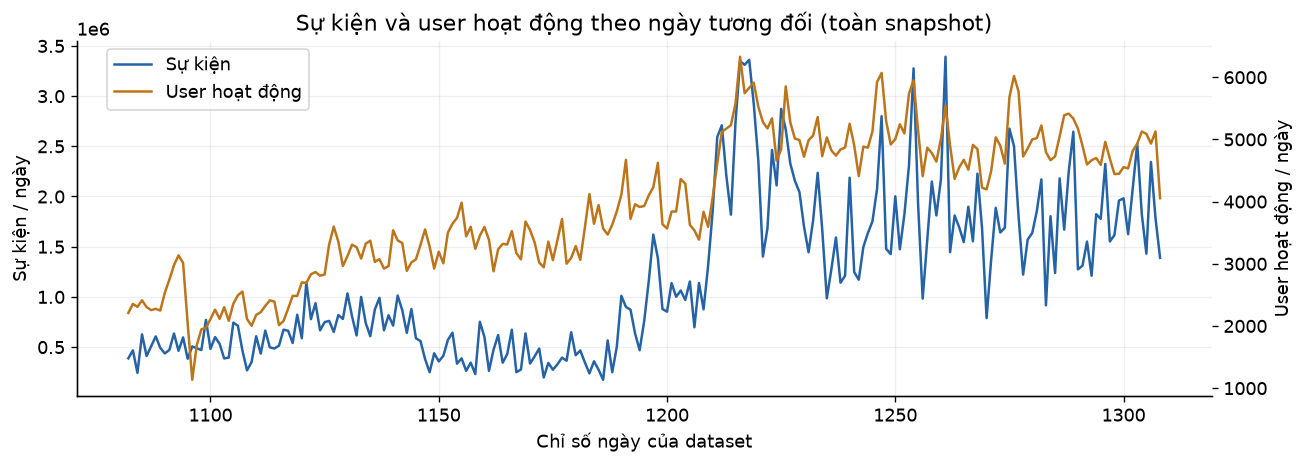

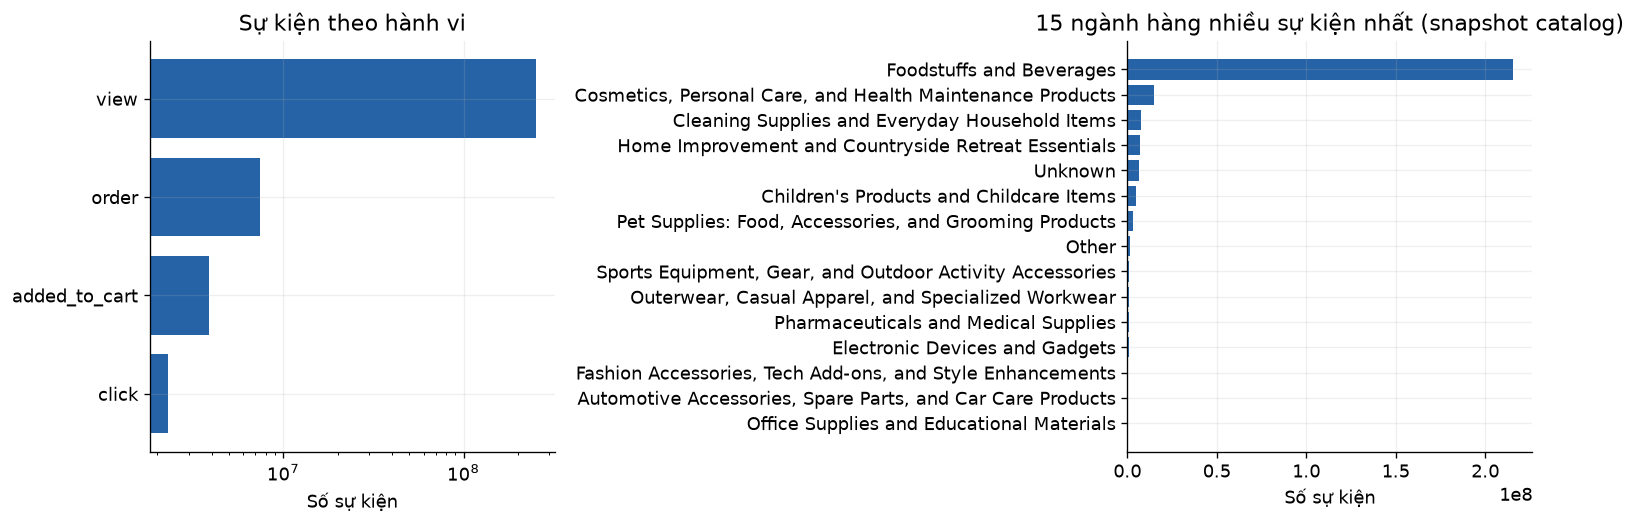

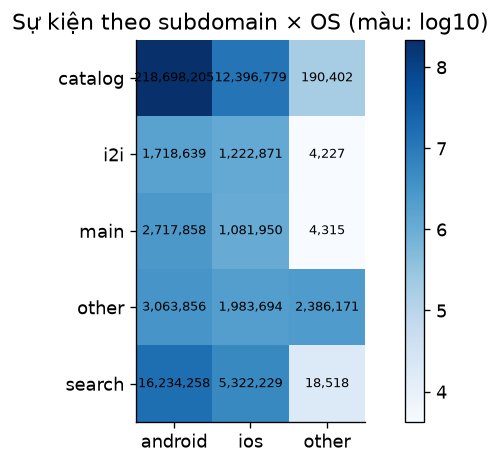

**Quan sát:** 267,043,972 sự kiện; 140,062 user; 257,327 item; 8 brand (gồm Unknown). Độ thưa cặp user–item: **99.8308%**. Ngành hàng/brand theo snapshot catalog hiện có, không khẳng định thuộc tính tại thời điểm sự kiện. Đây là thống kê toàn phạm vi, không dùng để chọn tham số mô hình.

In [12]:
daily_pd=AGG['agg_daily'].sort_values('day_index')
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(daily_pd['day_index'],daily_pd['events'],color=COLORS['ALS'],label='Sự kiện')
ax2=ax.twinx(); ax2.plot(daily_pd['day_index'],daily_pd['active_users'],color=COLORS['Popularity'],label='User hoạt động')
ax.set(title='Sự kiện và user hoạt động theo ngày tương đối (toàn snapshot)',xlabel='Chỉ số ngày của dataset',ylabel='Sự kiện / ngày')
ax2.set_ylabel('User hoạt động / ngày'); ax2.grid(False)
fig.legend(loc='upper left',bbox_to_anchor=(0.08,0.9)); fig.tight_layout(); plt.show()
behavior_pd=AGG['agg_daily_action'].groupby('action_type')['events'].sum().sort_values()
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
axes[0].barh(behavior_pd.index,behavior_pd.values,color=COLORS['ALS'])
axes[0].set(title='Sự kiện theo hành vi',xlabel='Số sự kiện',xscale='log')
category=AGG['agg_category_action'].groupby('category')['events'].sum().sort_values().tail(15)
axes[1].barh(category.index,category.values,color=COLORS['ALS'])
axes[1].set(title='15 ngành hàng nhiều sự kiện nhất (snapshot catalog)',xlabel='Số sự kiện')
fig.tight_layout(); plt.show()
context=AGG['agg_context_action'].pivot_table(index='subdomain',columns='os',values='events',aggfunc='sum',fill_value=0)
fig,ax=plt.subplots(figsize=(7,4))
image=ax.imshow(np.log10(context.values+1),cmap='Blues')
ax.set_xticks(range(len(context.columns)),context.columns); ax.set_yticks(range(len(context.index)),context.index)
for (i,j),value in np.ndenumerate(context.values): ax.text(j,i,f'{value:,.0f}',ha='center',va='center',fontsize=8)
ax.set(title='Sự kiện theo subdomain × OS (màu: log10)'); ax.grid(False); fig.colorbar(image,ax=ax)
fig.tight_layout(); plt.show()
brands=AGG['agg_brand_action'].groupby('brand_id')['events'].sum().sort_values(ascending=False)
display(Markdown(f"**Quan sát:** {int(overview['events']):,} sự kiện; {int(overview['users']):,} user; {int(overview['items']):,} item; "
 f"{len(brands):,} brand (gồm Unknown). Độ thưa cặp user–item: **{sparsity:.4%}**. "
 'Ngành hàng/brand theo snapshot catalog hiện có, không khẳng định thuộc tính tại thời điểm sự kiện. '
 'Đây là thống kê toàn phạm vi, không dùng để chọn tham số mô hình.'))

### Bước 7.4 — Long-tail, hoạt động user/item và chất lượng catalog

**Mục đích.** Quan sát độ lệch phân bố và mức thiếu catalog; không gắn nhãn doanh thu/conversion.

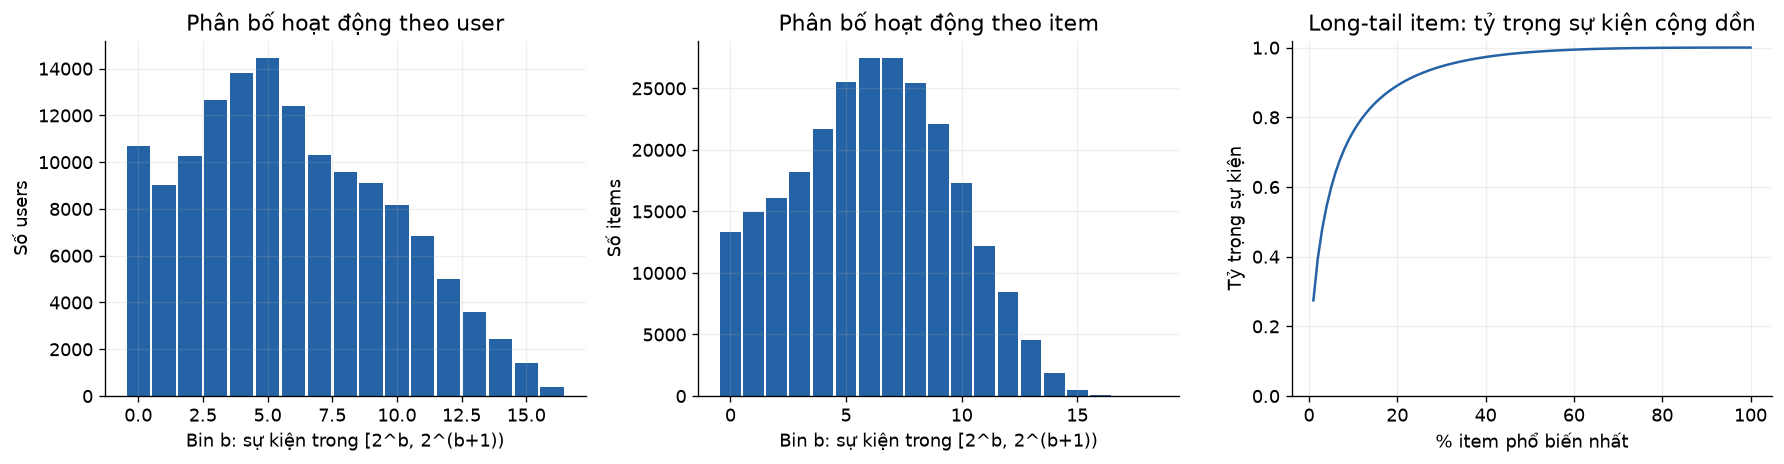

,events,share
catalog_present,,
False,14097,0.000053
True,267029875,0.999947


**Long-tail:** 1% item phổ biến nhất chiếm **27.4%** sự kiện. Item thiếu catalog: 8,521 item, 14,097 sự kiện; catalog thiếu category: 9,615; price null: 725; price âm: 248,431 (giữ price_raw, không tính doanh thu).

In [13]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,(table,label) in zip(axes[:2],[('agg_user_activity','users'),('agg_item_activity','items')]):
    hist=AGG[table].sort_values('log2_bin')
    ax.bar(hist['log2_bin'],hist[label],width=0.9,color=COLORS['ALS'])
    ax.set(title=f'Phân bố hoạt động theo {"user" if label=="users" else "item"}',xlabel='Bin b: sự kiện trong [2^b, 2^(b+1))',ylabel='Số '+label)
tail=AGG['agg_item_long_tail'].sort_values('item_percentile')
tail['cumulative_share']=tail['events'].cumsum()/tail['events'].sum()
axes[2].plot(tail['item_percentile'],tail['cumulative_share'],color=COLORS['ALS'])
axes[2].set(title='Long-tail item: tỷ trọng sự kiện cộng dồn',xlabel='% item phổ biến nhất',ylabel='Tỷ trọng sự kiện',ylim=(0,1.02))
fig.tight_layout(); plt.show()
coverage=AGG['agg_catalog_coverage'].groupby('catalog_present')[['events']].sum()
coverage['share']=coverage['events']/coverage['events'].sum()
display(coverage)
top1=float(tail.loc[tail['item_percentile']<=1,'events'].sum()/tail['events'].sum())
display(Markdown(f'**Long-tail:** 1% item phổ biến nhất chiếm **{top1:.1%}** sự kiện. '
 f"Item thiếu catalog: {silver_quality['event_items_missing_catalog']:,} item, {silver_quality['events_missing_catalog']:,} sự kiện; "
 f"catalog thiếu category: {silver_quality['catalog_category_missing']:,}; price null: {silver_quality['catalog_price_missing']:,}; "
 f"price âm: {silver_quality['catalog_price_negative']:,} (giữ price_raw, không tính doanh thu)."))

**Kết quả và nhận xét.** Các thống kê dưới đây là toàn snapshot (gồm cả cửa sổ test), chỉ dùng để mô tả dữ liệu, không dùng chọn tham số.

- **Theo thời gian:** trung bình 1,18 triệu sự kiện/ngày, dao động 173.718–3.391.436. Hoạt động tăng rõ từ khoảng ngày 1194: trung bình theo khối 4 tuần tăng từ 0,45–0,73 triệu sự kiện/ngày (ngày 1082–1193) lên 1,68–1,90 triệu (ngày 1194–1308); user hoạt động/ngày tăng từ khoảng 2.300–3.500 lên 4.500–5.100. Validation và test nằm trong giai đoạn hoạt động cao, còn lịch sử train trộn hai chế độ hoạt động.
- **Ngành hàng:** 21 category (gồm Unknown). *Foodstuffs and Beverages* chiếm 80,7% sự kiện, tiếp theo *Cosmetics, Personal Care…* 5,6% và *Cleaning Supplies…* 2,9%. Tỷ lệ `order` trên tổng sự kiện của ngành cao nhất ở *Home Improvement…* (6,4%); thực phẩm 2,9%. Đây là dữ liệu hàng tiêu dùng nhanh (mọi `item_id` có tiền tố `fmcg_`), loại hàng thường được mua lặp lại.
- **Brand:** chỉ có 7 `brand_id` (cộng Unknown); 4 brand lớn nhất chiếm 88,3% sự kiện. Với 250 nghìn sản phẩm, thuộc tính này quá thô để phân biệt sản phẩm và không đủ cơ sở kết luận về thương hiệu.
- **Context:** tổ hợp android × catalog chiếm 81,9% sự kiện (218,7 triệu). Toàn bộ `order` ghi ở subdomain `other` (xem mục 4.2).
- **Long-tail item:** 1% item phổ biến nhất (2.573 item) chiếm 27,4% sự kiện; 10% item chiếm 75,8%, 20% chiếm 89,1%; nửa ít phổ biến nhất chỉ chiếm 1,3%. 13.345 item chỉ có một sự kiện. Mức tập trung này là lý do Popularity là baseline mạnh.
- **Hoạt động user:** lệch rất mạnh. 10.693 user (7,6%) chỉ có một sự kiện, trung vị nằm trong khoảng 32–63 sự kiện, trong khi 4.221 user (3,0%) có từ 16.384 sự kiện trở lên tạo ra 56,4% tổng sự kiện. Strength tính theo số sự kiện vì vậy rất lớn ở nhóm user nặng, điều cần lưu ý khi chọn alpha.
- **Độ thưa và catalog:** 60.987.571 cặp user–item, độ thưa 99,83%; 99,995% sự kiện có thông tin catalog.

<a id="phan-8"></a>

## 8. Gold ML Data Mart — Thiết kế đánh giá và chuẩn bị dữ liệu

### 8.1. Giao thức cố định trước test

Nguồn của ML mart là `gold.fact_interactions` cùng các dimension đã kiểm tra khóa ở mục 7, đọc theo version ghi trong checkpoint. Sự kiện được lọc theo `event_us` trước khi tổng hợp; dashboard aggregates không được dùng làm đầu vào mô hình.

Mặc định 14 ngày cuối là test, 14 ngày trước là validation. Ranh giới đặt tại đầu ngày tương đối. Train có sự kiện **trước** `validation_start - gap`; lịch sử refit có sự kiện **trước** `test_start - gap`. Nhãn dùng cửa sổ nửa mở `[start,end)`. Gap tối thiểu 12 giờ với microsecond; nếu chỉ có ngày dùng một ngày. Sự kiện trong gap trước validation không được fit ở E2 nhưng có thể trở thành lịch sử hợp lệ tại mốc test.

Nhãn là cặp user–item có mua hoàn tất, mỗi item chỉ một lần/user; lịch sử vẫn giữ số sự kiện lặp. Ứng viên là toàn bộ item xuất hiện trong lịch sử hợp lệ, không lấy mẫu. Giao thức chính cho phép mua lại. Giao thức phụ loại item đã tương tác khỏi **cả ứng viên và nhãn** theo user; loại user không còn nhãn và báo số bị loại.

Chỉ số chính tính trên user có lịch sử và có nhãn mua. Item mới vẫn giữ trong mẫu số; tỷ lệ item mới báo theo cặp user–item positive và theo item phân biệt. User mới báo riêng, đánh giá Popularity tham khảo. Không dùng `coldStartStrategy='drop'` để âm thầm loại trường hợp khó khỏi mẫu số.

### 8.2. Công thức

Với nhãn phân biệt $R_u$, danh sách $L_u$ có tối đa $K=10$ item:

$$Recall@K(u)=\frac{|L_u\cap R_u|}{|R_u|},\quad DCG@K(u)=\sum_{j=1}^{|L_u|}\frac{\mathbb{1}[L_{u,j}\in R_u]}{\log_2(j+1)},$$
$$IDCG@K(u)=\sum_{j=1}^{\min(K,|R_u|)}\frac{1}{\log_2(j+1)},\quad NDCG@K(u)=DCG@K(u)/IDCG@K(u).$$

Lấy trung bình **theo user**, mỗi user có trọng số bằng nhau. Thiếu gợi ý nhận điểm 0. Mẫu số Recall gồm cả sản phẩm chưa xuất hiện trong lịch sử [3].

### Bước 8.1 — Chia thời gian và khóa giao thức

**Mục đích.** Chia sự kiện trước khi tổng hợp; chốt cửa sổ trước E2/E1.

In [14]:
first_day,last_day=int(overview['first_day']),int(overview['last_day'])
test_start_day=last_day+1-CFG['test_days']
validation_start_day=test_start_day-CFG['validation_days']
assert first_day<validation_start_day<test_start_day<=last_day
gap_us=CFG['gap_hours']*3_600_000_000
assert gap_us>=12*3_600_000_000
end_us=(last_day+1)*MICROS_PER_DAY
val_start_us=validation_start_day*MICROS_PER_DAY
test_start_us=test_start_day*MICROS_PER_DAY
protocol=lock_value('protocol',{'first_day':first_day,'last_day':last_day,'validation_start_day':validation_start_day,
 'test_start_day':test_start_day,'train_end_exclusive_us':val_start_us-gap_us,'refit_end_exclusive_us':test_start_us-gap_us,
 'gap_us':gap_us,'purchase_action':CFG['purchase_action'],'k':CFG['k'],'source_revision':CFG['source_revision'],
 'manifest_sha256':manifest_hash,'gold_fact_version':VERSIONS['gold.fact_interactions']['version']})
atomic_json(LOCAL/'protocol_lock.json',protocol)

def gold_history(fact_df,action_df,end_exclusive_us):
    """Lịch sử theo cutoff lấy từ fact Gold (grain sự kiện, version đã ghim); lọc thời gian trước mọi phép tổng hợp."""
    return (fact_df.where(F.col('event_us')<end_exclusive_us)
            .join(F.broadcast(action_df.select('action_key','action_type','is_purchase')),'action_key')
            .select('user_key','product_key','action_type','is_purchase','event_us'))

def purchase_labels(start_us,end_us):
    """Nhãn = cặp user–item có sự kiện mua trong cửa sổ; giải mã về ID gốc qua dimension."""
    window=gold_history(fact.where(F.col('event_us')>=start_us),dims['gold.dim_action'],end_us)
    return (window.where('is_purchase').select('user_key','product_key').distinct()
            .join(dims['gold.dim_user'],'user_key').join(dims['gold.dim_product'].select('product_key','item_id'),'product_key')
            .select('user_id','item_id'))

train_events=gold_history(fact,dims['gold.dim_action'],protocol['train_end_exclusive_us'])
refit_events=gold_history(fact,dims['gold.dim_action'],protocol['refit_end_exclusive_us'])
if stage_done('ml_split'): skip('ml_split')
else:
    with running('ml_split'):
        save_delta(purchase_labels(val_start_us,test_start_us),'gold_ml.validation_labels')
        save_delta(purchase_labels(test_start_us,end_us),'gold_ml.test_labels')
        split_counts={'train_events':train_events.count(),'refit_events':refit_events.count(),
            'validation_positive_pairs':read_delta('gold_ml.validation_labels').count(),
            'test_positive_pairs':read_delta('gold_ml.test_labels').count()}
        assert all(v>0 for v in split_counts.values()),'Xem lại cửa sổ trước khi test.'
        set_progress('split_counts',split_counts)
validation_labels=read_delta('gold_ml.validation_labels'); test_labels=read_delta('gold_ml.test_labels')
display(pd.DataFrame([protocol]))
display(pd.DataFrame(progress('split_counts').items(),columns=['Tập','Số dòng']))

2026-10-30 09:20:06 | STAGE_SKIP ml_split: đã hoàn tất lúc 2026-10-29T21:34:43+00:00 (checkpoint)


,first_day,last_day,validation_start_day,test_start_day,train_end_exclusive_us,refit_end_exclusive_us,gap_us,purchase_action,k,source_revision,manifest_sha256,gold_fact_version
0,1082,1308,1281,1295,110635200000000,111844800000000,43200000000,order,10,79bcf78cd4699267f561ad3fd51fe7b52af53083,04b38fb6ed3697b0a46a1d4b2a7a8bada2b4d9a63179d7...,0


,Tập,Số dòng
0,train_events,215925462
1,refit_events,239831885
2,validation_positive_pairs,331273
3,test_positive_pairs,318412


**Kết quả và nhận xét.** Giao thức được khóa trong `protocol_lock.json` trước E2:

| Thành phần | Giá trị |
|---|---|
| Toàn bộ dữ liệu | ngày 1082–1308 (227 ngày) |
| Validation | ngày 1281–1294 (14 ngày) |
| Test | ngày 1295–1308 (14 ngày) |
| Lịch sử train | sự kiện trước đầu ngày 1281 trừ 12 giờ: 215.925.462 sự kiện (80,9%) |
| Lịch sử refit | sự kiện trước đầu ngày 1295 trừ 12 giờ: 239.831.885 sự kiện |
| Cặp user–item có mua (nhãn) | validation 331.273; test 318.412 |

Ngày cuối 1308 có 1,39 triệu sự kiện và 4.053 user, thấp hơn trung bình khối 4 tuần cuối (1,84 triệu) nhưng cùng bậc độ lớn, nên không có dấu hiệu ngày cuối bị cắt dở. Mốc chỉ phụ thuộc độ dài cửa sổ cố định trong cấu hình, không điều chỉnh theo kết quả.

### Bước 8.2 — Ánh xạ Int32, cường độ tương tác, popularity và EDA train trên Gold

**Mục đích.** Đọc fact/dimension Gold trước cutoff và tổng hợp một lần thành `gold_ml.{train,refit}_pair_actions`: một dòng mỗi cặp user–item, số sự kiện từng hành vi, cờ `kept` theo quy tắc rút gọn. EDA train bằng Spark SQL trên Star Schema; bảng `train_eda_reduction` cho số cặp/user/item còn lại ở từng ngưỡng để chọn ngưỡng trên train. Ánh xạ Int32, strength theo profile và popularity lấy từ bảng cặp (không quét lại fact cho mỗi profile); ánh xạ riêng từng lịch sử, không dùng ID validation/test.

2026-10-30 09:20:06 | STAGE_SKIP ml_mart: đã hoàn tất lúc 2026-10-29T21:40:15+00:00 (checkpoint)


,EDA train,Giá trị
0,scope,train: gold.fact_interactions với event_us < t...
1,reduction_rule,bỏ cặp chỉ có view và < 2 lần
2,train_events,215925462
3,pairs_before_reduction,49821178
4,users_before_reduction,126800
5,items_before_reduction,244394
6,users,121092
7,items,221967
8,pairs,20804959
9,pairs_kept_share,0.417593


,action_type,events,users,items
0,order,6200704,55880,132392
1,click,1894421,79475,135006
2,added_to_cart,3170700,78327,134161
3,view,204659637,70138,242548


**Rút gọn train theo ngưỡng** (cặp chỉ có `view` phải có ≥ ngưỡng lần; cặp có click, added_to_cart, order luôn giữ). Ngưỡng đang dùng: **2**.

kept                       kept_share                      \
entity         items       pairs     users      items     pairs     users   
min_events                                                                  
1           244394.0  49821178.0  126800.0   1.000000  1.000000  1.000000   
2           221967.0  20804959.0  121092.0   0.908234  0.417593  0.954984   
3           214557.0  16053235.0  117545.0   0.877914  0.322217  0.927011   
4           209290.0  13977598.0  115839.0   0.856363  0.280555  0.913557   
5           205024.0  12725134.0  114994.0   0.838908  0.255416  0.906893   

           chosen  
entity             
min_events         
1           False  
2            True  
3           False  
4           False  
5           False

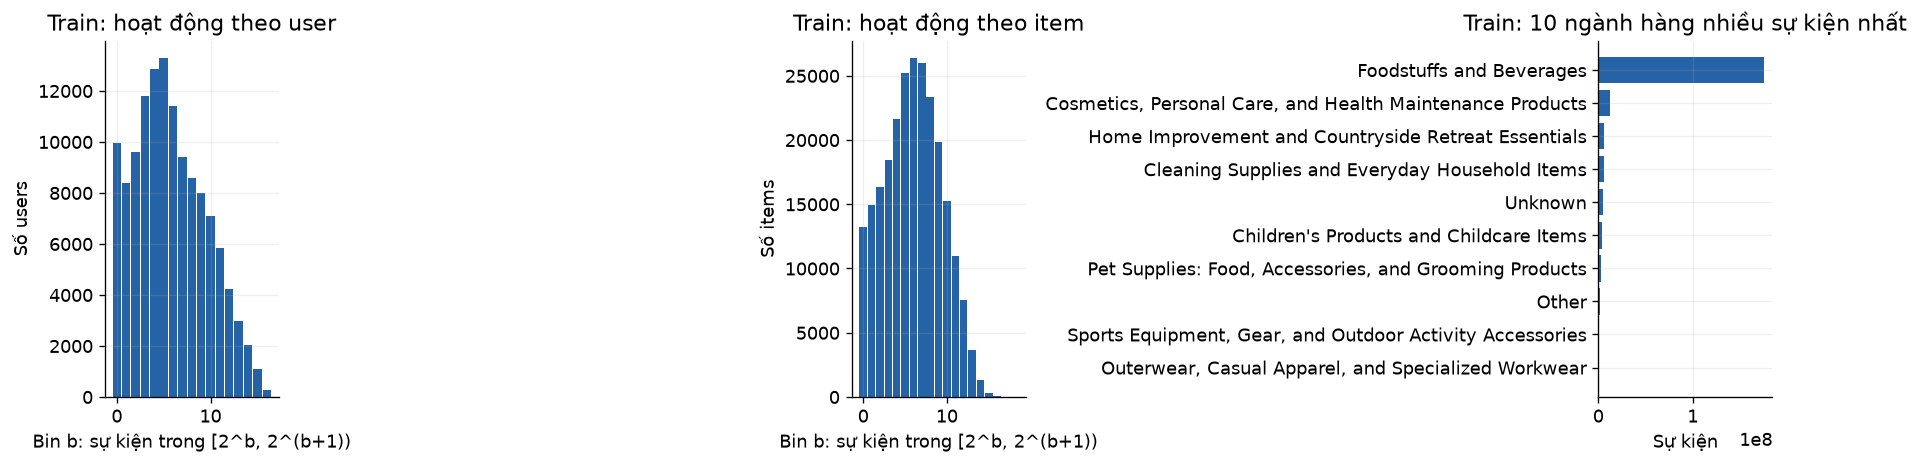

**EDA train từ Gold:** cùng Star Schema với dashboard nhưng giới hạn `event_us < train_end`; trọng số, ngưỡng rút gọn, lưới tham số và quy tắc ứng viên chỉ dựa trên phần này và validation, không dùng test.

In [15]:
def make_index(pairs,key,dim,id_column,output):
    """Index Int32 từ 0 cho ALS, chỉ gồm thực thể còn cặp sau rút gọn, sắp theo ID gốc.

    Khác khóa thay thế của warehouse (đánh trên toàn snapshot); mapping giữ cả hai để truy vết."""
    present=pairs.select(key).distinct()
    return (dim.select(key,id_column).join(present,key)
            .withColumn(output,(F.row_number().over(Window.orderBy(id_column))-1).cast('int'))
            .select(id_column,key,output))

REDUCE=CFG['ml_reduction']
OTHER_ACTIONS=[a for a in CFG['actions'] if a!=REDUCE['action']]

def pair_actions(events):
    """Một dòng/cặp user–item: số sự kiện từng hành vi; kept=False khi cặp chỉ có hành vi rút gọn dưới ngưỡng."""
    counts=[F.sum((F.col('action_type')==a).cast('long')).alias(a+'_events') for a in CFG['actions']]
    other=sum(F.col(a+'_events') for a in OTHER_ACTIONS)
    return (events.groupBy('user_key','product_key').agg(*counts)
            .withColumn('kept',(other>0)|(F.col(REDUCE['action']+'_events')>=REDUCE['min_events'])))

def kept_pairs(name): return read_delta(name).where('kept')

def weighted_pairs(pairs,user_map,item_map,weights):
    strength=sum(F.lit(float(weights[a]))*F.col(a+'_events') for a in CFG['actions'])
    return (pairs.select('user_key','product_key',strength.alias('interaction_strength'))
     .join(F.broadcast(user_map.select('user_key','user_index')),'user_key')
     .join(F.broadcast(item_map.select('product_key','item_index')),'product_key')
     .select('user_index','item_index','interaction_strength'))

def purchase_popularity(pairs,item_map):
    counts=pairs.groupBy('product_key').agg(F.sum(CFG['purchase_action']+'_events').alias('purchase_events'))
    return (item_map.join(counts,'product_key','left').fillna({'purchase_events':0})
            .select('item_index','item_id','purchase_events'))

user_dim,product_dim=dims['gold.dim_user'],dims['gold.dim_product']
MART_TABLES=[
 ('gold_ml.train_pair_actions',lambda: pair_actions(train_events)),
 ('gold_ml.refit_pair_actions',lambda: pair_actions(refit_events)),
 ('gold_ml.train_user_index',lambda: make_index(kept_pairs('gold_ml.train_pair_actions'),'user_key',user_dim,'user_id','user_index')),
 ('gold_ml.train_item_index',lambda: make_index(kept_pairs('gold_ml.train_pair_actions'),'product_key',product_dim,'item_id','item_index')),
 ('gold_ml.refit_user_index',lambda: make_index(kept_pairs('gold_ml.refit_pair_actions'),'user_key',user_dim,'user_id','user_index')),
 ('gold_ml.refit_item_index',lambda: make_index(kept_pairs('gold_ml.refit_pair_actions'),'product_key',product_dim,'item_id','item_index')),
 *[('gold_ml.train_user_item_strength_'+profile,
    lambda weights=weights: weighted_pairs(kept_pairs('gold_ml.train_pair_actions'),read_delta('gold_ml.train_user_index'),
                                           read_delta('gold_ml.train_item_index'),weights))
   for profile,weights in CFG['weight_profiles'].items()],
 ('gold_ml.train_item_popularity',lambda: purchase_popularity(read_delta('gold_ml.train_pair_actions'),read_delta('gold_ml.train_item_index'))),
 ('gold_ml.refit_item_popularity',lambda: purchase_popularity(read_delta('gold_ml.refit_pair_actions'),read_delta('gold_ml.refit_item_index'))),
]
# EDA phục vụ quyết định mô hình: Spark SQL trên Star Schema, chỉ phần train (R10).
TRAIN_CUT=protocol['train_end_exclusive_us']
OTHER_SUM='+'.join(a+'_events' for a in OTHER_ACTIONS)
TRAIN_EDA_SQL={
 'gold_ml.train_eda_actions':f"""SELECT a.action_type, COUNT(*) AS events, COUNT(DISTINCT f.user_key) AS users,
    COUNT(DISTINCT f.product_key) AS items FROM fact_interactions f JOIN dim_action a ON f.action_key = a.action_key
    WHERE f.event_us < {TRAIN_CUT} GROUP BY a.action_type""",
 'gold_ml.train_eda_category':f"""SELECT COALESCE(p.category, 'Unknown') AS category, p.catalog_present, COUNT(*) AS events,
    COUNT(DISTINCT f.user_key) AS users, COUNT(DISTINCT f.product_key) AS items
    FROM fact_interactions f JOIN dim_product p ON f.product_key = p.product_key
    WHERE f.event_us < {TRAIN_CUT} GROUP BY COALESCE(p.category, 'Unknown'), p.catalog_present""",
 'gold_ml.train_eda_context':f"""SELECT c.os, c.subdomain, COUNT(*) AS events, COUNT(DISTINCT f.user_key) AS users
    FROM fact_interactions f JOIN dim_context c ON f.context_key = c.context_key
    WHERE f.event_us < {TRAIN_CUT} GROUP BY c.os, c.subdomain""",
 'gold_ml.train_eda_user_activity':f"""SELECT CAST(FLOOR(LOG2(events)) AS INT) AS log2_bin, COUNT(*) AS users, SUM(events) AS events
    FROM (SELECT user_key, COUNT(*) AS events FROM fact_interactions WHERE event_us < {TRAIN_CUT} GROUP BY user_key) GROUP BY 1""",
 'gold_ml.train_eda_item_activity':f"""SELECT CAST(FLOOR(LOG2(events)) AS INT) AS log2_bin, COUNT(*) AS items, SUM(events) AS events
    FROM (SELECT product_key, COUNT(*) AS events FROM fact_interactions WHERE event_us < {TRAIN_CUT} GROUP BY product_key) GROUP BY 1""",
 # level = số lần của hành vi rút gọn nếu cặp chỉ có hành vi đó; cặp có hành vi khác luôn được giữ (level 6 = "≥6 hoặc luôn giữ").
 'gold_ml.train_eda_reduction':f"""WITH p AS (SELECT user_key, product_key,
        CASE WHEN {OTHER_SUM} > 0 THEN 6 ELSE LEAST({REDUCE['action']}_events, 6) END AS level FROM train_pair_actions),
     lv AS (SELECT 'pairs' AS entity, level FROM p
        UNION ALL SELECT 'users', MAX(level) FROM p GROUP BY user_key
        UNION ALL SELECT 'items', MAX(level) FROM p GROUP BY product_key),
     c AS (SELECT entity, level, COUNT(*) AS n FROM lv GROUP BY entity, level)
    SELECT entity, level AS min_events, SUM(n) OVER (PARTITION BY entity ORDER BY level DESC) AS kept,
        SUM(n) OVER (PARTITION BY entity) AS total FROM c""",
}
def train_sql(sql):
    read_delta('gold_ml.train_pair_actions').createOrReplaceTempView('train_pair_actions')
    return spark.sql(sql)

if stage_done('ml_mart'): skip('ml_mart')
else:
    with running('ml_mart'):
        done=set(progress('ml_mart_tables',[]))
        builders=MART_TABLES+[(name,lambda sql=sql: train_sql(sql)) for name,sql in TRAIN_EDA_SQL.items()]
        for name,build in builders:
            if name in done: continue
            started=time.perf_counter()
            save_delta(build(),name); entry=VERSIONS[name]
            done.add(name); set_progress('ml_mart_tables',sorted(done))
            log(f"ML_MART {name}: {entry['written_rows']:,} dòng, {time.perf_counter()-started:.1f}s")
        for name in ['gold_ml.train_user_index','gold_ml.train_item_index','gold_ml.refit_user_index','gold_ml.refit_item_index']:
            assert VERSIONS[name]['written_rows']<=2_147_483_647,'Vượt miền Int32 của backend.'
        pairs=read_delta('gold_ml.train_user_item_strength_uniform')  # uniform = số sự kiện của cặp đã giữ
        users=VERSIONS['gold_ml.train_user_index']['written_rows']; items=VERSIONS['gold_ml.train_item_index']['written_rows']
        n_pairs=VERSIONS['gold_ml.train_user_item_strength_uniform']['written_rows']
        before={r.entity:int(r.total) for r in read_delta('gold_ml.train_eda_reduction').select('entity','total').distinct().collect()}
        assert before['pairs']==VERSIONS['gold_ml.train_pair_actions']['written_rows']
        q=[0.5,0.9,0.99]
        per_user=pairs.groupBy('user_index').agg(F.sum('interaction_strength').alias('events'),F.count('*').alias('items'))
        per_item=pairs.groupBy('item_index').agg(F.sum('interaction_strength').alias('events'),F.count('*').alias('users'))
        set_progress('train_eda',{'scope':'train: gold.fact_interactions với event_us < train_end_exclusive_us',
            'reduction_rule':f"bỏ cặp chỉ có {REDUCE['action']} và < {REDUCE['min_events']} lần",
            'train_events':progress('split_counts')['train_events'],
            'pairs_before_reduction':before['pairs'],'users_before_reduction':before['users'],'items_before_reduction':before['items'],
            'users':users,'items':items,'pairs':n_pairs,'pairs_kept_share':n_pairs/before['pairs'],
            'sparsity':1-n_pairs/(users*items),
            'user_events_p50_p90_p99':per_user.approxQuantile('events',q,0.001),
            'user_items_p50_p90_p99':per_user.approxQuantile('items',q,0.001),
            'item_events_p50_p90_p99':per_item.approxQuantile('events',q,0.001),
            'item_users_p50_p90_p99':per_item.approxQuantile('users',q,0.001)})
train_users=read_delta('gold_ml.train_user_index'); train_items=read_delta('gold_ml.train_item_index')
refit_users=read_delta('gold_ml.refit_user_index'); refit_items=read_delta('gold_ml.refit_item_index')
train_pairs={p:read_delta('gold_ml.train_user_item_strength_'+p) for p in CFG['weight_profiles']}
train_eda=progress('train_eda')
atomic_json(LOCAL/'train_eda.json',train_eda)
display(pd.DataFrame([(k,v) for k,v in train_eda.items()],columns=['EDA train','Giá trị']))
TRAIN_EDA={name.split('.')[1]:read_delta(name).toPandas() for name in TRAIN_EDA_SQL}
display(TRAIN_EDA['train_eda_actions'])
reduction=TRAIN_EDA['train_eda_reduction'].query('min_events <= 5').copy()
reduction['kept_share']=reduction['kept']/reduction['total']
reduction_table=reduction.pivot(index='min_events',columns='entity',values=['kept','kept_share'])
reduction_table['chosen']=reduction_table.index==REDUCE['min_events']
display(Markdown(f"**Rút gọn train theo ngưỡng** (cặp chỉ có `{REDUCE['action']}` phải có ≥ ngưỡng lần; "
                 f"cặp có {', '.join(OTHER_ACTIONS)} luôn giữ). Ngưỡng đang dùng: **{REDUCE['min_events']}**."))
display(reduction_table)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,(table,label) in zip(axes[:2],[('train_eda_user_activity','users'),('train_eda_item_activity','items')]):
    hist=TRAIN_EDA[table].sort_values('log2_bin')
    ax.bar(hist['log2_bin'],hist[label],width=0.9,color=COLORS['ALS'])
    ax.set(title=f'Train: hoạt động theo {"user" if label=="users" else "item"}',xlabel='Bin b: sự kiện trong [2^b, 2^(b+1))',ylabel='Số '+label)
top=TRAIN_EDA['train_eda_category'].groupby('category')['events'].sum().sort_values().tail(10)
axes[2].barh(top.index,top.values,color=COLORS['ALS']); axes[2].set(title='Train: 10 ngành hàng nhiều sự kiện nhất',xlabel='Sự kiện')
fig.tight_layout(); plt.show()
display(Markdown('**EDA train từ Gold:** cùng Star Schema với dashboard nhưng giới hạn `event_us < train_end`; '
 'trọng số, ngưỡng rút gọn, lưới tham số và quy tắc ứng viên chỉ dựa trên phần này và validation, không dùng test.'))

**Kết quả và nhận xét.** EDA chỉ tính trên train (215.925.462 sự kiện).

- **Rút gọn:** trước rút gọn có 49.821.178 cặp user–item của 126.800 user và 244.394 item. Ngưỡng 2 giữ 20.804.959 cặp (41,8%), 121.092 user (95,5%) và 221.967 item (90,8%): bỏ 58,2% số cặp (cặp chỉ xem đúng một lần) mà chỉ mất 4,5% user. Nâng ngưỡng lên 3–5 chỉ bỏ thêm 9,5–16,2 điểm phần trăm số cặp nhưng mất thêm 2,8–4,8 điểm phần trăm user, nên ngưỡng 2 là điểm cân bằng giữa thời gian fit và số user nhận gợi ý ALS.
- **Ma trận huấn luyện:** 121.092 × 221.967 với độ thưa 99,92%. Trung vị một user tương tác 25 item (p90: 457, p99: 2.167); trung vị một item có 12 user (p90: 211, p99: 1.259). Tổng strength của một user có trung vị 48 nhưng p99 tới 30.486, chênh lệch ba bậc độ lớn giữa user thường và user nặng.
- **Hành vi:** chỉ 70.138 trong 126.800 user train có `view`, trong khi `click` và `added_to_cart` có ở khoảng 78–79 nghìn user và `order` ở 55.880 user. Một phần lớn user không có lượt xem được ghi nhận, nên không thể coi view là bước bắt buộc trước khi mua; giữ mọi cặp có click/added_to_cart/order khi rút gọn là cần thiết.

### Bước 8.3 — Population, nhãn và cold-start

**Mục đích.** Cố định user đánh giá độc lập với mô hình; giữ item mới trong nhãn.

In [16]:
val_truth,val_population=gpu_evaluation_population(spark,validation_labels,train_users,train_items)
display(pd.DataFrame([val_population]))

,positive_users,cold_users,eligible_users,removed_no_novel_labels,positive_pairs,new_item_positive_pairs,label_items,new_label_items,cold_user_rate,new_item_pair_rate,new_item_distinct_rate
0,13709,2175,11534,0,285948,1477,54667,770,0.158655,0.005165,0.014085


**Kết quả và nhận xét.** Validation có 13.709 user mua hàng. 2.175 user (15,9%) không có trong index train (user mới hoặc mất hết cặp sau rút gọn) được báo riêng; 11.534 user còn lại đủ điều kiện, với 285.948 cặp nhãn trên 54.667 item. Item chưa xuất hiện trong lịch sử train chỉ chiếm 0,52% cặp nhãn (1,41% item phân biệt), nên giới hạn “không gợi ý được item mới” của lọc cộng tác ảnh hưởng rất ít. Trung bình mỗi user đủ điều kiện mua khoảng 24,8 item khác nhau trong 14 ngày, nhiều hơn K = 10, nên Recall@10 bị chặn trên rõ rệt dưới 1.

<a id="phan-9"></a>

## 9. Xây dựng Popularity Baseline

Điểm tính lại từ lịch sử tại mỗi mốc: train cho validation, refit cho test. Mỗi `order` hợp lệ đóng góp một lượt, không nhân số lượng hàng và không đếm mọi hành vi. Item có lịch sử nhưng chưa mua nhận điểm 0. Giao thức phụ duyệt danh sách phổ biến toàn cục và bỏ item user đã thấy (CSR lịch sử đầy đủ, gồm cả cặp bị rút gọn), nên kết quả là Top-K đúng trên toàn bộ ứng viên. Rút gọn không đổi điểm vì mọi cặp có `order` đều được giữ. Popularity cũng là fallback cho user không có lịch sử trước cutoff, hoặc mất hết cặp sau rút gọn, khi phát hành gợi ý.

### Bước 9.1 — Hàm chỉ số và ví dụ kiểm tra

**Mục đích.** Macro theo user; user thiếu gợi ý nhận 0. Ví dụ tự tạo chỉ kiểm tra code, không phải kết quả Retail.

In [17]:
def as_lists(recs):
    """Bảng gợi ý dạng dài (user_id, rank, item_id, score) → mảng item theo rank."""
    return (recs.groupBy('user_id').agg(F.sort_array(F.collect_list(F.struct('rank','item_id'))).alias('_ranked'))
            .select('user_id',F.expr('transform(_ranked, x -> x.item_id)').alias('recommendations')))

def per_user_metrics(recs,truth,k=None):
    """Recall@K và NDCG@K của từng user trong truth; user thiếu gợi ý nhận 0."""
    k=k or CFG['k']
    empty=F.array().cast('array<string>')
    joined=(truth.join(as_lists(recs),'user_id','left')
      .withColumn('recommendations',F.slice(F.coalesce('recommendations',empty),1,k)))
    hits=F.size(F.array_intersect('recommendations','labels'))
    dcg=F.expr("""aggregate(transform(recommendations,(x,j) ->
      IF(array_contains(labels,x),1D/log2(j+2D),0D)),0D,(s,x) -> s+x)""")
    idcg=F.expr(f'aggregate(sequence(1,least({k},size(labels))),0D,(s,j) -> s+1D/log2(j+1D))')
    return joined.select('user_id',(hits/F.size('labels')).alias('recall'),(dcg/idcg).alias('ndcg'))

def ranking_metrics(recs,truth,k=None):
    row=per_user_metrics(recs,truth,k).agg(F.count('*').alias('users'),F.avg('recall').alias('recall_at_10'),
                     F.avg('ndcg').alias('ndcg_at_10')).first().asDict()
    if row['users']: assert 0<=row['recall_at_10']<=1 and 0<=row['ndcg_at_10']<=1.0000001
    return row
example_truth=spark.createDataFrame([('u1',['a','b','c']),('u2',['x'])],'user_id string, labels array<string>')
example_recs=spark.createDataFrame([('u1',1,'a',3.),('u1',2,'z',2.),('u1',3,'b',1.)],'user_id string, rank int, item_id string, score double')
example_metric=ranking_metrics(example_recs,example_truth)
assert abs(example_metric['recall_at_10']-(2/3)/2)<1e-9
expected_ndcg=((1+1/math.log2(4))/(1+1/math.log2(3)+1/math.log2(4)))/2
assert abs(example_metric['ndcg_at_10']-expected_ndcg)<1e-9
print('Kiểm tra Recall/NDCG trên ví dụ tự tạo: đạt; không phải kết quả Retail.')

Kiểm tra Recall/NDCG trên ví dụ tự tạo: đạt; không phải kết quả Retail.


### Bước 9.2 — Gợi ý Popularity

**Mục đích.** Xếp hạng theo số mua lịch sử và item index tăng dần khi đồng điểm.

In [18]:
def popularity_ranking(table):
    """Thứ tự toàn cục: số sự kiện mua giảm dần, item_index tăng dần khi đồng điểm."""
    pop=read_delta(table).toPandas()
    order=np.lexsort((pop['item_index'].to_numpy(),-pop['purchase_events'].to_numpy()))
    return (pop['item_id'].to_numpy()[order],pop['item_index'].to_numpy()[order].tolist(),
            pop['purchase_events'].to_numpy()[order].astype(float))

def popularity_rows(user_ids,ranking,seen=None,user_index=None,k=None):
    """Top-K phổ biến; giao thức item mới bỏ item user đã thấy (CSR lịch sử) khỏi ứng viên."""
    k=k or CFG['k']
    item_ids,item_idx,scores=ranking
    for user in user_ids:
        if seen is None:
            chosen=range(min(k,len(item_ids)))
        else:
            row=user_index[user]
            known=set(seen.indices[seen.indptr[row]:seen.indptr[row+1]].tolist())
            chosen=[]
            for position,index in enumerate(item_idx):
                if index not in known:
                    chosen.append(position)
                    if len(chosen)==k: break
        for rank,position in enumerate(chosen,1):
            yield (user,rank,item_ids[position],float(scores[position]))

def sorted_users(truth): return [r.user_id for r in truth.select('user_id').orderBy('user_id').toLocalIterator()]

if stage_done('popularity_validation'): skip('popularity_validation')
else:
    with running('popularity_validation'):
        pop_val=rows_to_delta(popularity_rows(sorted_users(val_truth),popularity_ranking('gold_ml.train_item_popularity')),
                              'results.validation_popularity_recs',REC_SCHEMA)
        set_progress('popularity_validation',ranking_metrics(pop_val,val_truth))
pop_val_metrics=progress('popularity_validation')
display(pd.DataFrame([{'model':'Popularity','split':'validation',**pop_val_metrics}]))

2026-10-30 09:20:32 | STAGE_SKIP popularity_validation: đã hoàn tất lúc 2026-10-29T21:40:40+00:00 (checkpoint)


,model,split,users,recall_at_10,ndcg_at_10
0,Popularity,validation,11534,0.066197,0.174091


**Kết quả và nhận xét.** Popularity trên validation đạt Recall@10 = 0,0662 và NDCG@10 = 0,1741 trên 11.534 user. NDCG cao hơn Recall nhiều vì mỗi user có trung bình gần 25 item nhãn: mẫu số của Recall là $|R_u|$, còn IDCG chỉ tính tới $\min(K,|R_u|)$. Danh sách luôn đủ 10 item vì có hơn 220 nghìn ứng viên. Đây là mốc ALS phải vượt ở E2.

<a id="phan-10"></a>

## 10. Huấn luyện và lựa chọn ALS — E2

Khảo sát tích Descartes của `rank`, `regParam`, `alpha`, profile trọng số ở phần 3: mặc định 16 cấu hình. Mọi cấu hình dùng chung train/validation, seed, maxIter và backend CUDA. Chọn theo NDCG@10 giao thức chính; đồng điểm dùng Recall@10, rồi mã cấu hình theo thứ tự từ điển. Không dùng test hoặc thời gian dao động để phá hòa.

Sinh Top-N trên GPU bằng tích vô hướng factor, duyệt toàn bộ item theo tile 64 user × 8192 item. Giao thức phụ đặt điểm item đã thấy thành âm vô cùng từ CSR. Chọn Top-10 theo score giảm rồi item index tăng, kể cả hòa điểm ở ranh giới; hợp nhất Top-10 từng tile để có kết quả chính xác toàn tập ứng viên. Không tạo ma trận điểm đặc toàn bộ user × item và không mở rộng fetch theo lịch sử dài nhất.

### Bước 10.1 — Fit ALS và sinh Top-N

**Mục đích.** Dùng CUDA ALS với confidence `1 + alpha*r`; đồng bộ GPU trước khi dừng đồng hồ. Tổng thời gian fit gồm chuẩn bị CSR và truyền dữ liệu; CUDA fit thuần được ghi riêng.

In [19]:
def fit_als(pairs,params):
    return GpuALSModel.fit(pairs,params,LOCAL/'csr_cache',iterations=CFG['max_iter'],seed=CFG['seed'])

def als_rows(model,users,user_map,item_map,novel=False,seen=None):
    indexed=users.select('user_id').distinct().join(user_map,'user_id')
    ids={int(r.user_index):r.user_id for r in indexed.toLocalIterator()}
    items=np.empty(model.strengths.shape[1],dtype=object)
    count=0
    for r in item_map.toLocalIterator():
        items[int(r.item_index)]=r.item_id; count+=1
    assert count==len(items),'Item map khác ma trận đã fit.'
    for user,recs,scores in model.recommend_indices(sorted(ids),CFG['k'],novel,scored=True,seen=seen):
        for rank,(item,score) in enumerate(zip(recs,scores),1):
            yield (ids[user],rank,items[item],score)

def als_recommend(model,name,users,user_map,item_map,novel=False,seen=None):
    return rows_to_delta(als_rows(model,users,user_map,item_map,novel,seen),name,REC_SCHEMA)

### Bước 10.2 — Chạy lưới validation và khóa lựa chọn

**Mục đích.** Lưu tham số, profile, chỉ số, phiên bản đầu vào và thời gian fit tách khỏi xếp hạng.

In [20]:
GRID=[(profile,rank,reg,alpha) for profile in CFG['weight_profiles']
      for rank,reg,alpha in itertools.product(CFG['als_grid']['rank'],CFG['als_grid']['regParam'],CFG['als_grid']['alpha'])]
if stage_done('e2'): skip('e2')
else:
    with running('e2'):
        e2_rows=progress('e2_rows',[])
        completed={row['config_id'] for row in e2_rows}
        if completed: log(f'E2 resume: {len(completed)}/{len(GRID)} cấu hình đã có checkpoint')
        for profile,rank,reg,alpha in GRID:
            params={'rank':rank,'regParam':reg,'alpha':alpha}
            config_id=f'{profile}_r{rank}_reg{reg}_a{alpha}'
            if config_id in completed: continue
            log(f'E2 {len(completed)+1}/{len(GRID)} {config_id}')
            model,train_seconds=fit_als(train_pairs[profile],params)
            try:
                started=time.perf_counter()
                recs=als_recommend(model,'results.e2_recs_'+config_id.replace('.','p'),val_truth,train_users,train_items)
                metrics=ranking_metrics(recs,val_truth)
                assert metrics['users']>0
                row={'config_id':config_id,'weight_profile':profile,**params,**metrics,
                     'training_seconds':train_seconds,'cuda_fit_seconds':model.metadata['cuda_fit_seconds'],
                     'csr_prepare_seconds':model.metadata['prepare_seconds'],'backend':CFG['backend'],
                     'recommend_evaluate_seconds':time.perf_counter()-started,
                     'maxIter':CFG['max_iter'],'seed':CFG['seed'],'run_id':RUN_ID,
                     'input_version':VERSIONS['gold_ml.train_user_item_strength_'+profile]['version']}
            finally:
                model.close(); del model
            e2_rows.append(row); completed.add(config_id)
            set_progress('e2_rows',e2_rows)
            log(f"E2 {config_id} NDCG@10={row['ndcg_at_10']:.6f} Recall@10={row['recall_at_10']:.6f}")
        E2=save_delta(spark.createDataFrame(e2_rows),'results.e2_validation')
        best=E2.orderBy(F.desc('ndcg_at_10'),F.desc('recall_at_10'),F.asc('config_id')).first().asDict()
        selection=lock_value('selection',{'config_id':best['config_id'],'weight_profile':best['weight_profile'],
            'params':{'rank':int(best['rank']),'regParam':float(best['regParam']),'alpha':float(best['alpha'])},
            'backend':CFG['backend'],'regularization':'constant_l2','selected_on':'validation_ndcg_at_10',
            'validation_ndcg_at_10':float(best['ndcg_at_10']),'protocol_sha256':PROTOCOL_SHA,
            'e2_result_version':VERSIONS['results.e2_validation']['version']})
        atomic_json(LOCAL/'selection_lock.json',selection)
selection=STATE['locks']['selection']
e2_pd=read_delta('results.e2_validation').orderBy(F.desc('ndcg_at_10'),F.desc('recall_at_10'),F.asc('config_id')).toPandas()
best=e2_pd.iloc[0].to_dict()
best_params=selection['params']; best_profile=selection['weight_profile']
MODEL_VERSION=f"{RUN_ID}.{selection['config_id']}.{PROTOCOL_SHA[:8]}"
ARTIFACTS=LOCAL/'artifacts'/MODEL_VERSION
display(e2_pd.head(20)); print('Đã khóa lựa chọn trên validation:',selection['config_id'],'| model_version:',MODEL_VERSION)

2026-10-30 09:20:32 | STAGE_SKIP e2: đã hoàn tất lúc 2026-10-29T21:48:08+00:00 (checkpoint)


,alpha,backend,config_id,csr_prepare_seconds,cuda_fit_seconds,input_version,maxIter,ndcg_at_10,rank,recall_at_10,recommend_evaluate_seconds,regParam,run_id,seed,training_seconds,users,weight_profile
0,10.0,cupy_cuda_cg,uniform_r32_reg0.1_a10.0,0.052210,5.156702,0,10,0.148777,32,0.056182,16.762126,0.10,retail_star_full_v1,42,5.209928,11534,uniform
1,10.0,cupy_cuda_cg,uniform_r32_reg0.05_a10.0,4.241602,5.838045,0,10,0.148716,32,0.056134,17.410303,0.05,retail_star_full_v1,42,10.149108,11534,uniform
2,10.0,cupy_cuda_cg,uniform_r64_reg0.1_a10.0,0.046378,14.231710,0,10,0.128941,64,0.051143,17.157492,0.10,retail_star_full_v1,42,14.279900,11534,uniform
3,10.0,cupy_cuda_cg,uniform_r64_reg0.05_a10.0,0.058436,14.068500,0,10,0.128842,64,0.051111,17.572854,0.05,retail_star_full_v1,42,14.129068,11534,uniform
4,10.0,cupy_cuda_cg,purchase_focused_r32_reg0.1_a10.0,0.092456,5.505092,0,10,0.116049,32,0.048062,16.580006,0.10,retail_star_full_v1,42,5.598720,11534,purchase_focused
5,40.0,cupy_cuda_cg,uniform_r32_reg0.1_a40.0,0.053403,5.166622,0,10,0.115725,32,0.046207,17.369662,0.10,retail_star_full_v1,42,5.220988,11534,uniform
6,10.0,cupy_cuda_cg,purchase_focused_r32_reg0.05_a10.0,6.174771,5.143780,0,10,0.115660,32,0.047890,17.108480,0.05,retail_star_full_v1,42,11.319916,11534,purchase_focused
7,40.0,cupy_cuda_cg,uniform_r32_reg0.05_a40.0,0.049110,5.128986,0,10,0.115629,32,0.046209,16.383447,0.05,retail_star_full_v1,42,5.179240,11534,uniform
8,40.0,cupy_cuda_cg,uniform_r64_reg0.1_a40.0,0.048121,14.183405,0,10,0.096064,64,0.040301,16.844762,0.10,retail_star_full_v1,42,14.233362,11534,uniform
9,40.0,cupy_cuda_cg,uniform_r64_reg0.05_a40.0,0.049817,14.148586,0,10,0.095550,64,0.040046,16.748202,0.05,retail_star_full_v1,42,14.200257,11534,uniform


Đã khóa lựa chọn trên validation: uniform_r32_reg0.1_a10.0 | model_version: retail_star_full_v1.uniform_r32_reg0.1_a10.0.3c2a3e11


### Bước 10.3 — Biểu đồ E2 và nhận xét

**Mục đích.** Đọc bảng đã lưu; chất lượng và thời gian hiển thị riêng.

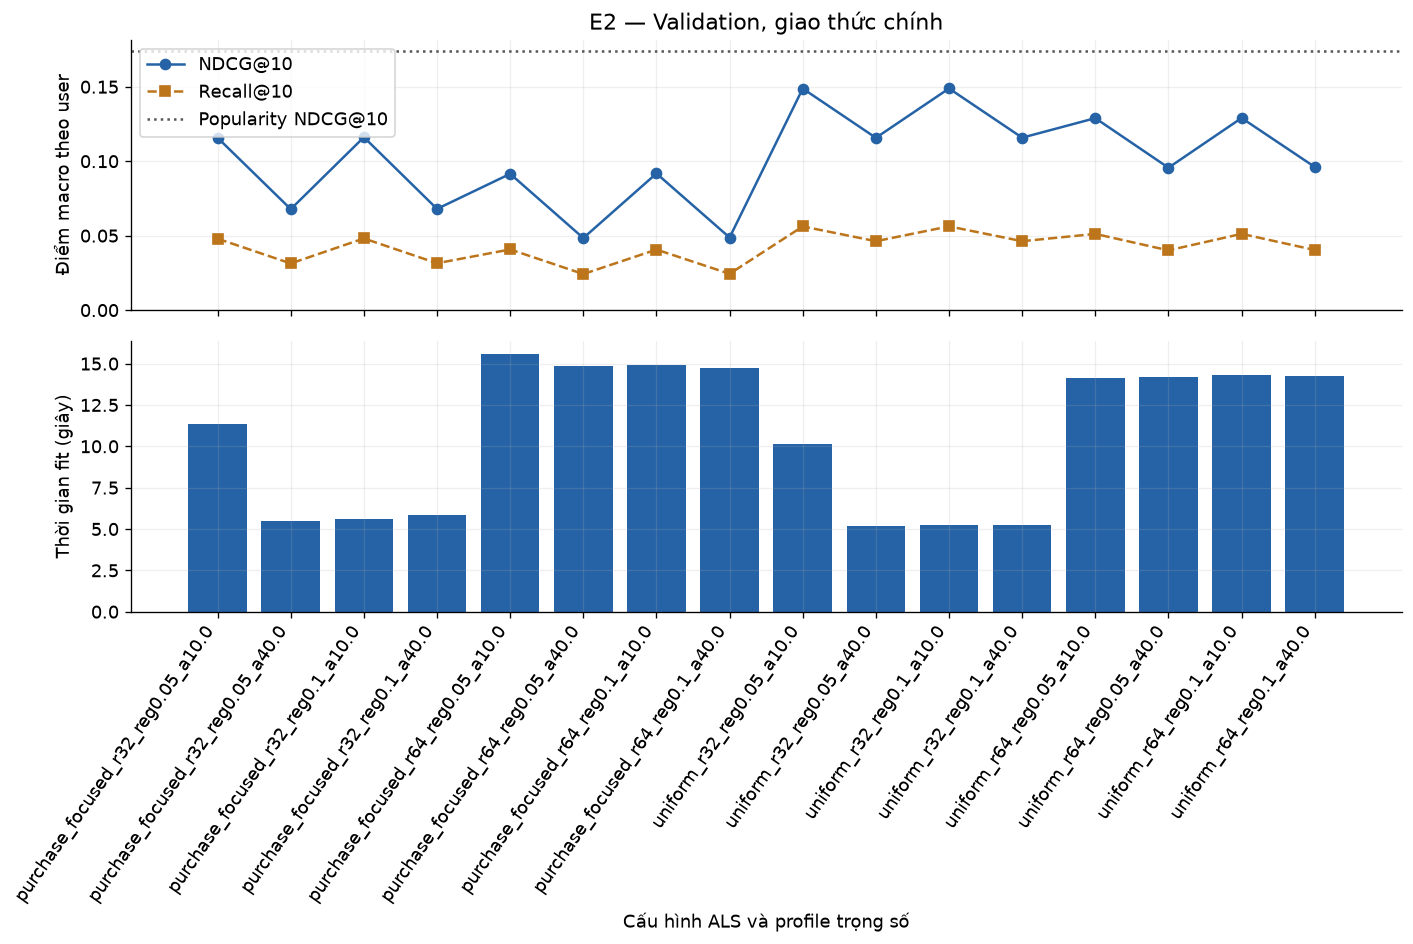

**E2:** chọn `uniform_r32_reg0.1_a10.0`, NDCG@10 **0.148777**, Recall@10 **0.056182**, trên **11,534 user** validation. Đây là lựa chọn trong lưới khảo sát, chưa phải kết luận test hoặc tối ưu toàn cục.

In [21]:
plot_e2=e2_pd.sort_values('config_id').reset_index(drop=True)
x=np.arange(len(plot_e2))
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True)
axes[0].plot(x,plot_e2['ndcg_at_10'],'o-',color=COLORS['ALS'],label='NDCG@10')
axes[0].plot(x,plot_e2['recall_at_10'],'s--',color=COLORS['Popularity'],label='Recall@10')
axes[0].axhline(pop_val_metrics['ndcg_at_10'],color='#555555',linestyle=':',label='Popularity NDCG@10')
axes[0].set(ylabel='Điểm macro theo user',title='E2 — Validation, giao thức chính',ylim=(0,None)); axes[0].legend()
axes[1].bar(x,plot_e2['training_seconds'],color=COLORS['ALS'])
axes[1].set(ylabel='Thời gian fit (giây)',xlabel='Cấu hình ALS và profile trọng số')
axes[1].set_xticks(x,plot_e2['config_id'],rotation=55,ha='right')
fig.tight_layout(); plt.show()
display(Markdown(f"**E2:** chọn `{best['config_id']}`, NDCG@10 **{best['ndcg_at_10']:.6f}**, "
 f"Recall@10 **{best['recall_at_10']:.6f}**, trên **{int(best['users']):,} user** validation. "
 'Đây là lựa chọn trong lưới khảo sát, chưa phải kết luận test hoặc tối ưu toàn cục.'))

**Thảo luận RQ2.** Bảng dưới so sánh các cặp cấu hình chỉ khác một yếu tố, NDCG@10 trên validation. Mỗi yếu tố có 8 cặp so sánh trong lưới.

| Yếu tố thay đổi | Ví dụ (các yếu tố khác giữ nguyên) | NDCG@10 | Chiều tác động |
|---|---|---|---|
| alpha 10 → 40 | uniform, rank 32, reg 0,1 | 0,1488 → 0,1157 | giảm ở 8/8 cặp |
| rank 32 → 64 | uniform, alpha 10, reg 0,1 | 0,1488 → 0,1289 | giảm ở 8/8 cặp |
| uniform → purchase_focused | rank 32, alpha 10, reg 0,1 | 0,1488 → 0,1160 | giảm ở 8/8 cặp |
| regParam 0,05 → 0,1 | uniform, rank 32, alpha 10 | 0,14872 → 0,14878 | tăng rất nhẹ ở 8/8 cặp, \|Δ\| ≤ 0,0006 |

- Ba yếu tố alpha, rank và profile có tác động đơn điệu, nhất quán: confidence thấp hơn, mô hình nhỏ hơn và trọng số đồng đều đều tốt hơn. Cấu hình được chọn `uniform_r32_reg0.1_a10.0` vì vậy nằm ở **góc của lưới**; điểm tối ưu có thể nằm ngoài lưới (rank < 32, alpha < 10). Lưới không được mở rộng sau khi xem test để giữ nguyên giao thức.
- Profile `purchase_focused` và alpha lớn cùng làm tăng confidence của các cặp có nhiều sự kiện. *Giả thuyết (chưa kiểm chứng):* với strength lệch ba bậc độ lớn giữa user thường và user nặng (mục 8.2), confidence tuyến tính `1 + α·r` khiến mô hình khớp quá mức vào các cặp tương tác dày; dạng log $1+\alpha\log(1+r/\varepsilon)$ do Hu và cộng sự [2] đề xuất là hướng thử tiếp theo.
- *Giả thuyết:* regParam trong khoảng 0,05–0,1 quá nhỏ so với tổng confidence của mỗi user/item nên gần như không đổi nghiệm; muốn thấy tác dụng cần khảo sát $\lambda$ ở bậc lớn hơn.
- **Thời gian:** fit CUDA thuần 5,1–5,8 giây với rank 32 và 14,1–15,4 giây với rank 64 (mỗi vòng 0,45 so với 1,33 giây). Rank gấp đôi làm thời gian tăng khoảng 3 lần, nằm giữa mức tuyến tính (×2) và bậc hai (×4), phù hợp chi phí mỗi bước CG gồm phần $O(\text{nnz}\cdot k)$ và $O(n\cdot k^2)$. Alpha, regParam và profile không đổi thời gian fit. Sinh Top-10 và tính chỉ số tốn 16,4–17,6 giây/cấu hình, gần như hằng số; cả lưới 16 cấu hình mất 7,5 phút.
- Ở mọi cấu hình, ALS thấp hơn Popularity trên validation (tốt nhất 0,1488 so với 0,1741). Kết quả này đã được ghi nhận và khóa trước khi chạy test.

<a id="phan-11"></a>

## 11. Đánh giá cuối và minh họa gợi ý — E1

Sau khi khóa lựa chọn, tổng hợp lại lịch sử trước test với gap và refit **một lần**. Popularity tính lại từ cùng lịch sử. Đánh giá chính/phụ, báo cold-start và lưu dự đoán. Dấu hoàn thành giúp chạy lại notebook đọc kết quả E1 đã lưu; không tự fit/test lại. Nếu lần trước dở dang sau khi lưu mô hình, phải đối chiếu log và khôi phục theo cùng cấu hình, không ghi đè để chọn lại tham số.

### Bước 11.1 — Refit và đánh giá test cố định

**Mục đích.** Lưu population và kết quả cùng phiên bản, giữ item cold-start trong nhãn.

In [22]:
REFIT_PAIRS='gold_ml.refit_user_item_strength_'+best_profile
refit_item_count=VERSIONS['gold_ml.refit_item_index']['written_rows']
refit_user_lookup=None

def novel_test_labels():
    """Giao thức phụ: bỏ nhãn user đã thấy trong lịch sử refit đầy đủ, gồm cả cặp bị rút gọn."""
    keyed=(test_labels.join(dims['gold.dim_user'],'user_id')
           .join(dims['gold.dim_product'].select('product_key','item_id'),'item_id'))
    seen=read_delta('gold_ml.refit_pair_actions').join(F.broadcast(keyed.select('user_key','product_key')),
                                                      ['user_key','product_key'],'left_semi')
    return keyed.join(seen,['user_key','product_key'],'left_anti').select('user_id','item_id')

def seen_matrix():
    """CSR lịch sử refit đầy đủ (gồm cặp bị rút gọn) theo index của model, để loại item đã thấy khỏi ứng viên."""
    triples=weighted_pairs(read_delta('gold_ml.refit_pair_actions'),refit_users,refit_items,{a:1. for a in CFG['actions']})
    matrix,_=dataframe_to_csr(triples,LOCAL/'csr_cache',float(os.getenv('RETAIL_GPU_HOST_BUDGET_GB','2.5'))*1024**3)
    return matrix

def load_or_fit_final():
    """Model cuối được lưu nguyên tử (staging + rename); sau sự cố chỉ nạp lại, không fit/chọn lại."""
    model_dir=ARTIFACTS/'model'
    if model_dir.exists():
        model=GpuALSModel.load(model_dir)
        assert model.params==best_params and model.metadata['input_version']==VERSIONS[REFIT_PAIRS]['version']
        log(f'E1: nạp model đã lưu {model_dir}')
        return model
    model,seconds=fit_als(read_delta(REFIT_PAIRS),best_params)
    model.metadata.update(training_seconds=seconds,input_version=VERSIONS[REFIT_PAIRS]['version'],model_version=MODEL_VERSION)
    model.save(model_dir)
    return model

if stage_done('e1'): skip('e1')
else:
    with running('e1'):
        if REFIT_PAIRS not in VERSIONS:
            save_delta(weighted_pairs(kept_pairs('gold_ml.refit_pair_actions'),refit_users,refit_items,
                                     CFG['weight_profiles'][best_profile]),REFIT_PAIRS)
        final_model=load_or_fit_final()
        try:
            refit_user_lookup={r.user_id:int(r.user_index) for r in refit_users.toLocalIterator()}
            refit_ranking=popularity_ranking('gold_ml.refit_item_popularity')
            e1_rows=progress('e1_rows',[])
            for novel,protocol_name in [(False,'main_repurchase'),(True,'novel_items')]:
                done={row['model'] for row in e1_rows if row['protocol']==protocol_name}
                if done=={'Popularity','ALS'}: continue
                seen=None
                if novel:
                    seen=seen_matrix()
                    assert seen.shape==final_model.strengths.shape,'CSR lịch sử khác không gian index của model.'
                    truth,population=gpu_evaluation_population(spark,novel_test_labels(),refit_users,refit_items)
                    warm_label_users=test_labels.select('user_id').distinct().join(refit_users,'user_id').count()
                    population['removed_no_novel_labels']=warm_label_users-population['eligible_users']
                else:
                    truth,population=gpu_evaluation_population(spark,test_labels,refit_users,refit_items)
                for model_name in ['Popularity','ALS']:
                    if model_name in done: continue
                    name=f'results.e1_{protocol_name}_{model_name.lower()}_recs'
                    log(f'E1 {protocol_name} {model_name}')
                    if model_name=='Popularity':
                        rows=popularity_rows(sorted_users(truth),refit_ranking,seen,refit_user_lookup)
                        recs=rows_to_delta(rows,name,REC_SCHEMA)
                    else:
                        recs=als_recommend(final_model,name,truth,refit_users,refit_items,novel,seen)
                    metrics=ranking_metrics(recs,truth)
                    e1_rows.append({'model':model_name,'protocol':protocol_name,**metrics,**population,
                        'catalog_coverage':recs.select('item_id').distinct().count()/refit_item_count,
                        'training_seconds':final_model.metadata['training_seconds'] if model_name=='ALS' else 0.,
                        'config_id':selection['config_id'] if model_name=='ALS' else 'purchase_event_count',
                        'model_version':MODEL_VERSION,'run_id':RUN_ID,'source_revision':CFG['source_revision'],
                        'history_cutoff_us':protocol['refit_end_exclusive_us'],
                        'labels_version':VERSIONS['gold_ml.test_labels']['version'],'recs_version':VERSIONS[name]['version']})
                    set_progress('e1_rows',e1_rows)
            # User mới (không có lịch sử trước cutoff) chỉ có Popularity fallback; báo riêng, không trộn vào mẫu chính.
            cold_truth,cold_report=gpu_evaluation_population(spark,test_labels,refit_users,refit_items,cold_only=True)
            # User có lịch sử nhưng mọi cặp bị rút gọn cũng đi Popularity fallback; tách số này khỏi user mới thật.
            cold_report['users_reduced_out']=(cold_truth.select('user_id').join(dims['gold.dim_user'],'user_id')
                .join(read_delta('gold_ml.refit_pair_actions').select('user_key'),'user_key','left_semi').count())
            cold_metrics=None
            if cold_report['eligible_users']:
                cold_recs=rows_to_delta(popularity_rows(sorted_users(cold_truth),refit_ranking),
                                        'results.e1_cold_start_popularity_recs',REC_SCHEMA)
                cold_metrics=ranking_metrics(cold_recs,cold_truth)
            set_progress('e1_cold_start',{'report':cold_report,'popularity_metrics':cold_metrics})
            save_delta(spark.createDataFrame(e1_rows),'results.e1_test')
        finally:
            final_model.close(); del final_model
e1_pd=read_delta('results.e1_test').toPandas()
e1_pd.to_json(LOCAL/'e1_test.json',orient='records',indent=2)
atomic_json(LOCAL/'e1_cold_start_report.json',progress('e1_cold_start'))
display(e1_pd[['model','protocol','users','recall_at_10','ndcg_at_10','catalog_coverage','cold_user_rate',
 'new_item_pair_rate','new_item_distinct_rate','removed_no_novel_labels']])
display(pd.DataFrame([progress('e1_cold_start')['report']]))

2026-10-30 09:20:35 | STAGE_SKIP e1: đã hoàn tất lúc 2026-10-29T21:50:30+00:00 (checkpoint)


,model,protocol,users,recall_at_10,ndcg_at_10,catalog_coverage,cold_user_rate,new_item_pair_rate,new_item_distinct_rate,removed_no_novel_labels
0,Popularity,main_repurchase,11646,0.065531,0.173220,0.000044,0.120193,0.004376,0.013249,0
1,ALS,main_repurchase,11646,0.054982,0.147205,0.039153,0.120193,0.004376,0.013249,0
2,Popularity,novel_items,11605,0.017104,0.031853,0.000791,0.120567,0.007079,0.014821,41
3,ALS,novel_items,11605,0.015273,0.029131,0.047326,0.120567,0.007079,0.014821,41


,positive_users,cold_users,eligible_users,removed_no_novel_labels,positive_pairs,new_item_positive_pairs,label_items,new_label_items,cold_user_rate,new_item_pair_rate,new_item_distinct_rate,users_reduced_out
0,13237,1591,1591,0,28617,121,14739,115,0.120193,0.004228,0.007802,33


### Bước 11.2 — Biểu đồ và chênh lệch E1

**Mục đích.** Giữ hai giao thức tách riêng vì population khác nhau.

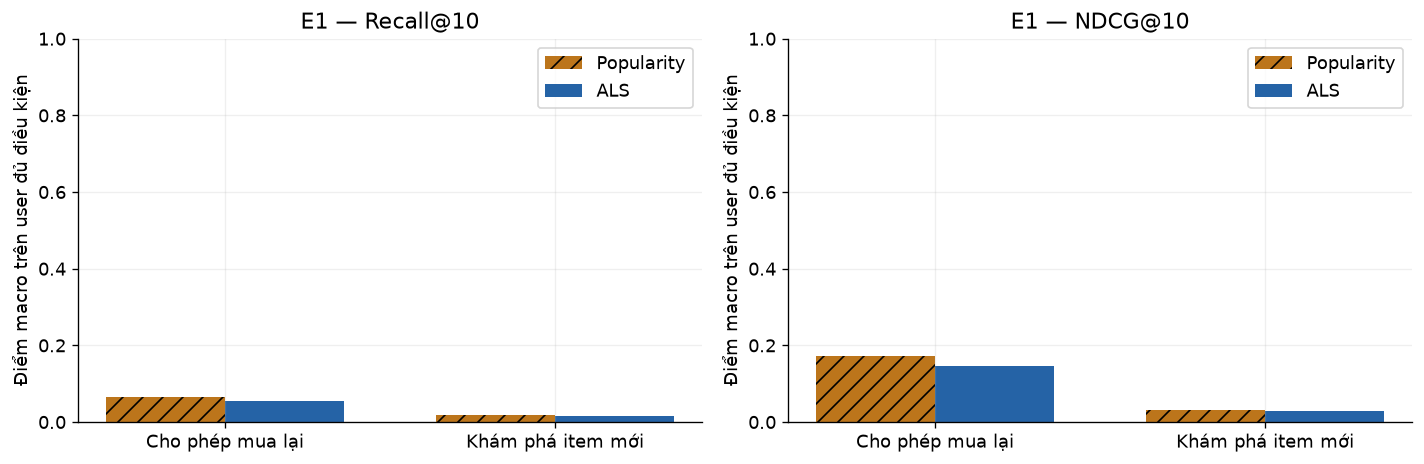

**RQ1 — test:** ALS − Popularity: ΔNDCG@10 = **-0.026015**, ΔRecall@10 = **-0.010549**, 11,646 user ở giao thức chính. Dấu chênh lệch phản ánh kết quả đo, chưa phải kiểm định ý nghĩa thống kê. Không diễn giải chênh lệch giữa hai population chính/phụ như cải thiện mô hình.

In [23]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,title in zip(axes,['recall_at_10','ndcg_at_10'],['Recall@10','NDCG@10']):
    for offset,model_name in [(-0.18,'Popularity'),(0.18,'ALS')]:
        subset=e1_pd[e1_pd['model']==model_name].set_index('protocol').reindex(['main_repurchase','novel_items'])
        ax.bar(np.arange(2)+offset,subset[metric],width=0.36,label=model_name,
               color=COLORS[model_name],hatch='//' if model_name=='Popularity' else '')
    ax.set_xticks([0,1],['Cho phép mua lại','Khám phá item mới'])
    ax.set(title='E1 — '+title,ylabel='Điểm macro trên user đủ điều kiện',ylim=(0,1)); ax.legend()
fig.tight_layout(); plt.show()
main=e1_pd[e1_pd['protocol']=='main_repurchase'].set_index('model')
delta_ndcg=float(main.loc['ALS','ndcg_at_10']-main.loc['Popularity','ndcg_at_10'])
delta_recall=float(main.loc['ALS','recall_at_10']-main.loc['Popularity','recall_at_10'])
display(Markdown(f'**RQ1 — test:** ALS − Popularity: ΔNDCG@10 = **{delta_ndcg:+.6f}**, '
 f"ΔRecall@10 = **{delta_recall:+.6f}**, {int(main.loc['ALS','users']):,} user ở giao thức chính. "
 'Dấu chênh lệch phản ánh kết quả đo, chưa phải kiểm định ý nghĩa thống kê. '
 'Không diễn giải chênh lệch giữa hai population chính/phụ như cải thiện mô hình.'))

**Kết quả và nhận xét (RQ1).** Refit trên lịch sử trước test mất 12,8 giây (gồm chuẩn bị CSR). Kết quả test:

| Giao thức | User | Mô hình | Recall@10 | NDCG@10 | Số item khác nhau được gợi ý |
|---|---:|---|---:|---:|---:|
| Cho phép mua lại | 11.646 | Popularity | 0,0655 | 0,1732 | 10 |
| | | ALS | 0,0550 | 0,1472 | 8.905 |
| Chỉ item mới | 11.605 | Popularity | 0,0171 | 0,0319 | 180 |
| | | ALS | 0,0153 | 0,0291 | 10.764 |

- **Giao thức chính:** ALS thấp hơn Popularity, ΔNDCG@10 = −0,0260 (−15,0%), ΔRecall@10 = −0,0105 (−16,1%). **Giao thức item mới:** khoảng cách nhỏ hơn về tương đối (−8,5% NDCG, −10,7% Recall) nhưng ALS vẫn thấp hơn. Trên dữ liệu này, câu trả lời cho RQ1 là **không**: ALS không vượt Popularity về độ chính xác Top-10.
- Kết quả test nhất quán với validation (ALS 0,1472 so với 0,1488; Popularity 0,1732 so với 0,1741), nên lựa chọn ở E2 không khớp quá mức vào validation và khoảng cách giữa hai mô hình không phải hiện tượng riêng của cửa sổ test.
- Khi loại item đã thấy, số cặp nhãn giảm từ 289.795 xuống 178.834: **38,3% cặp mua trong test là item user đã tương tác trước đó**; 41 user không còn nhãn bị loại. NDCG@10 của cả hai mô hình giảm 5–5,4 lần, Recall@10 giảm 3,6–3,8 lần, cho thấy phần lớn độ chính xác ở giao thức chính đến từ mua lặp.
- ALS cá nhân hóa thật: 8.905 item khác nhau trong Top-10, so với 10 item chung của Popularity. Popularity đạt điểm trung bình cao bằng cách gợi ý cùng một nhóm hàng thiết yếu cho mọi user; điều này có lợi cho chỉ số macro nhưng không đa dạng.
- **Cold-start:** 1.591 user mua trong test (12,0%) không có trong index refit, trong đó 33 user mất hết cặp do rút gọn. Popularity trên nhóm này đạt Recall@10 = 0,0718 và NDCG@10 = 0,1424, cùng mức với nhóm có lịch sử, nên dùng Popularity làm fallback là hợp lý. Item mới chỉ chiếm 0,44% cặp nhãn test.
- Độ bất định của chênh lệch được ước lượng bằng bootstrap ở Bước 11.3. Phần đóng góp của mua lặp được đo trực tiếp bằng baseline RepeatPop ở mục 11.6. Không so sánh điểm giữa hai giao thức vì population và nhãn khác nhau.

### Bước 11.3 — Khoảng tin cậy bootstrap cho chênh lệch ALS − Popularity

**Mục đích.** E1 dùng một mốc test, nên chênh lệch trung bình cần kèm độ bất định. Cell lấy mẫu lại user có hoàn lại 2.000 lần (seed 42), dùng cùng một mẫu cho cả hai mô hình (bootstrap ghép cặp), rồi tính khoảng tin cậy 95% theo phân vị cho ΔRecall@10 và ΔNDCG@10. Cell chỉ đọc gợi ý E1 đã lưu và kiểm tra trung bình theo user khớp `results.e1_test`; không fit hay chọn lại mô hình. Khoảng tin cậy chỉ phản ánh biến động do mẫu user trong cùng cửa sổ test, không phản ánh biến động giữa các mốc thời gian.

In [24]:
# Bootstrap ghép cặp theo user: cùng một mẫu user cho ALS và Popularity; chỉ đọc gợi ý E1 đã lưu.
BOOT_ROUNDS,BOOT_CHUNK=2000,200
rng=np.random.default_rng(CFG['seed'])

def paired_users(proto,boot_truth):
    parts=[per_user_metrics(read_delta(f'results.e1_{proto}_{m.lower()}_recs'),boot_truth)
           .select('user_id',F.col('recall').alias(m+'_recall'),F.col('ndcg').alias(m+'_ndcg')) for m in ['ALS','Popularity']]
    return parts[0].join(parts[1],'user_id').orderBy('user_id').toPandas()

boot_rows=[]
for proto,proto_labels in [('main_repurchase',test_labels),('novel_items',novel_test_labels())]:
    boot_truth,_=gpu_evaluation_population(spark,proto_labels,refit_users,refit_items)
    paired=paired_users(proto,boot_truth)
    saved=e1_pd[e1_pd['protocol']==proto].set_index('model')
    assert len(paired)==int(saved.loc['ALS','users']),'Population khác E1 đã lưu.'
    for metric in ['ndcg','recall']:
        for m in ['ALS','Popularity']:
            assert abs(paired[f'{m}_{metric}'].mean()-saved.loc[m,f'{metric}_at_10'])<1e-9,'Chỉ số từng user không khớp E1.'
        diff=(paired[f'ALS_{metric}']-paired[f'Popularity_{metric}']).to_numpy()
        boot=np.concatenate([diff[rng.integers(0,len(diff),(BOOT_CHUNK,len(diff)))].mean(axis=1)
                             for _ in range(BOOT_ROUNDS//BOOT_CHUNK)])
        low,high=np.percentile(boot,[2.5,97.5])
        boot_rows.append({'protocol':proto,'metric':f'{metric}_at_10','users':len(diff),
            'ALS':paired[f'ALS_{metric}'].mean(),'Popularity':paired[f'Popularity_{metric}'].mean(),
            'delta':diff.mean(),'ci95_low':low,'ci95_high':high,'share_als_better':(diff>0).mean(),
            'share_tie':(diff==0).mean(),'share_pop_better':(diff<0).mean()})
bootstrap=pd.DataFrame(boot_rows)
bootstrap.to_json(LOCAL/'e1_bootstrap.json',orient='records',indent=2)
display(bootstrap.round(4))

,protocol,metric,users,ALS,Popularity,delta,ci95_low,ci95_high,share_als_better,share_tie,share_pop_better
0,main_repurchase,ndcg_at_10,11646,0.1472,0.1732,-0.0260,-0.0287,-0.0232,0.2950,0.3408,0.3642
1,main_repurchase,recall_at_10,11646,0.0550,0.0655,-0.0105,-0.0117,-0.0094,0.1862,0.4981,0.3156
2,novel_items,ndcg_at_10,11605,0.0291,0.0319,-0.0027,-0.0044,-0.0011,0.1435,0.7261,0.1305
3,novel_items,recall_at_10,11605,0.0153,0.0171,-0.0018,-0.0028,-0.0008,0.1075,0.7705,0.1219


**Kết quả và nhận xét.** Trung bình theo user tính lại khớp đúng `results.e1_test` (cell có `assert`).

| Giao thức | Chỉ số | ALS − Popularity | KTC 95% | User: ALS tốt hơn / hòa / Popularity tốt hơn |
|---|---|---:|---|---|
| Cho phép mua lại (11.646 user) | NDCG@10 | −0,0260 | [−0,0287; −0,0232] | 29,5% / 34,1% / 36,4% |
| | Recall@10 | −0,0105 | [−0,0117; −0,0094] | 18,6% / 49,8% / 31,6% |
| Chỉ item mới (11.605 user) | NDCG@10 | −0,0027 | [−0,0044; −0,0011] | 14,3% / 72,6% / 13,0% |
| | Recall@10 | −0,0018 | [−0,0028; −0,0008] | 10,8% / 77,1% / 12,2% |

- Cả bốn khoảng tin cậy nằm hoàn toàn dưới 0. Xét biến động do mẫu user trong cửa sổ test, Popularity tốt hơn ALS một cách nhất quán, không phải do ngẫu nhiên. Ở giao thức chính, khoảng tin cậy của ΔNDCG@10 rộng khoảng 0,0055, nhỏ so với chênh lệch 0,026.
- Chênh lệch không đồng đều giữa các user. Ở giao thức chính, ALS tốt hơn với 29,5% user và Popularity tốt hơn với 36,4%. Ở giao thức item mới, số user ALS tốt hơn (14,3%) còn nhỉnh hơn số user Popularity tốt hơn (13,0%), nhưng trung bình vẫn nghiêng về Popularity, nghĩa là mức hơn của Popularity ở những user nó thắng lớn hơn. Hai mô hình đúng ở những nhóm user khác nhau; đây là cơ sở cho hướng mô hình lai (giả thuyết, chưa kiểm chứng).
- Bootstrap coi user là đơn vị độc lập và chỉ đo biến động trong một cửa sổ test; nó không thay cho đánh giá trên nhiều mốc thời gian.

### Bước 11.4 — Top-10 minh họa và lịch sử

**Mục đích.** Chọn user theo thứ tự ID; tránh chỉ chọn trường hợp thành công.

In [25]:
example_recs=read_delta('results.e1_main_repurchase_als_recs')
example_users=example_recs.select('user_id').distinct().orderBy('user_id').limit(3).cache()
print('Lịch sử gần nhất trước cutoff, tối đa 5 sự kiện/user:')
w_example=Window.partitionBy('user_id').orderBy(F.desc('event_us'),F.asc('item_id'))
example_keys=dims['gold.dim_user'].join(F.broadcast(example_users),'user_id')
show_small(refit_events.join(F.broadcast(example_keys),'user_key')
 .join(dims['gold.dim_product'].select('product_key','item_id','category'),'product_key')
 .withColumn('position',F.row_number().over(w_example)).where('position <= 5')
 .select('user_id','position','item_id','category','action_type','event_us').orderBy('user_id','position'),15)
print('Top-10 kèm thuộc tính sản phẩm (snapshot catalog; Unknown khi thiếu):')
show_small(example_recs.join(F.broadcast(example_users),'user_id')
 .join(dims['gold.dim_product'].select('item_id','category','subcategory','brand_id','catalog_present'),'item_id','left')
 .orderBy('user_id','rank'),30)
print('Nhãn test, tối đa 20 item/user để trình bày:')
show_small(test_labels.join(F.broadcast(example_users),'user_id').groupBy('user_id')
 .agg(F.slice(F.sort_array(F.collect_set('item_id')),1,20).alias('positive_items_preview')),3)
example_users.unpersist()

Lịch sử gần nhất trước cutoff, tối đa 5 sự kiện/user:


,user_id,position,item_id,category,action_type,event_us
0,10003698,1,fmcg_997457,Foodstuffs and Beverages,view,104540613165473
1,10003698,2,fmcg_848694,Foodstuffs and Beverages,view,104538672917977
2,10003698,3,fmcg_716615,"Cosmetics, Personal Care, and Health Maintenan...",view,104538459235117
3,10003698,4,fmcg_544371,Foodstuffs and Beverages,view,104532821062701
4,10003698,5,fmcg_1056737,Foodstuffs and Beverages,view,104531176233942
5,10007650,1,fmcg_426159,Foodstuffs and Beverages,added_to_cart,108061850011648
6,10007650,2,fmcg_506226,Home Improvement and Countryside Retreat Essen...,added_to_cart,108061259676105
7,10007650,3,fmcg_612755,Foodstuffs and Beverages,added_to_cart,108051607055593
8,10007650,4,fmcg_1160091,Foodstuffs and Beverages,added_to_cart,108050802519600
9,10007650,5,fmcg_514885,Foodstuffs and Beverages,added_to_cart,108038658341372


Top-10 kèm thuộc tính sản phẩm (snapshot catalog; Unknown khi thiếu):


,item_id,user_id,rank,score,category,subcategory,brand_id,catalog_present
0,fmcg_104833,10003698,1,0.497401,Foodstuffs and Beverages,Sweet Desserts and Confectionery,65693,True
1,fmcg_52079,10003698,2,0.492273,Foodstuffs and Beverages,Dairy Products and Eggs,65693,True
2,fmcg_1015420,10003698,3,0.491652,Foodstuffs and Beverages,Dairy Products and Eggs,65693,True
3,fmcg_1061179,10003698,4,0.490812,Foodstuffs and Beverages,Sweet Desserts and Confectionery,65693,True
4,fmcg_36692,10003698,5,0.489700,Foodstuffs and Beverages,Dairy Products and Eggs,65693,True
5,fmcg_270684,10003698,6,0.489204,Foodstuffs and Beverages,Snacks and Munchies,65693,True
6,fmcg_764732,10003698,7,0.488893,Foodstuffs and Beverages,Dairy Products and Eggs,65693,True
7,fmcg_1102722,10003698,8,0.486554,Foodstuffs and Beverages,Dairy Products and Eggs,65693,True
8,fmcg_1070226,10003698,9,0.485539,Foodstuffs and Beverages,Dairy Products and Eggs,65693,True
9,fmcg_699307,10003698,10,0.485034,Foodstuffs and Beverages,Dairy Products and Eggs,65693,True


Nhãn test, tối đa 20 item/user để trình bày:


,user_id,positive_items_preview
0,10007650,"[fmcg_1047486, fmcg_116995, fmcg_131188, fmcg_..."
1,10003698,"[fmcg_1102722, fmcg_15671, fmcg_56971, fmcg_65..."
2,10008121,"[fmcg_1084363, fmcg_1135262, fmcg_180861, fmcg..."


DataFrame[user_id: string]

**Kết quả và nhận xét.** Ba user có ID nhỏ nhất được chọn theo thứ tự, không theo kết quả:

- User `10003698`: lịch sử gần nhất là các lượt xem thực phẩm và mỹ phẩm. Top-10 đều thuộc *Foodstuffs and Beverages*, cùng brand 65693, chủ yếu sữa/trứng và đồ ngọt. Item hạng 8 (`fmcg_1102722`) có trong nhãn test.
- User `10007650`: lịch sử gần nhất là các lượt thêm vào giỏ (thực phẩm, đồ gia dụng). Top-10 có một item *Home Improvement* ở hạng 1, còn lại là thực phẩm.
- User `10008121`: sự kiện gần nhất cách mốc test khoảng 179 ngày tương đối (event_us ≈ 96,3·10¹² so với cutoff 111,8·10¹²), nhưng item hạng 1 (`fmcg_180861`) vẫn có trong nhãn test. Nhân tố ẩn vẫn giữ được sở thích dài hạn của user ít hoạt động gần đây.

Thang điểm ALS khác nhau giữa các user (khoảng 0,49 với user thứ nhất, 0,97–1,13 với user thứ hai), xác nhận điểm chỉ có ý nghĩa xếp hạng trong cùng một user, không phải xác suất. Gợi ý tập trung vào thực phẩm, phản ánh tỷ trọng 80,7% của ngành này. Ba ví dụ không đại diện cho toàn bộ user; ID sản phẩm được giữ ẩn danh.

### 11.5. Phát hành Top-10 batch và artifact có phiên bản

Sau E1, model cuối (refit trên lịch sử trước cutoff test) sinh tối đa 10 item cho mọi user của `gold.dim_user`: user có lịch sử nhận ALS, user mới nhận Popularity fallback. Bảng `gold.recommendations` có `user_id`, `rank`, `item_id`, `score`, `source`, `model_version`, `cutoff_us`, `source_revision`; không lặp item, ít hơn 10 khi thiếu ứng viên. Model, mapping user/item, manifest (selection, protocol, Delta version đầu vào/đầu ra, coverage) được lưu cùng `model_version` trong `results/<RUN_ID>/artifacts/`; `results.model_registry` và `results.model_coverage` phục vụ dashboard. Điểm ALS dùng để xếp hạng, không phải xác suất mua.

### Bước 11.5 — Phát hành gợi ý và artifact

**Mục đích.** Kiểm tra ràng buộc Top-K, ghi coverage và đóng gói model + mapping + manifest theo phiên bản.

In [26]:
PUBLISH_SCHEMA=pa.schema([('user_id',pa.string()),('rank',pa.int32()),('item_id',pa.string()),
                          ('score',pa.float64()),('source',pa.string())])
if stage_done('publish'): skip('publish')
else:
    with running('publish'):
        serving_model=GpuALSModel.load(ARTIFACTS/'model')
        try:
            warm={r.user_id for r in refit_users.select('user_id').toLocalIterator()}
            cold=sorted(r.user_id for r in dims['gold.dim_user'].select('user_id').toLocalIterator() if r.user_id not in warm)
            def publish_rows():
                for row in als_rows(serving_model,refit_users,refit_users,refit_items):
                    yield (*row,'als')
                for row in popularity_rows(cold,popularity_ranking('gold_ml.refit_item_popularity')):
                    yield (*row,'popularity_fallback')
            recommendations=rows_to_delta(publish_rows(),'gold.recommendations',PUBLISH_SCHEMA,
                constants={'model_version':MODEL_VERSION,'cutoff_us':protocol['refit_end_exclusive_us'],
                           'source_revision':CFG['source_revision']})
        finally:
            serving_model.close(); del serving_model
        per_user=recommendations.groupBy('user_id').agg(F.count('*').alias('n'),F.countDistinct('item_id').alias('items'),
            F.countDistinct('rank').alias('ranks'),F.max('rank').alias('max_rank'))
        invalid=per_user.where(f"n > {CFG['k']} OR n != items OR n != ranks OR max_rank != n").count()
        assert invalid==0,'Top-K phải không lặp item, rank liên tục, tối đa K.'
        sources=recommendations.groupBy('source').agg(F.countDistinct('user_id').alias('users'),
            F.countDistinct('item_id').alias('distinct_items')).toPandas()
        coverage={'model_version':MODEL_VERSION,'users_in_dim_user':VERSIONS['gold.dim_user']['written_rows'],
            'users_with_recommendations':per_user.count(),'users_short_list':per_user.where(f"n < {CFG['k']}").count(),
            'als_users':int(sources.loc[sources['source']=='als','users'].sum()),
            'fallback_users':int(sources.loc[sources['source']=='popularity_fallback','users'].sum()),
            'distinct_items_recommended':recommendations.select('item_id').distinct().count(),
            'candidate_items':refit_item_count}
        coverage['item_coverage']=coverage['distinct_items_recommended']/coverage['candidate_items']
        # Mapping đi cùng model: không thể giải mã index nếu thiếu mapping đúng phiên bản.
        for name,file_name in [('gold_ml.refit_user_index','user_index.parquet'),('gold_ml.refit_item_index','item_index.parquet')]:
            temporary=ARTIFACTS/(file_name+'.tmp')
            pq.write_table(pa.Table.from_pandas(read_delta(name).toPandas(),preserve_index=False),temporary)
            os.replace(temporary,ARTIFACTS/file_name)
        released=['silver.events','gold_ml.refit_user_index','gold_ml.refit_item_index',REFIT_PAIRS,
                  'gold_ml.refit_item_popularity','results.e2_validation','results.e1_test','gold.recommendations']
        manifest_doc={'model_version':MODEL_VERSION,'created_at':utc_now(),'run_id':RUN_ID,
            'source_revision':CFG['source_revision'],'cutoff_us':protocol['refit_end_exclusive_us'],
            'selection':selection,'protocol':protocol,'protocol_sha256':PROTOCOL_SHA,
            'model_metadata':json.loads((ARTIFACTS/'model'/'metadata.json').read_text()),
            'delta_versions':{name:VERSIONS[name] for name in released},'coverage':coverage}
        atomic_json(ARTIFACTS/'manifest.json',manifest_doc)
        save_delta(spark.createDataFrame([{'model_version':MODEL_VERSION,'config_id':selection['config_id'],
            'params_json':json.dumps(best_params,sort_keys=True),'cutoff_us':protocol['refit_end_exclusive_us'],
            'recommendations_version':VERSIONS['gold.recommendations']['version'],
            'artifact_path':str(ARTIFACTS.resolve()),'created_at':manifest_doc['created_at']}]),'results.model_registry')
        save_delta(spark.createDataFrame([coverage]),'results.model_coverage')
        set_progress('publish',coverage)
publish_coverage=progress('publish')
display(pd.DataFrame(publish_coverage.items(),columns=['Chỉ tiêu','Giá trị']))
show_small(read_delta('gold.recommendations').orderBy('user_id','rank'),12)
print('Artifact:',os.path.relpath(ARTIFACTS))

2026-10-30 09:21:19 | STAGE_SKIP publish: đã hoàn tất lúc 2026-10-29T21:53:34+00:00 (checkpoint)


,Chỉ tiêu,Giá trị
0,model_version,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...
1,users_in_dim_user,140062
2,users_with_recommendations,140062
3,users_short_list,0
4,als_users,127411
5,fallback_users,12651
6,distinct_items_recommended,25852
7,candidate_items,227442
8,item_coverage,0.113664


,user_id,rank,item_id,score,source,model_version,cutoff_us,source_revision
0,100003,1,fmcg_365654,0.158525,als,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...,111844800000000,79bcf78cd4699267f561ad3fd51fe7b52af53083
1,100003,2,fmcg_239768,0.154649,als,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...,111844800000000,79bcf78cd4699267f561ad3fd51fe7b52af53083
2,100003,3,fmcg_896094,0.153327,als,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...,111844800000000,79bcf78cd4699267f561ad3fd51fe7b52af53083
3,100003,4,fmcg_599468,0.151862,als,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...,111844800000000,79bcf78cd4699267f561ad3fd51fe7b52af53083
4,100003,5,fmcg_555149,0.147527,als,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...,111844800000000,79bcf78cd4699267f561ad3fd51fe7b52af53083
5,100003,6,fmcg_1165185,0.146773,als,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...,111844800000000,79bcf78cd4699267f561ad3fd51fe7b52af53083
6,100003,7,fmcg_801025,0.143228,als,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...,111844800000000,79bcf78cd4699267f561ad3fd51fe7b52af53083
7,100003,8,fmcg_174756,0.142300,als,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...,111844800000000,79bcf78cd4699267f561ad3fd51fe7b52af53083
8,100003,9,fmcg_618051,0.141269,als,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...,111844800000000,79bcf78cd4699267f561ad3fd51fe7b52af53083
9,100003,10,fmcg_52079,0.139818,als,retail_star_full_v1.uniform_r32_reg0.1_a10.0.3...,111844800000000,79bcf78cd4699267f561ad3fd51fe7b52af53083


Artifact: results/retail_star_full_v1/artifacts/retail_star_full_v1.uniform_r32_reg0.1_a10.0.3c2a3e11


**Kết quả và nhận xét.** `gold.recommendations` có Top-10 cho đủ 140.062/140.062 user của `gold.dim_user`, không user nào có danh sách ngắn hơn 10. Có 127.411 user (91,0%) nhận gợi ý ALS và 12.651 user (9,0%) nhận Popularity fallback. Các gợi ý dùng 25.852 item khác nhau, tức 11,4% trong 227.442 item ứng viên. Model, ánh xạ user/item và manifest được lưu cùng `model_version = retail_star_full_v1.uniform_r32_reg0.1_a10.0.3c2a3e11`, gắn với cutoff `111844800000000` và revision nguồn, nên bộ gợi ý đã phát hành truy ngược được tới đúng dữ liệu và cấu hình đã dùng.

### 11.6. Baseline bổ sung: mua lặp cá nhân hóa (RepeatPop)

Popularity gợi ý cùng một danh sách cho mọi user, ALS học nhân tố ẩn; chưa mô hình nào trả lời trực tiếp câu hỏi *bao nhiêu độ chính xác chỉ đến từ việc mua lại hàng quen*. RepeatPop là baseline cá nhân hóa đơn giản nhất cho câu hỏi đó [17]:

1. Lấy các item user đã có `order` trong lịch sử trước cutoff (train cho validation, refit cho test), xếp theo số lần `order` giảm dần, rồi tổng số sự kiện của cặp giảm dần, rồi `item_index` tăng dần; giữ tối đa 10 item.
2. Chỗ còn lại lấp bằng Popularity tính từ cùng lịch sử, bỏ item đã chọn. User chưa từng mua nhận đúng danh sách Popularity.
3. `score` là số lần user đã mua item; item lấp có `score = 0` và theo thứ tự Popularity.

**Thứ tự thực hiện và phạm vi.** RepeatPop được thêm **sau khi đã biết kết quả E1**. Vì vậy baseline không có tham số nào được chỉnh: quy tắc trên cố định trước khi chạy và được khóa trong checkpoint (`repeat_baseline`) trước khi chấm test; validation chỉ để đối chiếu, không dùng để chọn. Population, nhãn, ứng viên và hàm chỉ số giống hệt giao thức chính của E1. Stage chỉ đọc lịch sử Gold ML và bảng Popularity đã ghim version, ghi bảng mới; không đổi lựa chọn E2, kết quả E1 hay `gold.recommendations`.

Ở giao thức item mới, mọi item RepeatPop lấy từ lịch sử mua đều là item đã thấy nên bị loại; phần còn lại là Popularity bỏ item đã thấy, tức **trùng hoàn toàn với Popularity** theo định nghĩa. Vì vậy chỉ đánh giá RepeatPop ở giao thức chính.


### Bước 11.6 — Gợi ý và đánh giá RepeatPop

**Mục đích.** Khóa định nghĩa trước test; đánh giá validation rồi test trên cùng population với Popularity và ALS.

2026-10-30 10:48:19 | STAGE_START repeat_baseline


2026-10-30 10:48:19 | RepeatPop validation


2026-10-30 10:48:39 | RepeatPop test


2026-10-30 10:48:54 | STAGE_DONE repeat_baseline 35.4s ram_peak=5.69G swap_peak=0.00G shuffle_write=0.05G disk_spill=0.00G


,split,model,users,recall_at_10,ndcg_at_10
0,validation,Popularity,11534,0.0662,0.1741
1,validation,ALS,11534,0.0562,0.1488
2,validation,RepeatPop,11534,0.1409,0.3297
3,test,Popularity,11646,0.0655,0.1732
4,test,ALS,11646,0.0550,0.1472
5,test,RepeatPop,11646,0.1439,0.3413


,users,users_with_purchase_history,history_items_per_user,catalog_coverage
split,,,,
validation,11534,10596,9.7602,0.1149
test,11646,10886,9.8196,0.1151


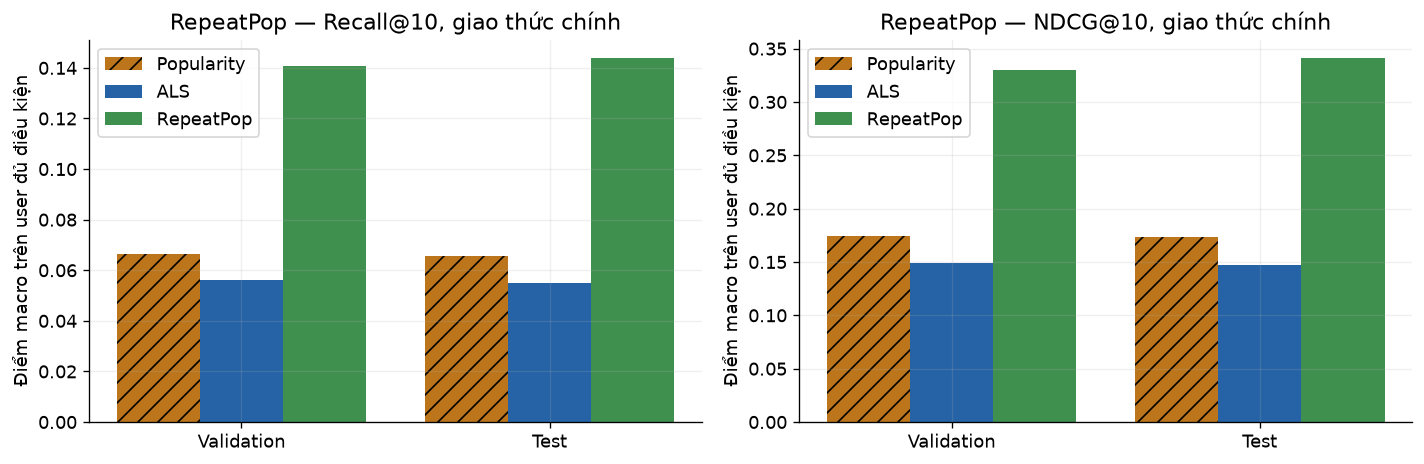

In [27]:
REPEAT=lock_value('repeat_baseline',{'model':'RepeatPop','history':CFG['purchase_action']+'_events > 0 trước cutoff',
    'order':[CFG['purchase_action']+'_events desc','total_events desc','item_index asc'],
    'fill':'popularity cùng lịch sử, bỏ item đã chọn','score':'số order của user với item; item lấp = 0','tuned':False})
COLORS['RepeatPop']='#3f8f4f'

def repeat_history(pairs_name,user_map,item_map,truth):
    # Tối đa K item user đã mua trước cutoff: số order giảm, tổng sự kiện giảm, item_index tăng.
    buy=CFG['purchase_action']+'_events'
    users=F.broadcast(truth.select('user_id').join(user_map.select('user_id','user_key'),'user_id'))
    order=Window.partitionBy('user_id').orderBy(F.desc(buy),F.desc('total_events'),F.asc('item_index'))
    return (read_delta(pairs_name).where(F.col(buy)>0)
        .withColumn('total_events',sum(F.col(a+'_events') for a in CFG['actions']))
        .join(users,'user_key').join(item_map.select('product_key','item_id','item_index'),'product_key')
        .withColumn('rank',F.row_number().over(order)).where(F.col('rank')<=CFG['k'])
        .select('user_id','rank','item_id',F.col(buy).cast('double').alias('score')))

def repeat_rows(truth,history,ranking,k=None):
    # Item đã mua của user trước; chỗ còn lại lấp bằng Popularity, bỏ item đã chọn, score lấp = 0.
    k=k or CFG['k']
    own={}
    for r in history.orderBy('user_id','rank').toLocalIterator():
        own.setdefault(r.user_id,[]).append((r.item_id,r.score))
    for user in sorted_users(truth):
        chosen=list(own.get(user,[]))
        picked={item for item,_ in chosen}
        for item in ranking[0]:
            if len(chosen)>=k: break
            if item not in picked:
                chosen.append((item,0.)); picked.add(item)
        for rank,(item,score) in enumerate(chosen,1):
            yield (user,rank,item,float(score))

REPEAT_SPLITS=[('validation','results.validation_repeatpop_recs','gold_ml.train_pair_actions',train_users,train_items,
                'gold_ml.train_item_popularity','gold_ml.validation_labels','train_end_exclusive_us'),
               ('test','results.e1_main_repurchase_repeatpop_recs','gold_ml.refit_pair_actions',refit_users,refit_items,
                'gold_ml.refit_item_popularity','gold_ml.test_labels','refit_end_exclusive_us')]
if stage_done('repeat_baseline'): skip('repeat_baseline')
else:
    with running('repeat_baseline'):
        repeat_done=progress('repeat_baseline_rows',[])
        for split,name,pairs_name,user_map,item_map,pop_table,labels_name,cutoff in REPEAT_SPLITS:
            if split in {row['split'] for row in repeat_done}: continue
            if split=='validation': truth,population=val_truth,val_population
            else: truth,population=gpu_evaluation_population(spark,test_labels,refit_users,refit_items)
            log(f'RepeatPop {split}')
            recs=rows_to_delta(repeat_rows(truth,repeat_history(pairs_name,user_map,item_map,truth),
                                           popularity_ranking(pop_table)),name,REC_SCHEMA)
            own=recs.where('score > 0').groupBy('user_id').count()
            history_users=own.count()
            repeat_done.append({'model':'RepeatPop','split':split,'protocol':'main_repurchase',
                **ranking_metrics(recs,truth),**population,'users_with_purchase_history':history_users,
                'history_items_per_user':own.agg(F.avg('count')).first()[0] if history_users else 0.,
                'catalog_coverage':recs.select('item_id').distinct().count()/item_map.count(),
                'run_id':RUN_ID,'source_revision':CFG['source_revision'],'history_cutoff_us':protocol[cutoff],
                'labels_version':VERSIONS[labels_name]['version'],'recs_version':VERSIONS[name]['version']})
            set_progress('repeat_baseline_rows',repeat_done)
        save_delta(spark.createDataFrame(repeat_done),'results.repeat_baseline')
repeat_pd=read_delta('results.repeat_baseline').toPandas().set_index('split')
repeat_pd.reset_index().to_json(LOCAL/'repeat_baseline.json',orient='records',indent=2)
main_test=e1_pd[e1_pd['protocol']=='main_repurchase'].set_index('model')
compare=pd.DataFrame([
    {'split':'validation','model':'Popularity',**{m:pop_val_metrics[m] for m in ['users','recall_at_10','ndcg_at_10']}},
    {'split':'validation','model':'ALS','users':int(best['users']),'recall_at_10':best['recall_at_10'],'ndcg_at_10':best['ndcg_at_10']},
    {'split':'validation','model':'RepeatPop',**repeat_pd.loc['validation',['users','recall_at_10','ndcg_at_10']].to_dict()},
    *[{'split':'test','model':m,**main_test.loc[m,['users','recall_at_10','ndcg_at_10']].to_dict()} for m in ['Popularity','ALS']],
    {'split':'test','model':'RepeatPop',**repeat_pd.loc['test',['users','recall_at_10','ndcg_at_10']].to_dict()}])
for split,group in compare.groupby('split'):
    assert group['users'].nunique()==1,f'Population RepeatPop khác Popularity/ALS ở {split}.'
display(compare.round(4))
display(repeat_pd[['users','users_with_purchase_history','history_items_per_user','catalog_coverage']].round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric,title in zip(axes,['recall_at_10','ndcg_at_10'],['Recall@10','NDCG@10']):
    for offset,model_name in [(-0.27,'Popularity'),(0.,'ALS'),(0.27,'RepeatPop')]:
        subset=compare[compare['model']==model_name].set_index('split').reindex(['validation','test'])
        ax.bar(np.arange(2)+offset,subset[metric],width=0.27,label=model_name,color=COLORS[model_name],
               hatch='//' if model_name=='Popularity' else '')
    ax.set_xticks([0,1],['Validation','Test'])
    ax.set(title='RepeatPop — '+title+', giao thức chính',ylabel='Điểm macro trên user đủ điều kiện',ylim=(0,None)); ax.legend()
fig.tight_layout(); plt.show()


### Bước 11.7 — Bootstrap RepeatPop so với Popularity và ALS

**Mục đích.** Cùng cách ghép cặp của Bước 11.3 (2.000 lần, seed 42), trên test giao thức chính; tách user có và chưa có lịch sử mua. Chỉ đọc gợi ý đã lưu.

In [28]:
# Bootstrap ghép cặp: cùng một mẫu user cho RepeatPop, Popularity và ALS; chỉ đọc gợi ý đã lưu.
repeat_rng=np.random.default_rng(CFG['seed'])
repeat_truth,_=gpu_evaluation_population(spark,test_labels,refit_users,refit_items)
repeat_models=['RepeatPop','Popularity','ALS']
parts=[per_user_metrics(read_delta(f'results.e1_main_repurchase_{m.lower()}_recs'),repeat_truth)
       .select('user_id',F.col('recall').alias(m+'_recall'),F.col('ndcg').alias(m+'_ndcg')) for m in repeat_models]
paired3=parts[0].join(parts[1],'user_id').join(parts[2],'user_id').orderBy('user_id').toPandas()
saved={'RepeatPop':repeat_pd.loc['test'],**{m:main_test.loc[m] for m in ['Popularity','ALS']}}
for m in repeat_models:
    assert len(paired3)==int(saved[m]['users']),'Population khác kết quả đã lưu.'
    for metric in ['ndcg','recall']:
        assert abs(paired3[f'{m}_{metric}'].mean()-saved[m][f'{metric}_at_10'])<1e-9,'Chỉ số từng user không khớp.'
repeat_boot=[]
for other in ['Popularity','ALS']:
    for metric in ['ndcg','recall']:
        diff=(paired3[f'RepeatPop_{metric}']-paired3[f'{other}_{metric}']).to_numpy()
        boot=np.concatenate([diff[repeat_rng.integers(0,len(diff),(BOOT_CHUNK,len(diff)))].mean(axis=1)
                             for _ in range(BOOT_ROUNDS//BOOT_CHUNK)])
        low,high=np.percentile(boot,[2.5,97.5])
        repeat_boot.append({'comparison':'RepeatPop - '+other,'metric':f'{metric}_at_10','users':len(diff),
            'RepeatPop':paired3[f'RepeatPop_{metric}'].mean(),'other':paired3[f'{other}_{metric}'].mean(),
            'delta':diff.mean(),'ci95_low':low,'ci95_high':high,'share_repeat_better':(diff>0).mean(),
            'share_tie':(diff==0).mean(),'share_other_better':(diff<0).mean()})
repeat_bootstrap=pd.DataFrame(repeat_boot)
display(repeat_bootstrap.round(4))
# User có ít nhất một item lịch sử mua trong Top-10 RepeatPop so với user chỉ nhận danh sách Popularity.
buyers={r.user_id for r in read_delta('results.e1_main_repurchase_repeatpop_recs').where('score > 0')
        .select('user_id').distinct().toLocalIterator()}
paired3['group']=np.where(paired3['user_id'].isin(buyers),'có lịch sử mua','chưa từng mua')
by_group=paired3.groupby('group').agg(users=('user_id','size'),
    **{f'{m}_ndcg':(f'{m}_ndcg','mean') for m in repeat_models},**{f'{m}_recall':(f'{m}_recall','mean') for m in repeat_models})
display(by_group.round(4))
atomic_json(LOCAL/'repeat_bootstrap.json',{'bootstrap':repeat_bootstrap.to_dict(orient='records'),
    'by_group':by_group.reset_index().to_dict(orient='records')})


,comparison,metric,users,RepeatPop,other,delta,ci95_low,ci95_high,share_repeat_better,share_tie,share_other_better
0,RepeatPop - Popularity,ndcg_at_10,11646,0.3413,0.1732,0.1681,0.1640,0.1721,0.6435,0.2010,0.1555
1,RepeatPop - Popularity,recall_at_10,11646,0.1439,0.0655,0.0784,0.0762,0.0805,0.6170,0.2804,0.1027
2,RepeatPop - ALS,ndcg_at_10,11646,0.3413,0.1472,0.1941,0.1895,0.1988,0.6662,0.1947,0.1391
3,RepeatPop - ALS,recall_at_10,11646,0.1439,0.0550,0.0890,0.0868,0.0912,0.6518,0.2694,0.0787


,users,RepeatPop_ndcg,Popularity_ndcg,ALS_ndcg,RepeatPop_recall,Popularity_recall,ALS_recall
group,,,,,,,
chưa từng mua,760,0.1319,0.1319,0.0867,0.0685,0.0685,0.0384
có lịch sử mua,10886,0.3559,0.1761,0.1514,0.1492,0.0653,0.0561


**Kết quả và nhận xét.** Định nghĩa được khóa trong checkpoint trước khi chấm test; population ở mỗi tập trùng với Popularity và ALS, và trung bình theo user tính lại khớp bảng đã lưu (cell có `assert`). Stage chạy 35,4 giây, đỉnh RAM 5,69 GiB.

| Tập (giao thức chính) | User | Popularity NDCG / Recall | ALS NDCG / Recall | RepeatPop NDCG / Recall |
|---|---:|---:|---:|---:|
| Validation | 11.534 | 0,1741 / 0,0662 | 0,1488 / 0,0562 | **0,3297 / 0,1409** |
| Test | 11.646 | 0,1732 / 0,0655 | 0,1472 / 0,0550 | **0,3413 / 0,1439** |

| So sánh trên test (11.646 user) | Chỉ số | Chênh lệch | KTC 95% | User: RepeatPop tốt hơn / hòa / kém hơn |
|---|---|---:|---|---|
| RepeatPop − Popularity | NDCG@10 | +0,1681 | [0,1640; 0,1721] | 64,4% / 20,1% / 15,6% |
| | Recall@10 | +0,0784 | [0,0762; 0,0805] | 61,7% / 28,0% / 10,3% |
| RepeatPop − ALS | NDCG@10 | +0,1941 | [0,1895; 0,1988] | 66,6% / 19,5% / 13,9% |
| | Recall@10 | +0,0890 | [0,0868; 0,0912] | 65,2% / 26,9% / 7,9% |

| Nhóm user trên test | User | RepeatPop NDCG@10 | Popularity NDCG@10 | ALS NDCG@10 |
|---|---:|---:|---:|---:|
| Có lịch sử mua trước cutoff | 10.886 | 0,3559 | 0,1761 | 0,1514 |
| Chưa từng mua (RepeatPop = Popularity) | 760 | 0,1319 | 0,1319 | 0,0867 |

- **RepeatPop cao nhất ở cả validation và test.** Trên test, NDCG@10 gần gấp đôi Popularity (+97%) và bằng 2,3 lần ALS; Recall@10 bằng 2,2 lần Popularity và 2,6 lần ALS. Cả bốn khoảng tin cậy nằm xa trên 0. Validation cho cùng thứ tự RepeatPop > Popularity > ALS.
- **Mức hơn đến từ mua lặp.** 93,5% user đủ điều kiện ở test (10.886/11.646) đã có `order` trước cutoff, và với những user này trung bình 9,82/10 vị trí Top-10 là item họ đã mua; phần lấp bằng Popularity rất nhỏ. Trên nhóm này RepeatPop đạt 0,3559, gấp đôi Popularity. Đây là bằng chứng trực tiếp cho giả thuyết mua lặp nêu ở E1: phần lớn nhãn test là hàng user đã quen mua.
- Với 760 user chưa từng mua, RepeatPop trùng Popularity theo định nghĩa; ALS thấp hơn Popularity cả ở nhóm này (0,0867 so với 0,1319).
- RepeatPop vẫn kém Popularity ở 15,6% user. *Giả thuyết (chưa kiểm chứng):* đó là user có ít lần mua trước cutoff hoặc đổi nhu cầu, nên hàng phổ biến chung trúng nhãn nhiều hơn lịch sử riêng.
- **Đa dạng:** Top-10 của RepeatPop dùng 26.179 item khác nhau (11,5% trong 227.442 ứng viên), nhiều hơn ALS (8.905) và Popularity (10), vì mỗi user nhận chính hàng mình hay mua.
- **Giới hạn:** baseline được thêm sau khi đã xem kết quả E1; nó không có tham số nên không có lựa chọn nào dựa trên test, nhưng thứ tự thực hiện được ghi rõ ở đây và ở mục 14.5. RepeatPop không gợi ý được item mới; ở giao thức item mới nó trùng Popularity.


<a id="phan-12"></a>

## 12. Hiệu năng của lượt chạy toàn bộ Retail

Đo trên đúng một lượt chạy đầy đủ (Bronze → phát hành Top-10); không chạy lại pipeline ở nhiều quy mô. Mỗi stage ghi:

- thời gian lần hoàn tất, đo bằng đồng hồ monotonic tới khi action ghi Delta hoặc đồng bộ CUDA xong;
- số lần thử và thời gian các lần bị ngắt trước khi resume (báo riêng, không cộng vào lần hoàn tất);
- số dòng của bảng đầu ra chính;
- đỉnh RAM/swap của cgroup (lấy mẫu 2 giây) và VRAM thiết bị (10 giây);
- shuffle read/write và spill bộ nhớ/đĩa của các stage Spark hoàn tất trong khoảng đó (REST API Spark UI, đọc mỗi 10 giây).

Đây là **một lần đo** trên một máy: không có trung vị hay min–max, không suy ra quan hệ thời gian–quy mô. OS/MinIO cache và tải khác trên máy không được kiểm soát. Thời gian E2 và E1 gồm cả sinh Top-10 và tính chỉ số; thời gian fit ALS từng cấu hình nằm trong bảng E2.

### Bước 12.1 — Bảng và biểu đồ hiệu năng theo stage

**Mục đích.** Đọc checkpoint; lưu `results.run_performance` và `run_performance.json` cho dashboard.

,label,minutes,attempts,interrupted_seconds,output_rows,ram_peak_GiB,swap_peak_GiB,vram_peak_GiB,shuffle_write_GiB,disk_spill_GiB
0,Khảo sát nguồn,7.74,1.0,0.0,NaN,7.00,0.03,0.13,7.59,0.00
1,Bronze,22.81,1.0,0.0,267043972.0,4.46,1.12,0.13,0.02,0.00
2,Kiểm tra Delta,0.27,1.0,0.0,NaN,3.59,1.05,0.13,0.01,0.00
3,Silver,8.32,1.0,0.0,267043972.0,4.57,1.04,0.13,0.02,0.00
4,Gold DWH,4.79,1.0,0.0,267043972.0,5.72,0.65,0.13,0.03,0.00
5,Gold aggregates,6.98,1.0,0.0,NaN,6.03,0.56,0.13,3.56,0.00
6,Split thời gian,0.38,1.0,0.0,NaN,4.82,0.56,0.13,0.01,0.00
7,Gold ML mart,5.53,1.0,0.0,20804959.0,5.86,0.56,0.13,2.90,0.00
8,Popularity validation,0.12,1.0,0.0,NaN,4.57,0.55,0.13,0.00,0.00
9,E2,7.47,1.0,0.0,NaN,6.58,0.56,0.54,0.02,0.00


**Tổng thời gian các stage (lần hoàn tất):** 1.16 giờ trên `full`; thêm 0.0 phút của các lần bị ngắt trước khi resume. Giới hạn job: RAM 7.0 GiB, swap 4.0 GiB.

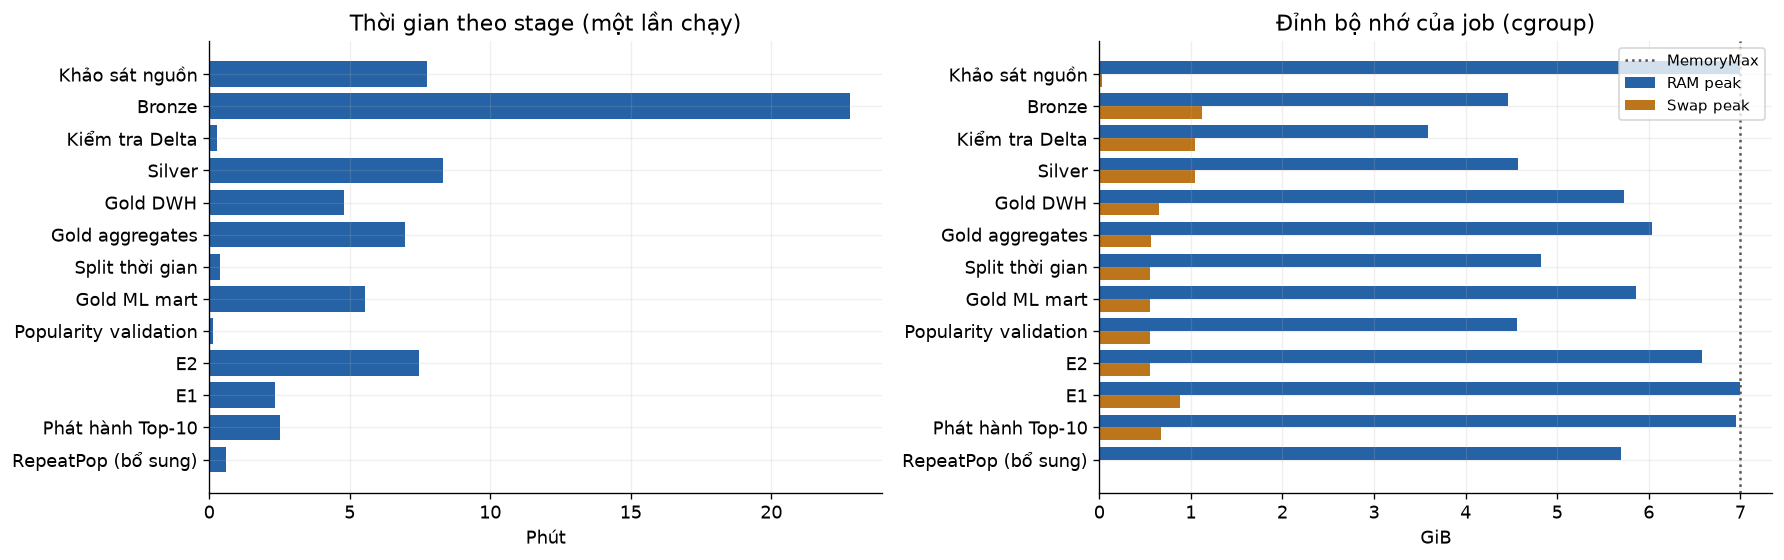

In [29]:
STAGE_LABELS={'source_survey':'Khảo sát nguồn','bronze':'Bronze','delta_checks':'Kiểm tra Delta','silver':'Silver',
 'warehouse':'Gold DWH','gold_aggregates':'Gold aggregates','ml_split':'Split thời gian','ml_mart':'Gold ML mart',
 'popularity_validation':'Popularity validation','e2':'E2','e1':'E1','publish':'Phát hành Top-10',
 'repeat_baseline':'RepeatPop (bổ sung)'}
# Số dòng bảng đầu ra chính: tổng đã kiểm tra trong checkpoint (Bronze ghi theo ngày nên written_rows chỉ là ngày cuối).
STAGE_OUTPUT={'bronze':('bronze.retail_events',lambda: progress('silver_quality')['bronze_events']),
 'silver':('silver.events',lambda: progress('silver_quality')['silver_events']),
 'warehouse':('gold.fact_interactions',lambda: progress('warehouse_checks')['fact_rows']),
 'ml_mart':('gold_ml.train_user_item_strength_uniform',lambda: VERSIONS['gold_ml.train_user_item_strength_uniform']['written_rows']),
 'publish':('gold.recommendations',lambda: VERSIONS['gold.recommendations']['written_rows'])}
MEASURES=['seconds','interrupted_seconds','attempts','output_rows','ram_peak_bytes','swap_peak_bytes','vram_device_peak_bytes',
          'spark_stages','shuffle_read_bytes','shuffle_write_bytes','memory_spilled_bytes','disk_spilled_bytes']
rows=[]
for name,label in STAGE_LABELS.items():
    stage=STATE['stages'].get(name,{})
    output,output_rows=STAGE_OUTPUT.get(name,('',lambda: None))
    rows.append({'stage':name,'label':label,'status':stage.get('status'),'output_table':output,'output_rows':output_rows(),
                 **{k:stage.get(k) for k in MEASURES if k!='output_rows'}})
performance=pd.DataFrame(rows)
assert (performance['status']=='done').all(),'Chạy hết các stage trước khi tổng hợp hiệu năng.'
performance[MEASURES]=performance[MEASURES].astype(float)
performance['interrupted_seconds']=performance['interrupted_seconds'].fillna(0.)
performance['run_id']=RUN_ID; performance['source_name']=CFG['source_name']
performance.to_json(LOCAL/'run_performance.json',orient='records',indent=2)
save_delta(spark.createDataFrame(performance),'results.run_performance')
GiB=2**30
view=performance.assign(minutes=performance['seconds']/60,ram_peak_GiB=performance['ram_peak_bytes']/GiB,
    swap_peak_GiB=performance['swap_peak_bytes']/GiB,vram_peak_GiB=performance['vram_device_peak_bytes']/GiB,
    shuffle_write_GiB=performance['shuffle_write_bytes']/GiB,disk_spill_GiB=performance['disk_spilled_bytes']/GiB)
display(view[['label','minutes','attempts','interrupted_seconds','output_rows','ram_peak_GiB','swap_peak_GiB',
              'vram_peak_GiB','shuffle_write_GiB','disk_spill_GiB']].round(2))
total_hours=performance['seconds'].sum()/3600
display(Markdown(f"**Tổng thời gian các stage (lần hoàn tất):** {total_hours:.2f} giờ trên `{CFG['source_name']}`; "
    f"thêm {performance['interrupted_seconds'].sum()/60:.1f} phút của các lần bị ngắt trước khi resume. "
    f"Giới hạn job: RAM {int(SCOPE['memory.max'])/GiB:.1f} GiB, swap {int(SCOPE['memory.swap.max'])/GiB:.1f} GiB."))
fig,axes=plt.subplots(1,2,figsize=(15,4.8))
y=np.arange(len(view))
axes[0].barh(y,view['minutes'],color=COLORS['ALS'])
axes[0].set(title='Thời gian theo stage (một lần chạy)',xlabel='Phút')
axes[1].barh(y-0.2,view['ram_peak_GiB'],height=0.4,color=COLORS['ALS'],label='RAM peak')
axes[1].barh(y+0.2,view['swap_peak_GiB'],height=0.4,color=COLORS['Popularity'],label='Swap peak')
axes[1].axvline(int(SCOPE['memory.max'])/GiB,color='#555555',linestyle=':',label='MemoryMax')
axes[1].set(title='Đỉnh bộ nhớ của job (cgroup)',xlabel='GiB'); axes[1].legend(fontsize=9)
for ax in axes:
    ax.set_yticks(y,view['label']); ax.invert_yaxis()
fig.tight_layout(); plt.show()

**Kết quả và nhận xét (RQ3).** Tổng thời gian 12 stage của lượt chạy chính là 69,3 phút (1,15 giờ); mỗi stage chạy đúng một lần, không có lần bị ngắt. Bảng trên có thêm stage RepeatPop (bổ sung), chạy ở phiên sau (35,4 giây, đỉnh RAM 5,69 GiB), nên tổng in ra là 69,8 phút; các nhận xét dưới đây nói về lượt chạy chính.

| Nhóm | Stage | Thời gian | Tỷ trọng |
|---|---|---:|---:|
| ETL và phân tích | khảo sát nguồn, Bronze, kiểm tra Delta, Silver, Gold DWH, aggregates | 50,9 phút | 73,5% |
| Gold ML mart | split thời gian, ML mart | 5,9 phút | 8,5% |
| Mô hình | Popularity, E2, E1, phát hành | 12,4 phút | 18,0% |

- **Bronze là stage lâu nhất** (22,8 phút, 32,9%): 227 batch ngày, 1.630 Spark stage, mỗi ngày là một commit Delta lên MinIO qua S3A. Shuffle chỉ 0,02 GiB, nên chi phí nằm ở đọc/ghi và commit theo ngày. Gộp nhiều ngày trong một commit sẽ giảm số commit nhưng làm thô đơn vị resume.
- **Shuffle lớn nhất** ở khảo sát nguồn (7,59 GiB: gom nhóm tìm dòng trùng và đếm distinct trên 267 triệu dòng), Gold aggregates (3,56 GiB) và Gold ML mart (2,90 GiB: gom sự kiện thành cặp user–item).
- **Bộ nhớ:** đỉnh RAM của cgroup (gồm cả page cache) chạm giới hạn 7,00 GiB ở khảo sát nguồn và E1; swap đỉnh 1,12 GiB (Bronze), dưới hạn mức 4 GiB. Chỉ E1 có spill: 1,04 GiB spill bộ nhớ và 13,7 MiB spill đĩa. Job hoàn tất trong giới hạn nhờ thứ tự RAM → spill SSD → swap có hạn mức như thiết kế.
- **GPU:** VRAM đỉnh 0,54 GiB trên 6 GiB. Trong E2, phần lớn thời gian là sinh Top-10 và tính chỉ số, không phải huấn luyện; phần mô hình không phải nút thắt của pipeline.
- Đây là một lần đo trên một máy (`local[2]`, RAM 7 GiB): không có độ dao động, không suy ra quan hệ thời gian–quy mô hay hiệu năng trên cụm.

### 12.2. Minh chứng Spark UI

Event log của lượt chạy nằm ở `results/retail_star_full_v1/spark-events`; mỗi lần khởi động Spark tạo một thư mục `eventlog_v2_<app id>`. Lượt chạy chính (tính toàn bộ stage) là app `local-1793306557325`; các app sau chỉ bỏ qua stage theo checkpoint. Ảnh dưới đây chụp từ Spark History Server, trang chi tiết stage nặng nhất của Gold aggregates, lưu tại `results/retail_star_full_v1/spark_ui.png`. Notebook chỉ hiển thị ảnh thật, không tự tạo ảnh thay minh chứng.

### Bước 12.3 — Hiển thị ảnh minh chứng

**Mục đích.** Nhúng ảnh thật nếu đã chụp; báo thiếu khi chưa có.

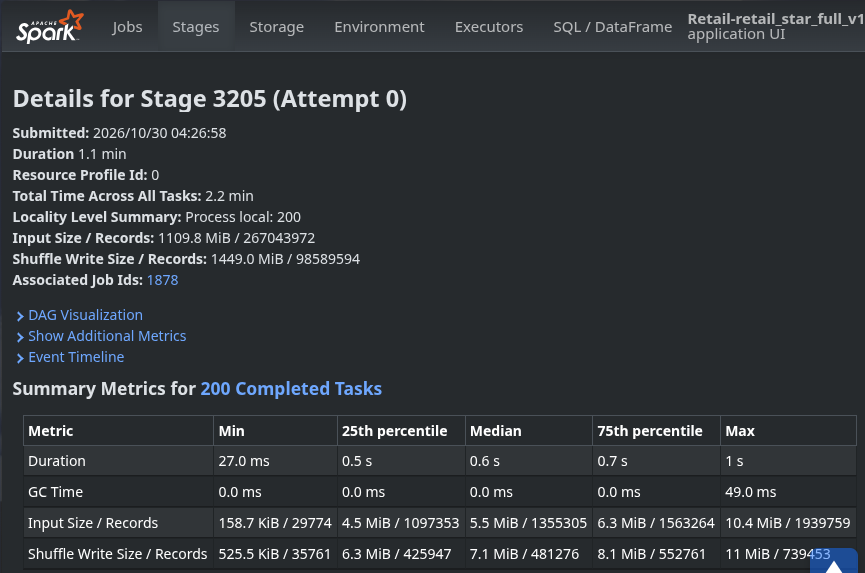

In [28]:
spark_ui_image=LOCAL/'spark_ui.png'
if spark_ui_image.exists(): display(Image(filename=str(spark_ui_image)))
else: display(Markdown('**Chưa có ảnh Spark UI.** Bổ sung ảnh thật từ lượt chạy toàn bộ Retail và phân tích stage/shuffle/spill.'))

**Kết quả và nhận xét.** Ảnh là stage 3205 (job 1878) của app `local-1793306557325`, bắt đầu 04:26:58, đầu stage notebook Gold aggregates, trùng thời điểm tính `gold.agg_overview`. Đây là stage có shuffle write lớn nhất trong giai đoạn Gold aggregates.

- **Đầu vào:** 1.109,8 MiB và 267.043.972 dòng, tức toàn bộ fact. **Shuffle write:** 1.449 MiB và 98.589.594 record. Số record shuffle nhỏ hơn số dòng đầu vào vì Spark gom một phần theo khóa trong từng task trước khi shuffle.
- **Song song:** 200 task, tổng thời gian task 2,2 phút trong 1,1 phút thực, đúng 2 luồng của `local[2]`.
- **Phân bố task:** thời gian trung vị 0,6 giây, p75 0,7 giây, lâu nhất 1 giây; đầu vào mỗi task tối đa 10,4 MiB; GC tối đa 49 ms. Không có lệch dữ liệu (skew) hay áp lực bộ nhớ đáng kể, và checkpoint ghi nhận spill bằng 0 cho cả giai đoạn Gold aggregates.
- Giới hạn của stage này là số luồng xử lý, không phải bộ nhớ hay phân bố dữ liệu; tăng số core hoặc executor có thể rút ngắn nó (chưa kiểm chứng trong đề tài).

<a id="phan-13"></a>

## 13. Thảo luận và kết luận

### 13.1. Tổng hợp theo câu hỏi nghiên cứu

Các đoạn dưới đọc kết quả đã lưu, không chạy thêm chọn mô hình. Đây là bằng chứng định lượng để viết thảo luận, không thay thế phân tích nguyên nhân.

### Bước 13.1 — Kết luận theo số liệu đã đo

**Mục đích.** Tách chênh lệch quan sát khỏi suy luận nhân quả.

In [31]:
e1_final=pd.read_json(LOCAL/'e1_test.json')
perf_final=pd.read_json(LOCAL/'run_performance.json').set_index('stage')
main_final=e1_final[e1_final['protocol']=='main_repurchase'].set_index('model')
comparison=[]
for metric in ['recall_at_10','ndcg_at_10']:
    av=float(main_final.loc['ALS',metric]); pv=float(main_final.loc['Popularity',metric])
    comparison.append({'Chỉ số':metric,'ALS':av,'Popularity':pv,'ALS - Popularity':av-pv})
display(pd.DataFrame(comparison))
for row in comparison:
    direction='cao hơn' if row['ALS - Popularity']>0 else ('thấp hơn' if row['ALS - Popularity']<0 else 'bằng')
    display(Markdown(f"**RQ1 — {row['Chỉ số']}:** ALS {direction} Popularity; "
                     f"chênh lệch tuyệt đối {row['ALS - Popularity']:+.6f}, giao thức chính."))
display(Markdown(f"**RQ2:** chọn `{selection['config_id']}` trên validation; "
 'đối chiếu E2 theo từng tham số khi các yếu tố khác cố định.'))
heaviest=perf_final['seconds'].idxmax()
display(Markdown(f"**RQ3:** lượt chạy `{CFG['source_name']}` mất {perf_final['seconds'].sum()/3600:.2f} giờ (lần hoàn tất của các stage); "
 f"stage lâu nhất là {perf_final.loc[heaviest,'label']} ({perf_final.loc[heaviest,'seconds']/60:.1f} phút). "
 f"Đỉnh RAM {perf_final['ram_peak_bytes'].max()/2**30:.2f} GiB, swap {perf_final['swap_peak_bytes'].max()/2**30:.2f} GiB, "
 f"spill đĩa tổng {perf_final['disk_spilled_bytes'].sum()/2**30:.2f} GiB. Một lần đo, không suy rộng sang quy mô hay máy khác."))

,Chỉ số,ALS,Popularity,ALS - Popularity
0,recall_at_10,0.054982,0.065531,-0.010549
1,ndcg_at_10,0.147205,0.173220,-0.026015


**RQ1 — recall_at_10:** ALS thấp hơn Popularity; chênh lệch tuyệt đối -0.010549, giao thức chính.

**RQ1 — ndcg_at_10:** ALS thấp hơn Popularity; chênh lệch tuyệt đối -0.026015, giao thức chính.

**RQ2:** chọn `uniform_r32_reg0.1_a10.0` trên validation; đối chiếu E2 theo từng tham số khi các yếu tố khác cố định.

**RQ3:** lượt chạy `full` mất 1.16 giờ (lần hoàn tất của các stage); stage lâu nhất là Bronze (22.8 phút). Đỉnh RAM 7.00 GiB, swap 1.12 GiB, spill đĩa tổng 0.01 GiB. Một lần đo, không suy rộng sang quy mô hay máy khác.

### 13.2. Thảo luận

**RQ1 — ALS có tốt hơn Popularity không?** Không, trên dữ liệu và lưới tham số đã khảo sát. Popularity cao hơn ALS ở cả validation (NDCG@10 0,1741 so với 0,1488) và test, ở cả giao thức mua lại (0,1732 so với 0,1472) lẫn giao thức item mới (0,0319 so với 0,0291). Khoảng tin cậy bootstrap 95% của ΔNDCG@10 là [−0,0287; −0,0232] và [−0,0044; −0,0011] ở hai giao thức, đều nằm dưới 0, nên chênh lệch không phải do ngẫu nhiên trong mẫu user. Kết quả phù hợp với nhận định rằng baseline đơn giản thường khó vượt trong gợi ý Top-N [14][15]. Giả thuyết 1 đã được kiểm chứng một phần bằng RepeatPop (mục 11.6); giả thuyết 2 và 3 chưa được kiểm chứng:

1. *Mua lặp và nhu cầu tập trung.* 38,3% cặp mua ở test là item đã tương tác; 80,7% sự kiện thuộc thực phẩm và 1% item chiếm 27,4% sự kiện. Một danh sách hàng thiết yếu chung đã trúng nhiều nhãn của đa số user, phù hợp với đặc điểm tiêu dùng lặp lại [17]. RepeatPop đo trực tiếp phần này: chỉ gợi ý lại item user đã mua, nó đạt NDCG@10 0,3413 so với 0,1732 (Popularity) và 0,1472 (ALS); với 10.886 user có lịch sử mua, con số là 0,3559 so với 0,1761 và 0,1514. Mua lặp là tín hiệu chính của bài toán. *Giả thuyết:* ALS chưa khai thác được tín hiệu này vì strength chủ yếu đến từ view và tích nhân tố hạng thấp làm mờ các cặp user–item cụ thể.
2. *Thang confidence.* Strength bị chi phối bởi view (94,9% sự kiện) trong khi nhãn là `order`, nhưng tăng trọng số mua (`purchase_focused`) lại làm điểm giảm. Vấn đề có thể nằm ở confidence tuyến tính trên strength lệch rất mạnh hơn là ở trọng số hành vi.
3. *Lưới hữu hạn.* Cấu hình tốt nhất nằm ở góc lưới, nên ALS có thể chưa được điều chỉnh tới điểm tốt nhất.

Chênh lệch không đồng đều giữa các user: ở giao thức chính ALS vẫn tốt hơn với 29,5% user (Popularity tốt hơn với 36,4%), nên hai mô hình trúng ở những nhóm user khác nhau. So với Popularity, ALS cá nhân hóa hơn: 8.905 item khác nhau trong Top-10 so với 10 item, và khi phát hành, 25.852 item (11,4% ứng viên) được gợi ý. Tuy vậy RepeatPop, cá nhân hóa theo lịch sử mua, vừa chính xác hơn vừa dùng nhiều item hơn (26.179) trên cùng population test.

**RQ2 — Tham số và trọng số.** Alpha 10, rank 32 và profile `uniform` tốt hơn ở cả 8/8 cặp so sánh; regParam 0,05–0,1 gần như không tác động (|Δ| ≤ 0,0006). Rank quyết định thời gian fit: rank 64 chậm khoảng 3 lần rank 32 (14–15 so với 5–6 giây), trong khi chất lượng lại thấp hơn.

**RQ3 — Thời gian và tài nguyên.** Toàn bộ Retail (267 triệu sự kiện) chạy 69,3 phút trên một máy với RAM 7 GiB. ETL chiếm 73,5% thời gian, Bronze riêng 32,9%; phần mô hình chỉ 18,0%. RAM chạm trần ở khảo sát nguồn và E1, swap tối đa 1,12 GiB, spill chỉ xuất hiện ở E1, và job vẫn hoàn tất. GPU dùng chưa tới 1 GiB VRAM. Ảnh Spark UI của stage nặng nhất trong Gold aggregates cho thấy task phân bố đều, không lệch dữ liệu; giới hạn nằm ở số luồng `local[2]`.

### 13.3. Giới hạn

- **Một mốc test, một lần đo:** khoảng tin cậy bootstrap chỉ phản ánh biến động theo mẫu user trong một cửa sổ test, không phản ánh biến động giữa các mốc thời gian; thời gian chỉ là một lần đo.
- **Lưới hữu hạn:** 16 cấu hình, cấu hình được chọn nằm ở góc lưới.
- **RepeatPop được thêm sau khi đã xem test:** baseline không có tham số và cho cùng thứ tự trên validation, nhưng thứ tự thực hiện được ghi rõ. Chưa có mô hình lai giữa lịch sử mua và ALS.
- **Dữ liệu:** đã ẩn danh và gây nhiễu có kiểm soát; thời gian tương đối; giá đã biến đổi; brand chỉ có 7 giá trị; catalog là snapshot, không có thời điểm hiệu lực.
- **Môi trường:** một máy `local[2]`; không suy rộng sang cụm nhiều máy hay quy mô dữ liệu khác.

### 13.4. Kết luận và hướng phát triển

Đề tài đạt các mục tiêu đặt ra. (1) Spark và Spark SQL thu nhận, làm sạch và biến đổi toàn bộ 267 triệu sự kiện Retail. (2) Bronze, Silver, Gold lưu bằng Delta trên MinIO, đạt cả năm kiểm tra nạp lại, phiên bản, lịch sử, schema và khóa bản ghi. (3) Gold DWH theo Star Schema bảo toàn đúng số sự kiện, và Gold ML Data Mart chia theo thời gian trước khi tổng hợp. (4) Implicit ALS chạy trên GPU và Popularity vừa là đối chứng vừa là fallback. (5) Chất lượng và tài nguyên được đo có thể tái lập, với model, mapping, cutoff và Delta version phát hành cùng `model_version`.

Về khai phá dữ liệu, trên T-ECD Retail, Implicit ALS không vượt Popularity về Recall@10 và NDCG@10 ở cả hai giao thức, dù cá nhân hóa và đa dạng hơn Popularity. Baseline mua lặp cá nhân hóa RepeatPop vượt cả hai ở giao thức chính (NDCG@10 0,3413 so với 0,1732 và 0,1472): với dữ liệu tạp hóa, lịch sử mua của chính user là tín hiệu mạnh nhất, nên một hệ gợi ý thực tế cần lấy nó làm mốc trước khi dùng mô hình phức tạp hơn. Popularity là fallback phù hợp cho 12% user mua hàng không có lịch sử.

Hướng phát triển (chưa kiểm chứng):

1. Thử confidence dạng log và mở rộng lưới (rank 8–16, alpha 1–5, $\lambda$ lớn hơn) với `RUN_ID` mới, ghi rõ là nghiên cứu thực hiện sau khi đã xem test.
2. Mô hình lai: giữ item mua lặp của RepeatPop và dùng ALS cho các vị trí còn lại hoặc cho item mới; chọn số vị trí dành cho mỗi nguồn trên validation, với `RUN_ID` mới.
3. Dùng thuộc tính và embedding sản phẩm cho cold-start.
4. Đánh giá trên nhiều mốc thời gian (rolling-origin) để đo độ ổn định của chênh lệch theo thời gian.
5. Chạy pipeline trên cụm nhiều máy.

<a id="phan-14"></a>

## 14. Tài liệu tham khảo và hướng dẫn tái lập

### 14.1. Tài liệu tham khảo

1. T-Tech, **T-ECD Dataset**. [Dataset card](https://huggingface.co/datasets/t-tech/T-ECD), [Small Retail](https://huggingface.co/datasets/t-tech/T-ECD/tree/main/dataset/small/retail), revision `79bcf78cd4699267f561ad3fd51fe7b52af53083`.
2. Y. Hu, Y. Koren, C. Volinsky, **Collaborative Filtering for Implicit Feedback Datasets**, ICDM 2008, pp. 263–272. [DOI](https://doi.org/10.1109/ICDM.2008.22).
3. Apache Spark, **RankingMetrics**. [Recall/NDCG](https://spark.apache.org/docs/4.2.0/api/python/reference/api/pyspark.mllib.evaluation.RankingMetrics.html).
4. Delta Lake, **Compatibility with Apache Spark**. [Releases](https://docs.delta.io/releases/); [dependency metadata Delta Spark 4.4.1](https://pypi.org/pypi/delta-spark/4.4.1/json).
5. Delta Lake, **Documentation**. [Batch, schema, history, time travel](https://docs.delta.io/).
6. Databricks, **Medallion Architecture**. [Bronze–Silver–Gold](https://docs.databricks.com/aws/en/lakehouse/medallion).
7. Apache Hadoop, **S3A**. [Object storage](https://hadoop.apache.org/docs/r3.5.0/hadoop-aws/tools/hadoop-aws/index.html).
8. Apache Spark, **Spark SQL**. [Programming guide](https://spark.apache.org/docs/4.2.0/sql-programming-guide.html).
9. M. Zaharia et al., **Apache Spark: A Unified Engine for Big Data Processing**, Communications of the ACM 59(11), pp. 56–65, 2016. [DOI](https://doi.org/10.1145/2934664).
10. M. Armbrust et al., **Delta Lake: High-Performance ACID Table Storage over Cloud Object Stores**, PVLDB 13(12), pp. 3411–3424, 2020. [DOI](https://doi.org/10.14778/3415478.3415560).
11. R. Kimball, M. Ross, **The Data Warehouse Toolkit: The Definitive Guide to Dimensional Modeling**, 3rd ed., Wiley, 2013. ISBN 978-1-118-53080-1.
12. Y. Koren, R. Bell, C. Volinsky, **Matrix Factorization Techniques for Recommender Systems**, IEEE Computer 42(8), pp. 30–37, 2009. [DOI](https://doi.org/10.1109/MC.2009.263).
13. G. Takács, I. Pilászy, D. Tikk, **Applications of the Conjugate Gradient Method for Implicit Feedback Collaborative Filtering**, RecSys 2011, pp. 297–300. [DOI](https://doi.org/10.1145/2043932.2043987).
14. P. Cremonesi, Y. Koren, R. Turrin, **Performance of Recommender Algorithms on Top-N Recommendation Tasks**, RecSys 2010, pp. 39–46. [DOI](https://doi.org/10.1145/1864708.1864721).
15. M. Ferrari Dacrema, P. Cremonesi, D. Jannach, **Are We Really Making Much Progress? A Worrying Analysis of Recent Neural Recommendation Approaches**, RecSys 2019, pp. 101–109. [DOI](https://doi.org/10.1145/3298689.3347058).
16. W. Krichene, S. Rendle, **On Sampled Metrics for Item Recommendation**, KDD 2020, pp. 1748–1757. [DOI](https://doi.org/10.1145/3394486.3403226).
17. A. Anderson, R. Kumar, A. Tomkins, S. Vassilvitskii, **The Dynamics of Repeat Consumption**, WWW 2014, pp. 419–430. [DOI](https://doi.org/10.1145/2566486.2568018).
18. K. Järvelin, J. Kekäläinen, **Cumulated Gain-Based Evaluation of IR Techniques**, ACM TOIS 20(4), pp. 422–446, 2002. [DOI](https://doi.org/10.1145/582415.582418).

Thông tin tài liệu [2], [9], [10], [12]–[18] đã được đối chiếu với Crossref theo DOI; [11] đối chiếu theo ISBN.

### 14.2. Tài liệu đi kèm

| File | Nội dung được giữ |
|---|---|
| `de_cuong_tieu_luan.md` | Đề cương: tên đề tài, RQ1–RQ3, phần 0–14, E1–E2, đo hiệu năng một lượt chạy, cách trình bày |
| `AGENTS.md` | Đặc tả thực thi: dữ liệu đã kiểm tra, yêu cầu, Star Schema, Gold ML, giao thức, cách chạy và kiểm tra |
| `architecture.svg` | Sơ đồ phần 2, Bronze → Silver → Gold DWH (Star Schema) → Gold ML → GPU ALS/Popularity; nhánh Spark SQL |

### 14.3. Quy trình tái lập

1. Đặt notebook và `architecture.svg` cùng thư mục; giữ `de_cuong_tieu_luan.md` và `AGENTS.md` để đối chiếu.
2. Chuẩn bị Python/Java/thư viện và MinIO theo phần 3; nạp biến môi trường và revision nguồn.
3. Tải riêng Retail. Source root trỏ thư mục chứa `events/` và `items.pq`.
4. Chạy `./run_notebook.sh` (hoặc **Restart Kernel and Run All** với kernel Retail ALS GPU). Checkpoint `results/<RUN_ID>/checkpoint/state.json` bỏ qua stage đã hoàn tất; sau sự cố chỉ cần chạy lại cùng lệnh.
5. Kiểm tra `protocol_lock.json` và `selection_lock.json`: E2 khóa lựa chọn trước, E1 refit và đánh giá test đúng một lần.

Nếu E1 lỗi sau khi lưu mô hình, lần chạy sau nạp model đã lưu và tiếp tục phần còn thiếu với cùng cấu hình. Không xóa marker hay đổi tham số để xem lại test; nghiên cứu mới dùng `RUN_ID` mới và ghi rõ lý do.

### 14.4. Đầu ra và truy vết

Delta trên MinIO chứa Bronze/Silver/Gold (Star Schema, aggregates, `gold.recommendations`), Gold ML, `results.e1_test`, `results.repeat_baseline`, `results.e2_validation`, `results.run_performance`, `results.model_registry`. Model, mapping và manifest nằm trong `results/<RUN_ID>/artifacts/<model_version>/`; log terminal trong `results/<RUN_ID>/logs/`. Local `results/<RUN_ID>/` chứa cấu hình không có khóa, manifest, lock, kết quả tổng hợp, sổ phiên bản và Spark event log. Không VACUUM các phiên bản đang cần để tái lập.

### 14.5. Trạng thái bản nộp

- Notebook được chạy đầy đủ trên toàn bộ Retail với `RUN_ID = retail_star_full_v1`: 12/12 stage hoàn tất, mỗi stage một lần, log kết thúc bằng `NOTEBOOK_ALL_CELLS_PASSED`. Mọi số liệu trong phần Markdown lấy từ output của lượt chạy này.
- Bộ kiểm tra CUDA (`tools/check_cuda_solver.py`, `tools/check_gpu.py`) đạt: fit, lưu/nạp model, Top-K chính xác khi hòa điểm, lọc item đã thấy, population/cold-start.
- Khoảng tin cậy bootstrap (Bước 11.3) và ảnh Spark UI (mục 12.2) được bổ sung sau, ở lượt chạy lại với mọi stage bỏ qua theo checkpoint; bootstrap chỉ đọc gợi ý E1 đã lưu, không fit hay đánh giá test lại.
- Baseline RepeatPop (mục 11.6, stage `repeat_baseline`) được bổ sung ngày 2026-10-30 ở lượt chạy lại với 12 stage cũ bỏ qua theo checkpoint; định nghĩa không có tham số và được khóa trước khi chấm test. Đối chiếu với bản sao lưu trước lượt này: protocol, lock, checkpoint 12 stage, kết quả E1, bootstrap, model và manifest không đổi; chỉ `results.run_performance` có version mới (thêm một dòng).
- Trước lượt chạy chính, kiến trúc được kiểm thử tích hợp trên cohort 2,5% user, kể cả resume sau khi tiến trình bị dừng đột ngột giữa Bronze; đó là kiểm thử, không phải kết quả của đề tài.

```bash
./run_notebook.sh            # chạy/resume toàn bộ Retail
./run_notebook.sh status     # xem stage đã hoàn tất
```

### Bước 14.1 — Sổ tái lập và trạng thái

**Mục đích.** Lưu hash tài liệu và bảng trạng thái stage từ checkpoint (thời gian, đỉnh RAM/swap, số lần chạy).

In [32]:
source_files=['de_cuong_tieu_luan.md','AGENTS.md','architecture.svg']
source_hashes={p:hashlib.sha256(Path(p).read_bytes()).hexdigest() for p in source_files if Path(p).exists()}
atomic_json(LOCAL/'input_document_hashes.json',source_hashes)
status=pd.DataFrame([{'Stage':name,'Trạng thái':s.get('status'),'Giây':s.get('seconds'),
    'RAM peak (GiB)':round(s['ram_peak_bytes']/1024**3,2) if s.get('ram_peak_bytes') else None,
    'Swap peak (GiB)':round(s['swap_peak_bytes']/1024**3,2) if s.get('swap_peak_bytes') is not None else None,
    'Số lần chạy':s.get('attempts'),'Hoàn tất (UTC)':s.get('finished_at')} for name,s in STATE['stages'].items()])
display(status)
display(pd.DataFrame([{'Hạng mục':'Ảnh Spark UI','Hoàn tất':(LOCAL/'spark_ui.png').exists()}]))
atomic_json(LOCAL/'run_summary.json',{'run_id':RUN_ID,'model_version':MODEL_VERSION,'stages':STATE['stages'],
    'delta_tables':len(VERSIONS),'checkpoint':str(CKPT_FILE.resolve())})
print('Hồ sơ chạy:',LOCAL)
print('Checkpoint:',CKPT_FILE,'| Bảng Delta đã ghim version:',len(VERSIONS))
# Dừng Spark trước khi kernel tắt: khi shutdown, ipykernel gửi SIGTERM lặp lại cho mọi tiến trình con,
# cắt ngang lệnh rm mà JVM dùng để dọn .spark-local. Chạy lại notebook từ đầu sẽ tạo session mới.
spark.stop()
del spark
log('Đã dừng Spark; .spark-local/'+RUN_ID+' đã được dọn.')

,Stage,Trạng thái,Giây,RAM peak (GiB),Swap peak (GiB),Số lần chạy,Hoàn tất (UTC)
0,source_survey,done,464.44,7.00,0.03,1,2026-10-29T20:50:42+00:00
1,bronze,done,1368.54,4.46,1.12,1,2026-10-29T21:13:30+00:00
2,delta_checks,done,15.96,3.59,1.05,1,2026-10-29T21:13:49+00:00
3,silver,done,498.90,4.57,1.04,1,2026-10-29T21:22:08+00:00
4,warehouse,done,287.55,5.72,0.65,1,2026-10-29T21:26:57+00:00
5,gold_aggregates,done,418.67,6.03,0.56,1,2026-10-29T21:33:57+00:00
6,ml_split,done,22.90,4.82,0.56,1,2026-10-29T21:34:43+00:00
7,ml_mart,done,331.66,5.86,0.56,1,2026-10-29T21:40:15+00:00
8,popularity_validation,done,7.12,4.57,0.55,1,2026-10-29T21:40:40+00:00
9,e2,done,448.12,6.58,0.56,1,2026-10-29T21:48:08+00:00


,Hạng mục,Hoàn tất
0,Ảnh Spark UI,True


Hồ sơ chạy: results/retail_star_full_v1
Checkpoint: results/retail_star_full_v1/checkpoint/state.json | Bảng Delta đã ghim version: 72


2026-10-30 10:49:08 | Đã dừng Spark; .spark-local/retail_star_full_v1 đã được dọn.
